# ⚡️ Energy-Based Models

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/davidADSP/Generative_Deep_Learning_2nd_Edition/blob/main/notebooks/07_ebm/01_ebm/ebm.ipynb)

In this notebook, we'll walk through the steps required to train your own Energy Based Model to predict the distribution of a demo dataset

In [18]:
# Setup for Google Colab and local environments
import os
import sys

# Python 3.12+ compatibility shim for 'imp' (used by legacy autoreload)
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types

        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# 1. If running in Google Colab, clone the repository and navigate into it
if "google.colab" in sys.modules:
    if os.path.exists("/content"):
        %cd /content
    if not os.path.exists("Generative_Deep_Learning_2nd_Edition"):
        !git clone https://github.com/davidADSP/Generative_Deep_Learning_2nd_Edition.git
    %cd /content/Generative_Deep_Learning_2nd_Edition
    if os.path.abspath(".") not in sys.path:
        sys.path.append(os.path.abspath("."))

# 2. Add repository root to sys.path if running locally outside repository root
repo_root = None
for candidate in [
    os.path.abspath(os.path.join(os.getcwd(), "../../..")),
    os.path.abspath(os.getcwd()),
    os.path.abspath("/content/Generative_Deep_Learning_2nd_Edition"),
    "/app",
]:
    if os.path.exists(os.path.join(candidate, "notebooks")):
        repo_root = candidate
        break
if repo_root is None:
    repo_root = os.path.abspath(os.path.join(os.getcwd(), "../../.."))

if repo_root not in sys.path:
    sys.path.append(repo_root)

# 3. Ensure required packages are installed (especially for local/minimal environments)
try:
    import matplotlib
except ImportError:
    %pip install -q matplotlib


/content
/content/Generative_Deep_Learning_2nd_Edition


The code is adapted from the excellent ['Deep Energy-Based Generative Models' tutorial](https://uvadlc-notebooks.readthedocs.io/en/latest/tutorial_notebooks/tutorial8/Deep_Energy_Models.html) created by Phillip Lippe.

In [19]:
# Python 3.12+ compatibility shim for 'imp' (used by legacy autoreload)
import sys
if "imp" not in sys.modules:
    try:
        import imp
    except ImportError:
        import importlib
        import types

        _imp = types.ModuleType("imp")
        _imp.reload = importlib.reload
        sys.modules["imp"] = _imp

# Enable autoreload if available and supported
try:
    %load_ext autoreload
    %autoreload 2
except Exception:
    pass

import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf

from tensorflow.keras import (
    datasets,
    layers,
    models,
    optimizers,
    activations,
    metrics,
    callbacks,
)

import random

# Import display and sample_batch utilities from notebooks.utils with standalone fallback
try:
    from notebooks.utils import display, sample_batch
except ModuleNotFoundError:
    def sample_batch(dataset):
        batch = dataset.take(1).get_single_element()
        if isinstance(batch, tuple):
            batch = batch[0]
        return batch.numpy()

    def display(
        images, n=10, size=(20, 3), cmap="gray_r", as_type="float32", save_to=None
    ):
        """
        Displays n random images from each one of the supplied arrays.
        """
        if images.max() > 1.0:
            images = images / 255.0
        elif images.min() < 0.0:
            images = (images + 1.0) / 2.0

        plt.figure(figsize=size)
        for i in range(n):
            _ = plt.subplot(1, n, i + 1)
            plt.imshow(images[i].astype(as_type), cmap=cmap)
            plt.axis("off")

        if save_to:
            import os
            os.makedirs(os.path.dirname(save_to) or ".", exist_ok=True)
            plt.savefig(save_to)
            print(f"\nSaved to {save_to}")

        plt.show()

print(f"TensorFlow version: {tf.__version__}")
print(f"GPU available: {bool(tf.config.list_physical_devices('GPU'))}")


The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
TensorFlow version: 2.21.0
GPU available: True


## 0. Parameters <a name="parameters"></a>

In [20]:
IMAGE_SIZE = 32
CHANNELS = 1
STEP_SIZE = 10
STEPS = 60
NOISE = 0.005
ALPHA = 0.1
GRADIENT_CLIP = 0.03
BATCH_SIZE = 128
BUFFER_SIZE = 8192
LEARNING_RATE = 0.0001
EPOCHS = 60
LOAD_MODEL = False

In [21]:
# Load the data
(x_train, _), (x_test, _) = datasets.mnist.load_data()

In [22]:
# Preprocess the data


def preprocess(imgs):
    """
    Normalize and reshape the images
    """
    imgs = (imgs.astype("float32") - 127.5) / 127.5
    imgs = np.pad(imgs, ((0, 0), (2, 2), (2, 2)), constant_values=-1.0)
    imgs = np.expand_dims(imgs, -1)
    return imgs


x_train = preprocess(x_train)
x_test = preprocess(x_test)

In [23]:
x_train = tf.data.Dataset.from_tensor_slices(x_train).batch(BATCH_SIZE)
x_test = tf.data.Dataset.from_tensor_slices(x_test).batch(BATCH_SIZE)

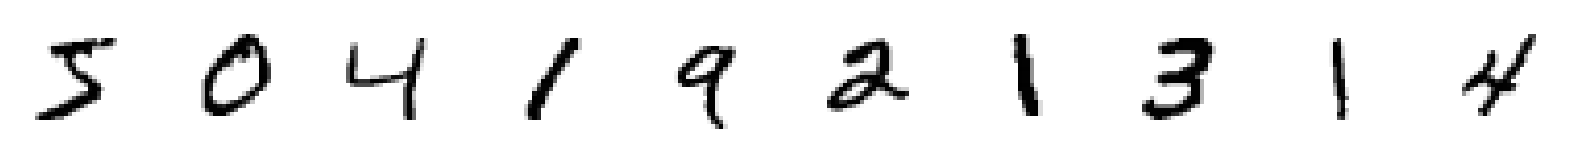

In [24]:
# Show some items of clothing from the training set
train_sample = sample_batch(x_train)
display(train_sample)

## 2. Build the EBM network <a name="train"></a>

In [25]:
ebm_input = layers.Input(shape=(IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
x = layers.Conv2D(
    16, kernel_size=5, strides=2, padding="same", activation=activations.swish
)(ebm_input)
x = layers.Conv2D(
    32, kernel_size=3, strides=2, padding="same", activation=activations.swish
)(x)
x = layers.Conv2D(
    64, kernel_size=3, strides=2, padding="same", activation=activations.swish
)(x)
x = layers.Conv2D(
    64, kernel_size=3, strides=2, padding="same", activation=activations.swish
)(x)
x = layers.Flatten()(x)
x = layers.Dense(64, activation=activations.swish)(x)
ebm_output = layers.Dense(1)(x)
model = models.Model(ebm_input, ebm_output)
model.summary()

Model: "functional_1"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 32, 32, 1)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_4 (Conv2D)               │ (None, 16, 16, 16)     │           416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_5 (Conv2D)               │ (None, 8, 8, 32)       │         4,640 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_6 (Conv2D)               │ (None, 4, 4, 64)       │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 2, 2, 64)       │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 64)             │        16,448 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 76,993 (300.75 KB)

 Trainable params: 76,993 (300.75 KB)

 Non-trainable params: 0 (0.00 B)

In [26]:
if LOAD_MODEL:
    if os.path.exists("./models/model.weights.h5"):
        model.load_weights("./models/model.weights.h5")
    elif os.path.exists("./models/model.h5"):
        try:
            model.load_weights("./models/model.h5")
        except Exception:
            model.load_weights("./models/model.weights.h5")


## 2. Set up a Langevin sampler function <a name="sampler"></a>

In [27]:
# Function to generate samples using Langevin Dynamics
def generate_samples(
    model, inp_imgs, steps, step_size, noise, return_img_per_step=False
):
    imgs_per_step = []
    for _ in range(steps):
        inp_imgs += tf.random.normal(inp_imgs.shape, mean=0, stddev=noise)
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)
        with tf.GradientTape() as tape:
            tape.watch(inp_imgs)
            out_score = model(inp_imgs)
        grads = tape.gradient(out_score, inp_imgs)
        grads = tf.clip_by_value(grads, -GRADIENT_CLIP, GRADIENT_CLIP)
        inp_imgs += step_size * grads
        inp_imgs = tf.clip_by_value(inp_imgs, -1.0, 1.0)
        if return_img_per_step:
            imgs_per_step.append(inp_imgs)
    if return_img_per_step:
        return tf.stack(imgs_per_step, axis=0)
    else:
        return inp_imgs

## 3. Set up a buffer to store examples <a name="buffer"></a>

In [28]:
class Buffer:
    def __init__(self, model):
        super().__init__()
        self.model = model
        self.examples = [
            tf.random.uniform(shape=(1, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2
            - 1
            for _ in range(BATCH_SIZE)
        ]

    def sample_new_exmps(self, steps, step_size, noise):
        n_new = np.random.binomial(BATCH_SIZE, 0.05)
        rand_imgs = (
            tf.random.uniform((n_new, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
        )
        old_imgs = tf.concat(
            random.choices(self.examples, k=BATCH_SIZE - n_new), axis=0
        )
        inp_imgs = tf.concat([rand_imgs, old_imgs], axis=0)
        inp_imgs = generate_samples(
            self.model, inp_imgs, steps=steps, step_size=step_size, noise=noise
        )
        self.examples = tf.split(inp_imgs, BATCH_SIZE, axis=0) + self.examples
        self.examples = self.examples[:BUFFER_SIZE]
        return inp_imgs

In [29]:
class EBM(models.Model):
    def __init__(self):
        super(EBM, self).__init__()
        self.model = model
        self.buffer = Buffer(self.model)
        self.alpha = ALPHA
        self.built = True
        self.loss_metric = metrics.Mean(name="loss")
        self.reg_loss_metric = metrics.Mean(name="reg")
        self.cdiv_loss_metric = metrics.Mean(name="cdiv")
        self.real_out_metric = metrics.Mean(name="real")
        self.fake_out_metric = metrics.Mean(name="fake")

    @property
    def metrics(self):
        return [
            self.loss_metric,
            self.reg_loss_metric,
            self.cdiv_loss_metric,
            self.real_out_metric,
            self.fake_out_metric,
        ]

    def train_step(self, real_imgs):
        real_imgs += tf.random.normal(
            shape=tf.shape(real_imgs), mean=0, stddev=NOISE
        )
        real_imgs = tf.clip_by_value(real_imgs, -1.0, 1.0)
        fake_imgs = self.buffer.sample_new_exmps(
            steps=STEPS, step_size=STEP_SIZE, noise=NOISE
        )
        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        with tf.GradientTape() as training_tape:
            real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
            cdiv_loss = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(
                real_out, axis=0
            )
            reg_loss = self.alpha * tf.reduce_mean(
                real_out**2 + fake_out**2, axis=0
            )
            loss = cdiv_loss + reg_loss
        grads = training_tape.gradient(loss, self.model.trainable_variables)
        self.optimizer.apply_gradients(
            zip(grads, self.model.trainable_variables)
        )
        self.loss_metric.update_state(loss)
        self.reg_loss_metric.update_state(reg_loss)
        self.cdiv_loss_metric.update_state(cdiv_loss)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics}

    def test_step(self, real_imgs):
        batch_size = real_imgs.shape[0]
        fake_imgs = (
            tf.random.uniform((batch_size, IMAGE_SIZE, IMAGE_SIZE, CHANNELS))
            * 2
            - 1
        )
        inp_imgs = tf.concat([real_imgs, fake_imgs], axis=0)
        real_out, fake_out = tf.split(self.model(inp_imgs), 2, axis=0)
        cdiv = tf.reduce_mean(fake_out, axis=0) - tf.reduce_mean(
            real_out, axis=0
        )
        self.cdiv_loss_metric.update_state(cdiv)
        self.real_out_metric.update_state(tf.reduce_mean(real_out, axis=0))
        self.fake_out_metric.update_state(tf.reduce_mean(fake_out, axis=0))
        return {m.name: m.result() for m in self.metrics[2:]}


In [30]:
ebm = EBM()

## 3. Train the EBM network <a name="train"></a>

In [31]:
# Compile and train the model
ebm.compile(
    optimizer=optimizers.Adam(learning_rate=LEARNING_RATE), run_eagerly=True
)

In [32]:
# Create directories for output images, logs, and models
import os
os.makedirs("./output", exist_ok=True)
os.makedirs("./logs", exist_ok=True)
os.makedirs("./models", exist_ok=True)

tensorboard_callback = callbacks.TensorBoard(log_dir="./logs")


class ImageGenerator(callbacks.Callback):
    def __init__(self, num_img):
        self.num_img = num_img

    def on_epoch_end(self, epoch, logs=None):
        start_imgs = (
            np.random.uniform(
                size=(self.num_img, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)
            )
            * 2
            - 1
        )
        generated_images = generate_samples(
            ebm.model,
            start_imgs,
            steps=1000,
            step_size=STEP_SIZE,
            noise=NOISE,
            return_img_per_step=False,
        )
        generated_images = generated_images.numpy()
        display(
            generated_images,
            save_to="./output/generated_img_%03d.png" % (epoch),
        )

        example_images = tf.concat(
            random.choices(ebm.buffer.examples, k=10), axis=0
        )
        example_images = example_images.numpy()
        display(
            example_images, save_to="./output/example_img_%03d.png" % (epoch)
        )


image_generator_callback = ImageGenerator(num_img=10)


In [33]:
class SaveModel(callbacks.Callback):
    def on_epoch_end(self, epoch, logs=None):
        try:
            model.save_weights("./models/model.weights.h5")
        except Exception:
            model.save_weights("./models/model.h5")


save_model_callback = SaveModel()


Epoch 1/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0679 - fake: 0.2250 - loss: -0.0460 - real: 0.2929 - reg: 0.0219
Saved to ./output/generated_img_000.png


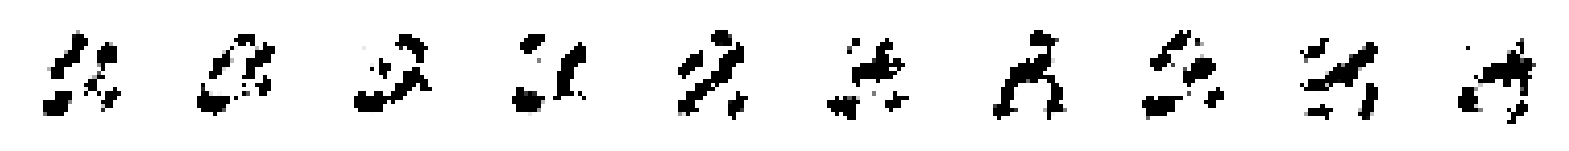


Saved to ./output/example_img_000.png


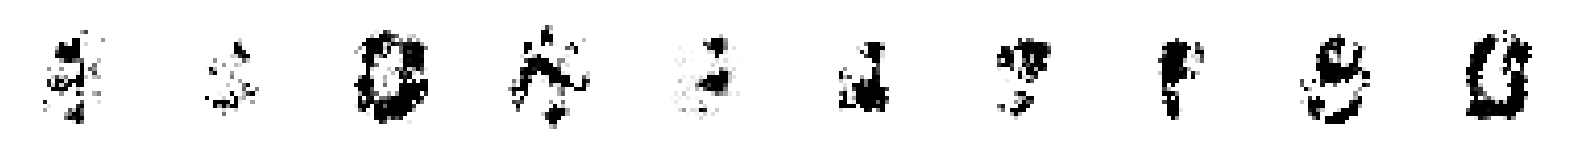

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: -0.0556 - fake: 0.1648 - loss: -0.0406 - real: 0.2204 - reg: 0.0150 - val_cdiv: -1.6309 - val_fake: -1.6855 - val_real: -0.0546
Epoch 2/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0023 - fake: 0.0131 - loss: 3.6031e-04 - real: 0.0154 - reg: 0.0027
Saved to ./output/generated_img_001.png


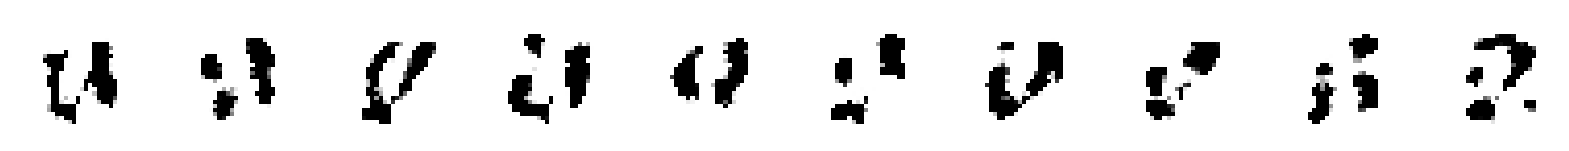


Saved to ./output/example_img_001.png


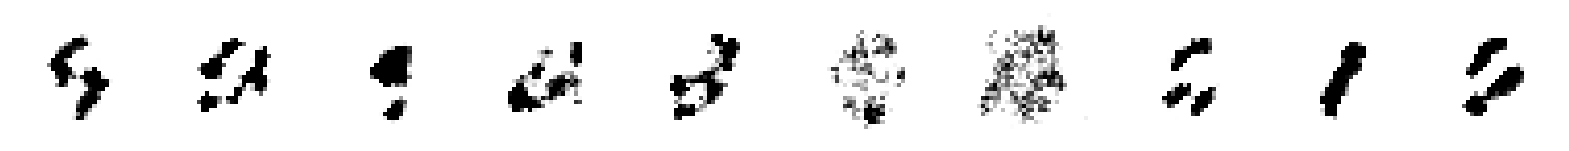

469/469 ━━━━━━━━━━━━━━━━━━━━ 766s 2s/step - cdiv: -0.0033 - fake: 0.0063 - loss: -0.0013 - real: 0.0096 - reg: 0.0021 - val_cdiv: -1.6906 - val_fake: -1.7581 - val_real: -0.0674
Epoch 3/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0036 - fake: 0.0039 - loss: -0.0022 - real: 0.0076 - reg: 0.0014
Saved to ./output/generated_img_002.png


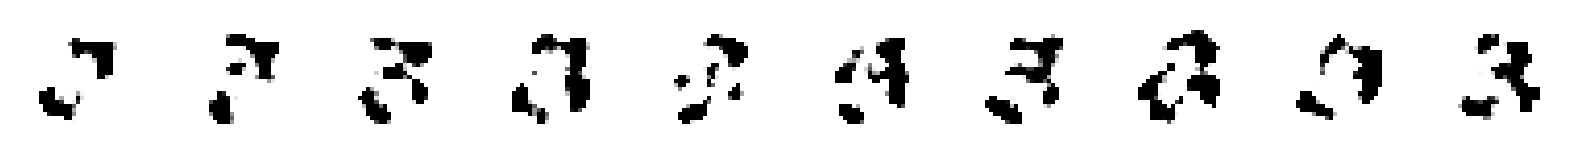


Saved to ./output/example_img_002.png


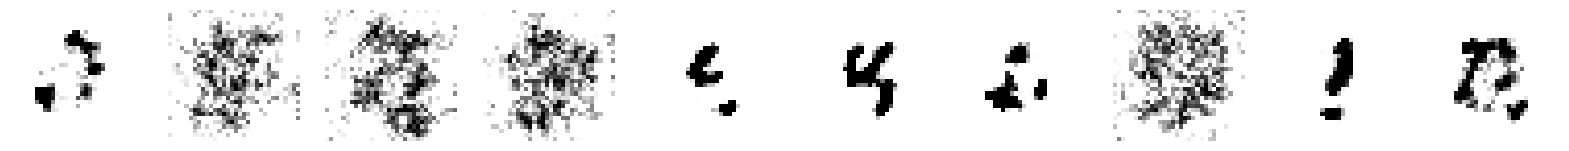

469/469 ━━━━━━━━━━━━━━━━━━━━ 768s 2s/step - cdiv: -0.0026 - fake: 0.0022 - loss: -0.0013 - real: 0.0048 - reg: 0.0013 - val_cdiv: -1.9291 - val_fake: -2.0075 - val_real: -0.0784
Epoch 4/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0020 - fake: 0.0041 - loss: -9.3321e-04 - real: 0.0061 - reg: 0.0011
Saved to ./output/generated_img_003.png


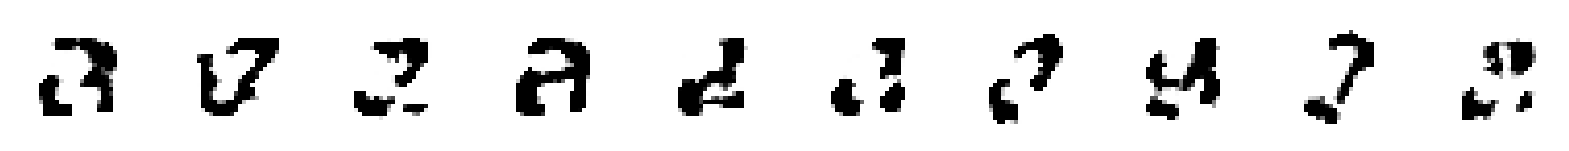


Saved to ./output/example_img_003.png


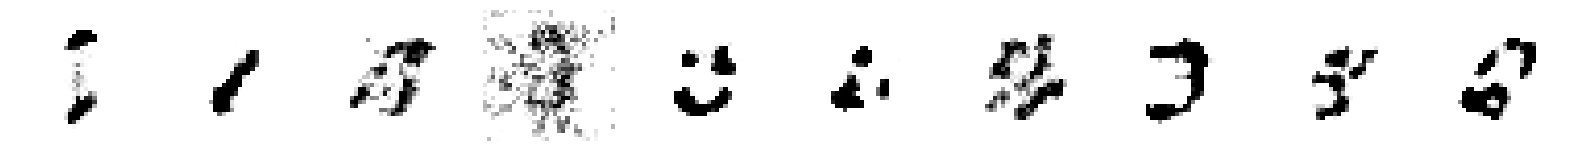

469/469 ━━━━━━━━━━━━━━━━━━━━ 756s 2s/step - cdiv: -0.0010 - fake: 0.0022 - loss: -2.3522e-04 - real: 0.0032 - reg: 7.8854e-04 - val_cdiv: -2.1807 - val_fake: -2.2226 - val_real: -0.0419
Epoch 5/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -8.0286e-04 - fake: 0.0028 - loss: -3.1142e-04 - real: 0.0036 - reg: 4.9143e-04
Saved to ./output/generated_img_004.png


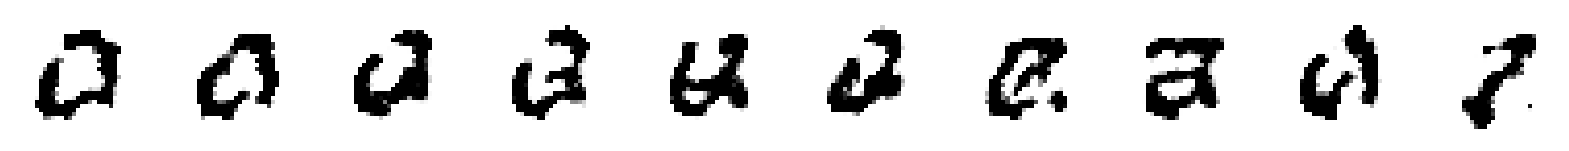


Saved to ./output/example_img_004.png


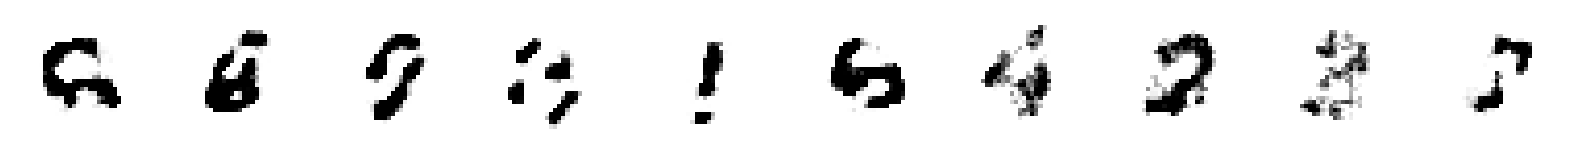

469/469 ━━━━━━━━━━━━━━━━━━━━ 759s 2s/step - cdiv: -7.3881e-04 - fake: 0.0021 - loss: -3.5969e-04 - real: 0.0028 - reg: 3.7912e-04 - val_cdiv: -2.5219 - val_fake: -2.5454 - val_real: -0.0235
Epoch 6/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 7.8790e-04 - fake: 9.5928e-04 - loss: 0.0011 - real: 1.7138e-04 - reg: 3.1375e-04
Saved to ./output/generated_img_005.png


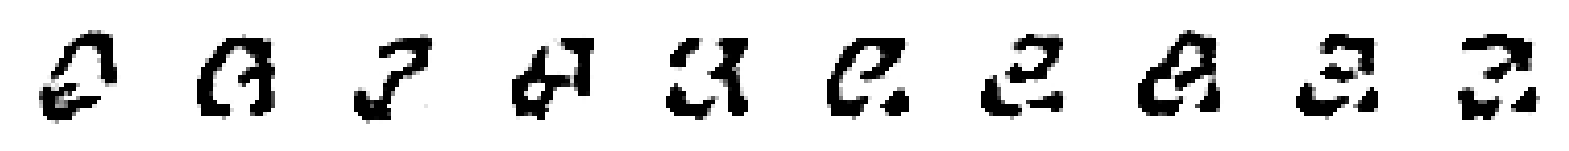


Saved to ./output/example_img_005.png


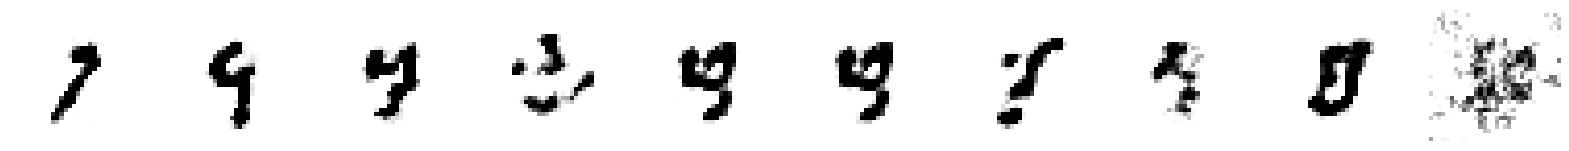

469/469 ━━━━━━━━━━━━━━━━━━━━ 746s 2s/step - cdiv: 2.7560e-04 - fake: 0.0015 - loss: 5.4153e-04 - real: 0.0012 - reg: 2.6593e-04 - val_cdiv: -2.6991 - val_fake: -2.7319 - val_real: -0.0327
Epoch 7/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.3513e-04 - fake: 6.4881e-04 - loss: 1.7210e-04 - real: 7.8394e-04 - reg: 3.0723e-04
Saved to ./output/generated_img_006.png


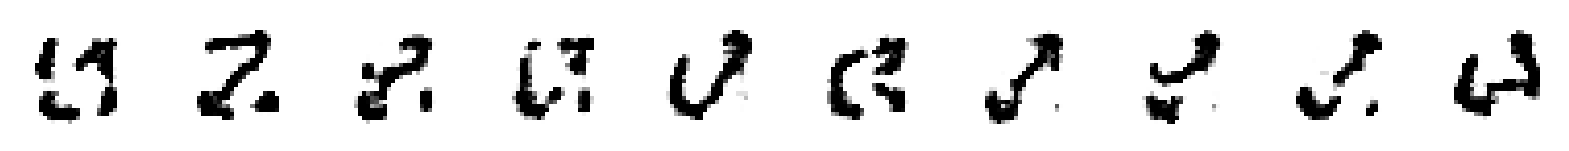


Saved to ./output/example_img_006.png


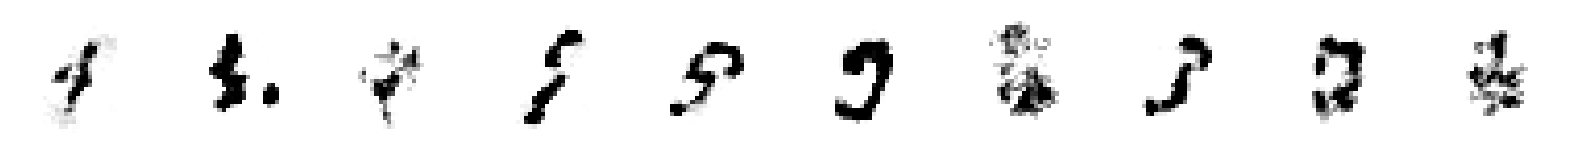

469/469 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - cdiv: -1.3578e-05 - fake: 0.0019 - loss: 2.6018e-04 - real: 0.0019 - reg: 2.7376e-04 - val_cdiv: -3.0540 - val_fake: -3.0586 - val_real: -0.0046
Epoch 8/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.7679e-04 - fake: -0.0011 - loss: -3.3874e-05 - real: -6.8535e-04 - reg: 3.4292e-04
Saved to ./output/generated_img_007.png


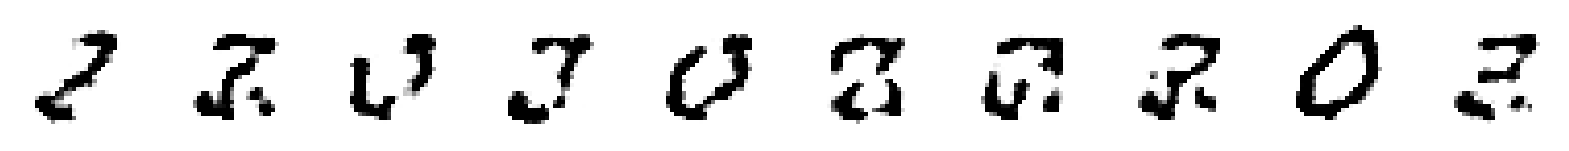


Saved to ./output/example_img_007.png


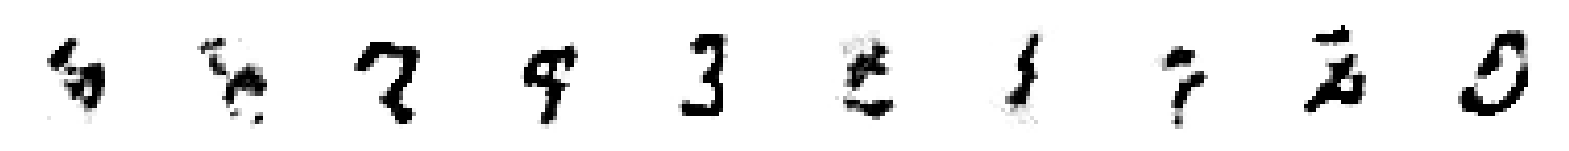

469/469 ━━━━━━━━━━━━━━━━━━━━ 747s 2s/step - cdiv: -6.0909e-04 - fake: 0.0014 - loss: -2.9530e-04 - real: 0.0020 - reg: 3.1379e-04 - val_cdiv: -3.5908 - val_fake: -3.5756 - val_real: 0.0152
Epoch 9/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -7.2497e-04 - fake: -0.0021 - loss: -2.7205e-04 - real: -0.0014 - reg: 4.5292e-04
Saved to ./output/generated_img_008.png


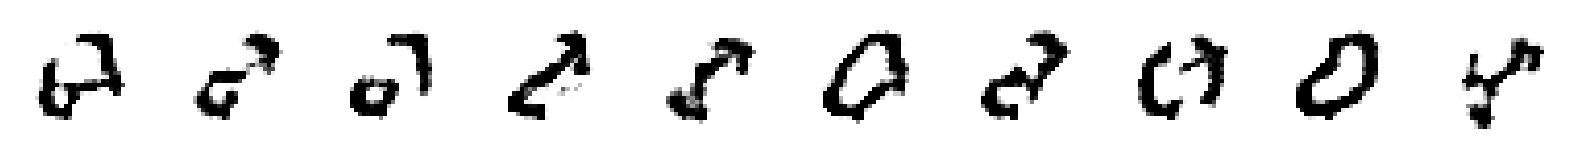


Saved to ./output/example_img_008.png


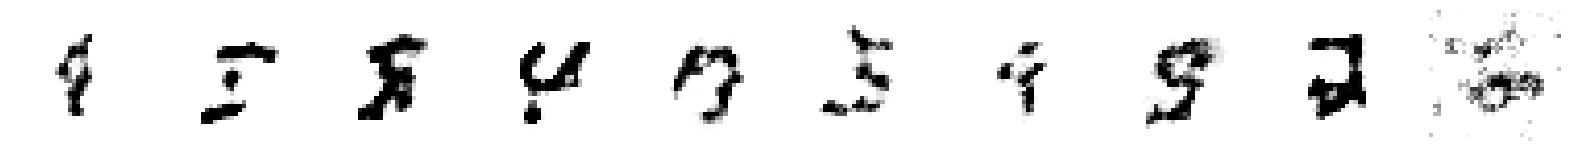

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: -4.8891e-04 - fake: 0.0011 - loss: -1.3804e-04 - real: 0.0016 - reg: 3.5087e-04 - val_cdiv: -3.9547 - val_fake: -3.9601 - val_real: -0.0055
Epoch 10/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.1027e-04 - fake: -0.0026 - loss: 2.2747e-06 - real: -0.0022 - reg: 4.1254e-04
Saved to ./output/generated_img_009.png


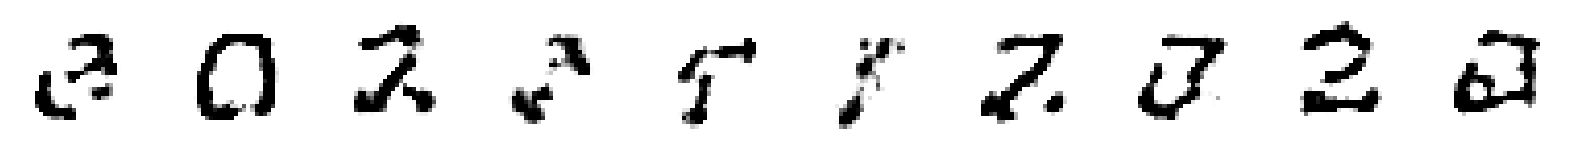


Saved to ./output/example_img_009.png


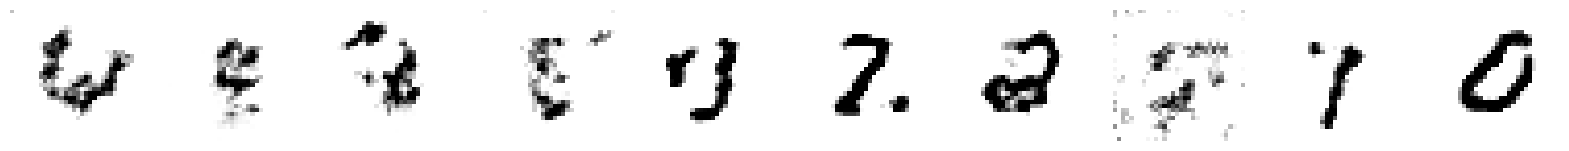

469/469 ━━━━━━━━━━━━━━━━━━━━ 770s 2s/step - cdiv: -2.7342e-04 - fake: 0.0011 - loss: 4.4145e-05 - real: 0.0014 - reg: 3.1756e-04 - val_cdiv: -4.3550 - val_fake: -4.3515 - val_real: 0.0034
Epoch 11/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.2189e-04 - fake: -0.0020 - loss: 1.3127e-05 - real: -0.0017 - reg: 3.3502e-04
Saved to ./output/generated_img_010.png


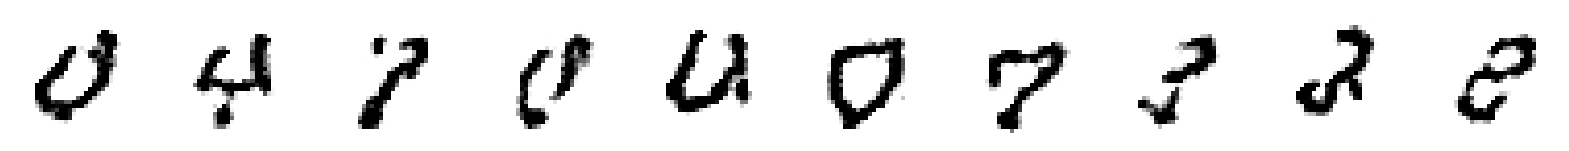


Saved to ./output/example_img_010.png


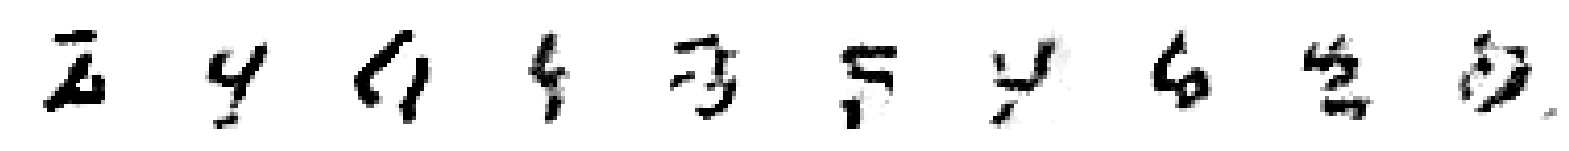

469/469 ━━━━━━━━━━━━━━━━━━━━ 795s 2s/step - cdiv: -2.6408e-04 - fake: 0.0010 - loss: 2.0720e-06 - real: 0.0013 - reg: 2.6615e-04 - val_cdiv: -4.7998 - val_fake: -4.7826 - val_real: 0.0171
Epoch 12/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.2713e-04 - fake: -0.0016 - loss: -1.1727e-04 - real: -0.0012 - reg: 3.0986e-04
Saved to ./output/generated_img_011.png


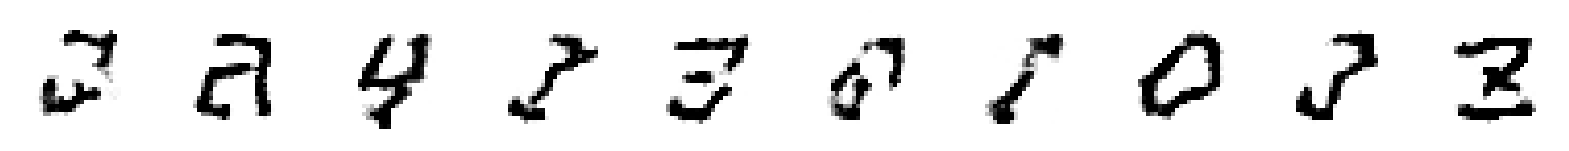


Saved to ./output/example_img_011.png


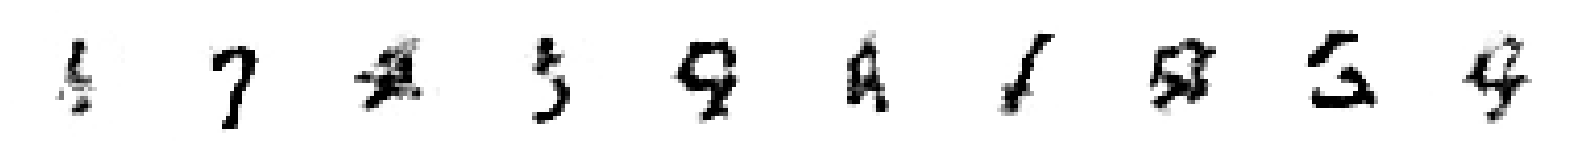

469/469 ━━━━━━━━━━━━━━━━━━━━ 795s 2s/step - cdiv: -8.7687e-05 - fake: 0.0010 - loss: 1.4414e-04 - real: 0.0011 - reg: 2.3183e-04 - val_cdiv: -5.1417 - val_fake: -5.1270 - val_real: 0.0147
Epoch 13/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -6.4119e-04 - fake: -0.0019 - loss: -3.8268e-04 - real: -0.0012 - reg: 2.5852e-04
Saved to ./output/generated_img_012.png


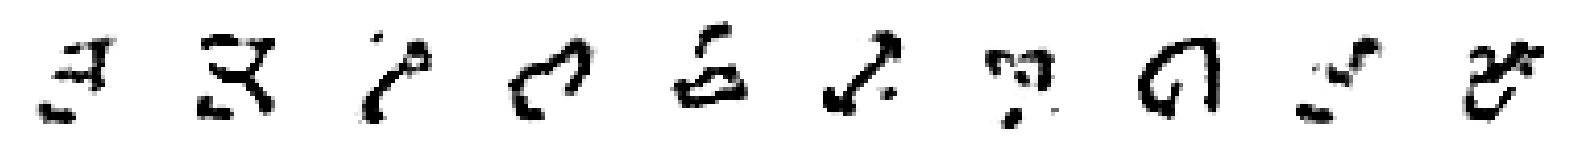


Saved to ./output/example_img_012.png


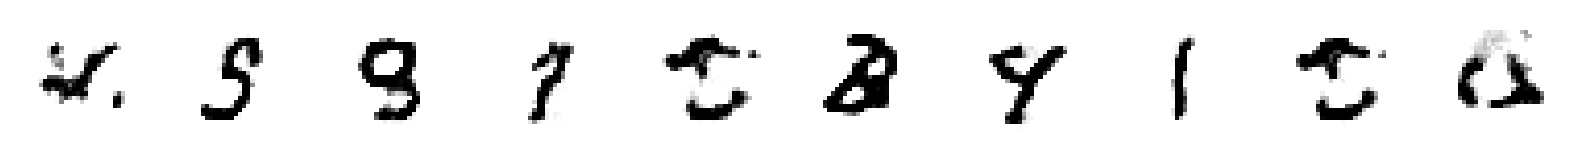

469/469 ━━━━━━━━━━━━━━━━━━━━ 802s 2s/step - cdiv: -3.5880e-04 - fake: 8.1727e-04 - loss: -1.4232e-04 - real: 0.0012 - reg: 2.1649e-04 - val_cdiv: -5.6083 - val_fake: -5.5987 - val_real: 0.0095
Epoch 14/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9324e-04 - fake: -0.0018 - loss: 2.0423e-05 - real: -0.0016 - reg: 2.1367e-04
Saved to ./output/generated_img_013.png


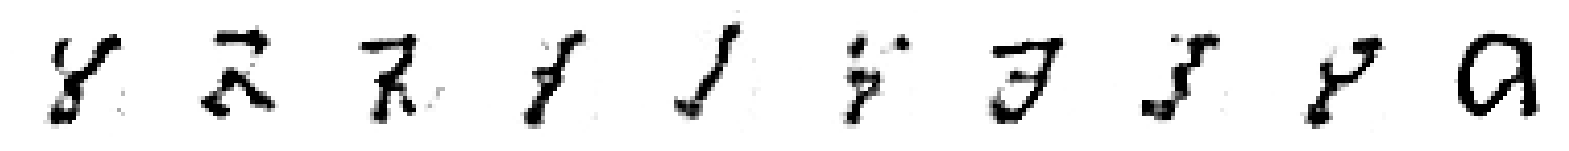


Saved to ./output/example_img_013.png


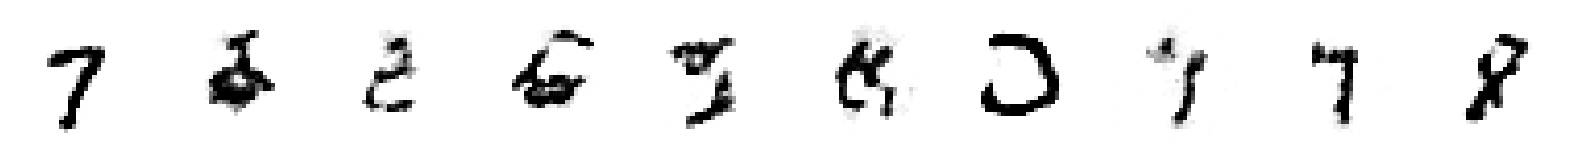

469/469 ━━━━━━━━━━━━━━━━━━━━ 804s 2s/step - cdiv: 1.0538e-04 - fake: 5.7120e-04 - loss: 2.9235e-04 - real: 4.6582e-04 - reg: 1.8698e-04 - val_cdiv: -5.8163 - val_fake: -5.8015 - val_real: 0.0148
Epoch 15/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.8906e-04 - fake: -8.0054e-04 - loss: -1.5942e-04 - real: -4.1148e-04 - reg: 2.2964e-04
Saved to ./output/generated_img_014.png


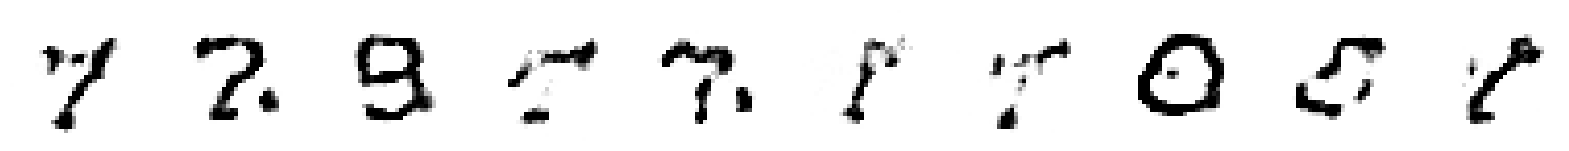


Saved to ./output/example_img_014.png


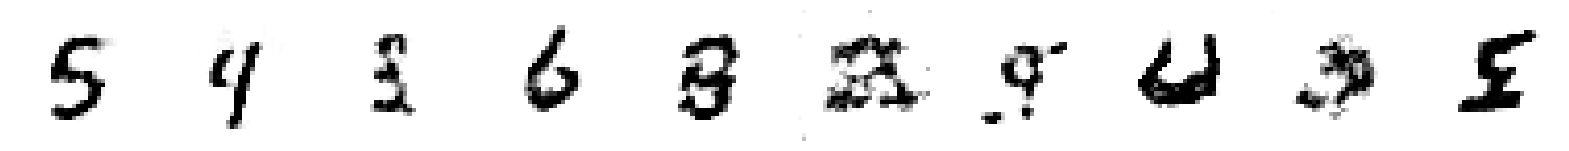

469/469 ━━━━━━━━━━━━━━━━━━━━ 804s 2s/step - cdiv: -1.5553e-04 - fake: 0.0011 - loss: 3.1556e-05 - real: 0.0012 - reg: 1.8709e-04 - val_cdiv: -6.1344 - val_fake: -6.1247 - val_real: 0.0097
Epoch 16/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.7266e-04 - fake: -0.0013 - loss: -2.6127e-04 - real: -7.9729e-04 - reg: 2.1140e-04
Saved to ./output/generated_img_015.png


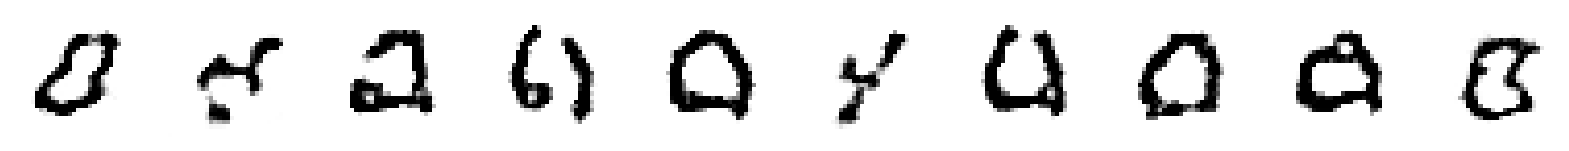


Saved to ./output/example_img_015.png


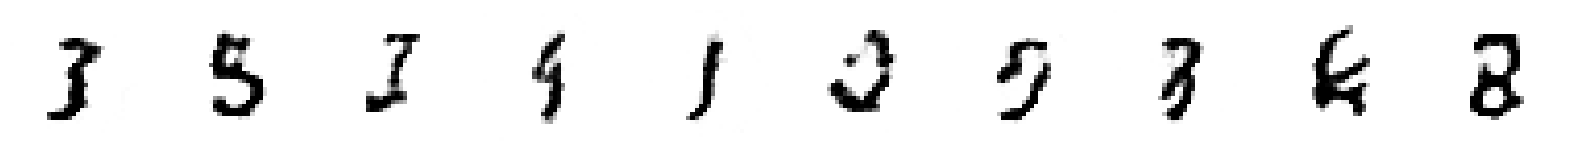

469/469 ━━━━━━━━━━━━━━━━━━━━ 787s 2s/step - cdiv: -3.7275e-04 - fake: 6.1794e-04 - loss: -2.0331e-04 - real: 9.9069e-04 - reg: 1.6944e-04 - val_cdiv: -6.5467 - val_fake: -6.5406 - val_real: 0.0061
Epoch 17/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.6559e-04 - fake: -0.0014 - loss: -2.2540e-04 - real: -9.6237e-04 - reg: 2.4019e-04
Saved to ./output/generated_img_016.png


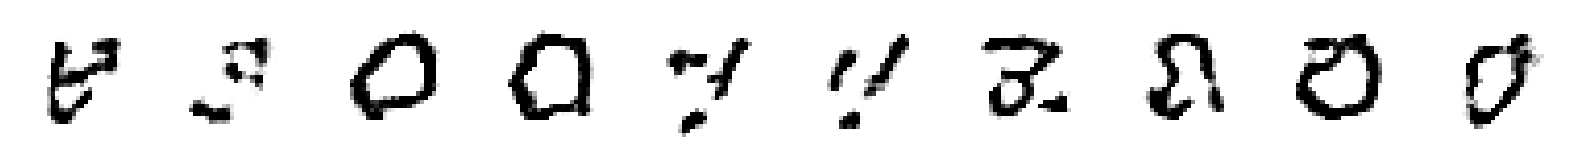


Saved to ./output/example_img_016.png


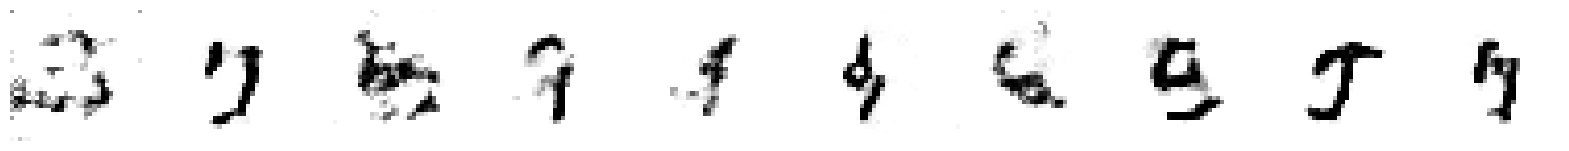

469/469 ━━━━━━━━━━━━━━━━━━━━ 792s 2s/step - cdiv: -9.3446e-06 - fake: 9.3631e-04 - loss: 1.7446e-04 - real: 9.4565e-04 - reg: 1.8381e-04 - val_cdiv: -6.8753 - val_fake: -6.8652 - val_real: 0.0101
Epoch 18/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7342e-04 - fake: -0.0010 - loss: 2.0337e-05 - real: -8.3951e-04 - reg: 1.9376e-04
Saved to ./output/generated_img_017.png


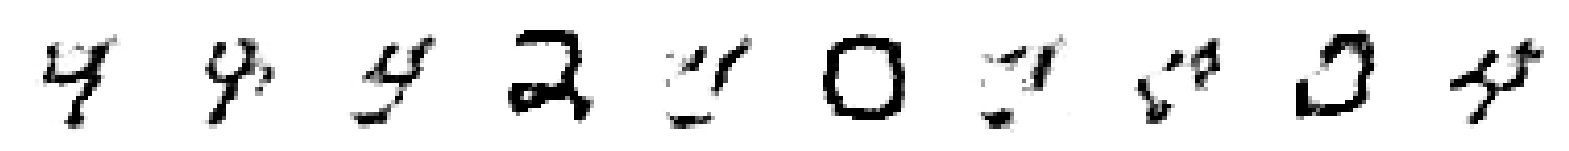


Saved to ./output/example_img_017.png


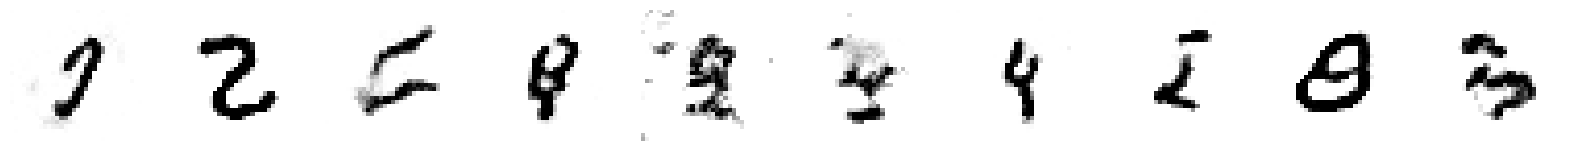

469/469 ━━━━━━━━━━━━━━━━━━━━ 790s 2s/step - cdiv: 5.5697e-05 - fake: 9.2217e-04 - loss: 2.0330e-04 - real: 8.6648e-04 - reg: 1.4760e-04 - val_cdiv: -7.2013 - val_fake: -7.1868 - val_real: 0.0145
Epoch 19/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.5065e-04 - fake: -5.7643e-04 - loss: -2.0238e-04 - real: -2.2578e-04 - reg: 1.4827e-04
Saved to ./output/generated_img_018.png


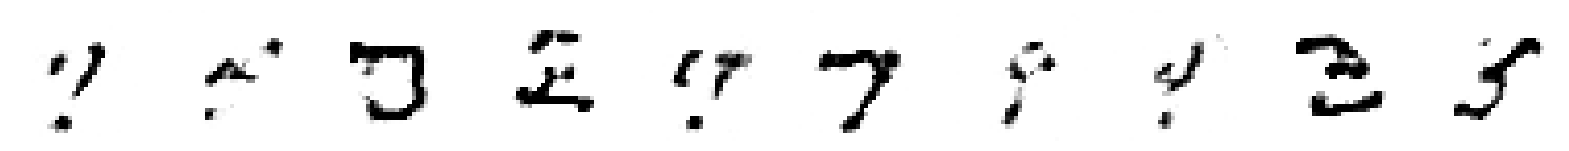


Saved to ./output/example_img_018.png


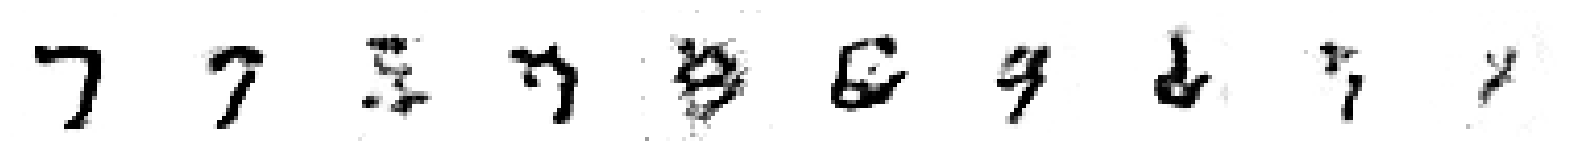

469/469 ━━━━━━━━━━━━━━━━━━━━ 789s 2s/step - cdiv: -8.2292e-05 - fake: 4.5519e-04 - loss: 4.7591e-05 - real: 5.3748e-04 - reg: 1.2988e-04 - val_cdiv: -7.4756 - val_fake: -7.4744 - val_real: 0.0012
Epoch 20/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.3779e-04 - fake: -6.3364e-04 - loss: -1.8370e-04 - real: -2.9585e-04 - reg: 1.5408e-04
Saved to ./output/generated_img_019.png


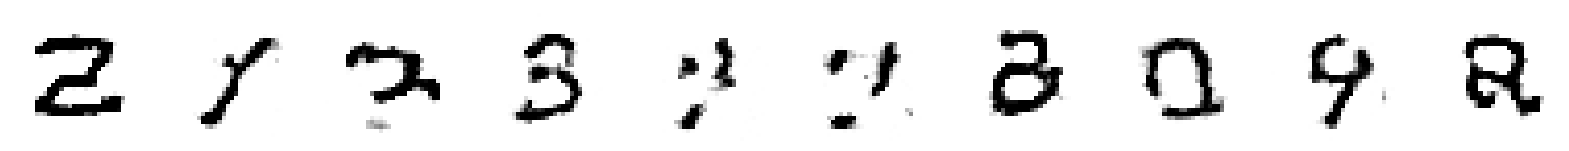


Saved to ./output/example_img_019.png


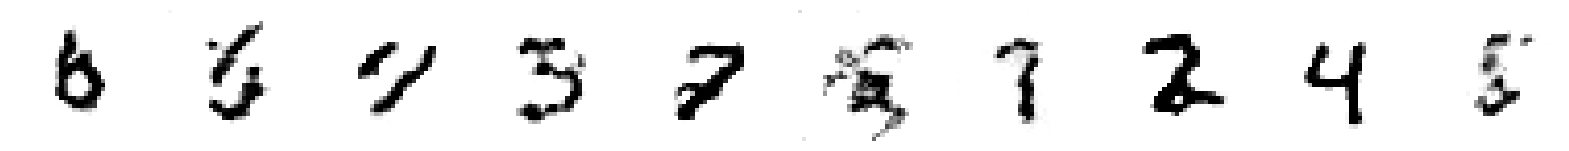

469/469 ━━━━━━━━━━━━━━━━━━━━ 771s 2s/step - cdiv: 6.4128e-05 - fake: 6.3700e-04 - loss: 2.0514e-04 - real: 5.7287e-04 - reg: 1.4101e-04 - val_cdiv: -7.7224 - val_fake: -7.7099 - val_real: 0.0124
Epoch 21/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -7.1085e-04 - fake: -4.7129e-04 - loss: -5.6122e-04 - real: 2.3956e-04 - reg: 1.4963e-04
Saved to ./output/generated_img_020.png


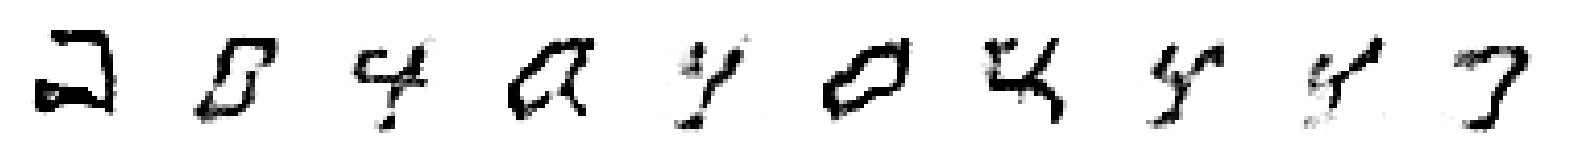


Saved to ./output/example_img_020.png


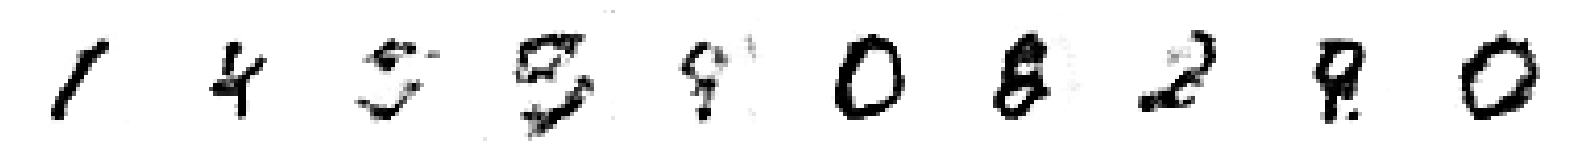

469/469 ━━━━━━━━━━━━━━━━━━━━ 769s 2s/step - cdiv: -1.6838e-04 - fake: 5.5896e-04 - loss: -3.2761e-05 - real: 7.2734e-04 - reg: 1.3562e-04 - val_cdiv: -8.1393 - val_fake: -8.1289 - val_real: 0.0105
Epoch 22/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.7762e-04 - fake: -8.8007e-04 - loss: -1.1755e-04 - real: -6.0245e-04 - reg: 1.6007e-04
Saved to ./output/generated_img_021.png


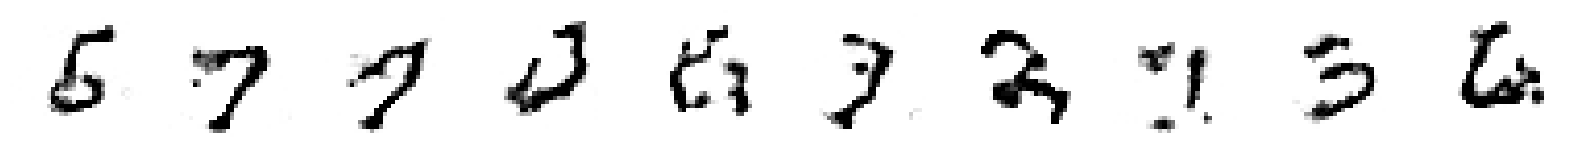


Saved to ./output/example_img_021.png


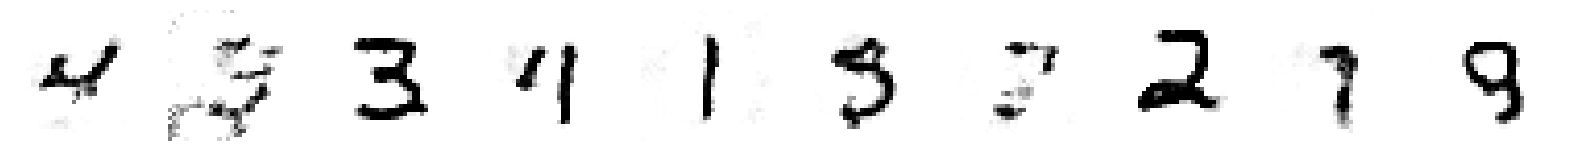

469/469 ━━━━━━━━━━━━━━━━━━━━ 769s 2s/step - cdiv: 1.5269e-05 - fake: 6.8206e-04 - loss: 1.5185e-04 - real: 6.6679e-04 - reg: 1.3658e-04 - val_cdiv: -8.3558 - val_fake: -8.3437 - val_real: 0.0121
Epoch 23/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.9627e-04 - fake: -6.8117e-04 - loss: -1.2465e-04 - real: -3.8490e-04 - reg: 1.7162e-04
Saved to ./output/generated_img_022.png


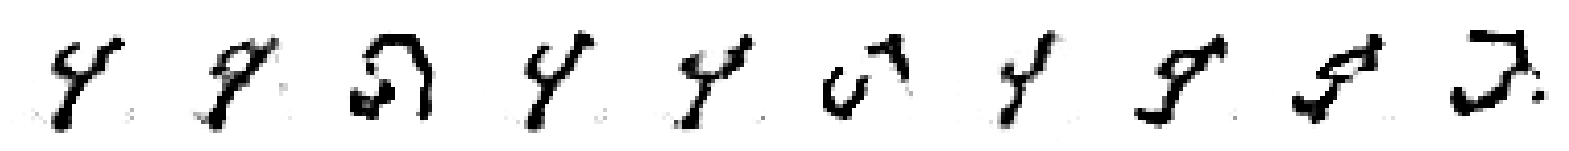


Saved to ./output/example_img_022.png


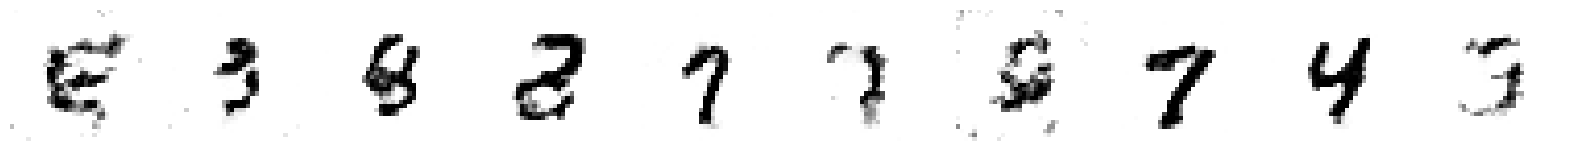

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: -5.8755e-05 - fake: 3.9359e-04 - loss: 7.6317e-05 - real: 4.5235e-04 - reg: 1.3507e-04 - val_cdiv: -8.6830 - val_fake: -8.6668 - val_real: 0.0163
Epoch 24/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.0530e-05 - fake: 9.3832e-05 - loss: 8.8466e-05 - real: 1.3436e-04 - reg: 1.2900e-04
Saved to ./output/generated_img_023.png


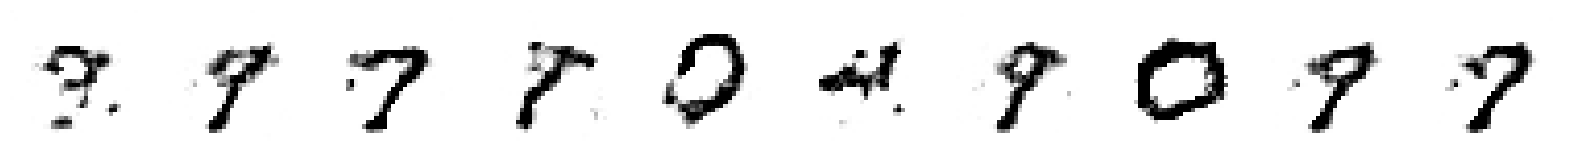


Saved to ./output/example_img_023.png


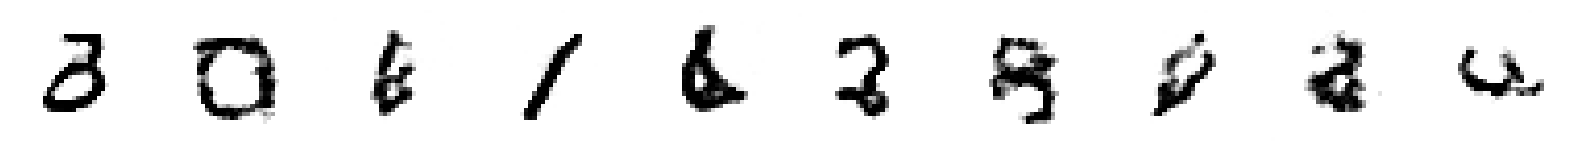

469/469 ━━━━━━━━━━━━━━━━━━━━ 765s 2s/step - cdiv: 2.0316e-04 - fake: 7.1981e-04 - loss: 3.0759e-04 - real: 5.1666e-04 - reg: 1.0443e-04 - val_cdiv: -8.9684 - val_fake: -8.9531 - val_real: 0.0153
Epoch 25/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.5800e-04 - fake: 2.0258e-05 - loss: -1.3913e-04 - real: 2.7825e-04 - reg: 1.1887e-04
Saved to ./output/generated_img_024.png


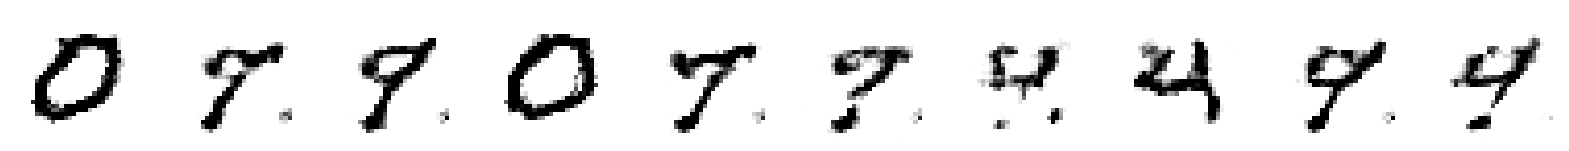


Saved to ./output/example_img_024.png


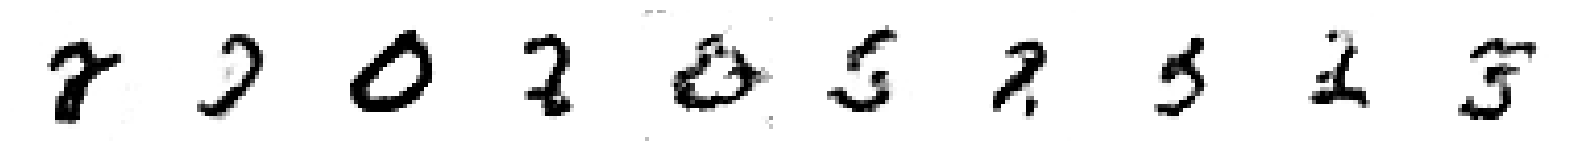

469/469 ━━━━━━━━━━━━━━━━━━━━ 776s 2s/step - cdiv: -2.0321e-04 - fake: 2.9247e-04 - loss: -9.6228e-05 - real: 4.9568e-04 - reg: 1.0698e-04 - val_cdiv: -9.4789 - val_fake: -9.4598 - val_real: 0.0192
Epoch 26/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7790e-04 - fake: 3.6198e-04 - loss: -2.1948e-05 - real: 5.3988e-04 - reg: 1.5595e-04
Saved to ./output/generated_img_025.png


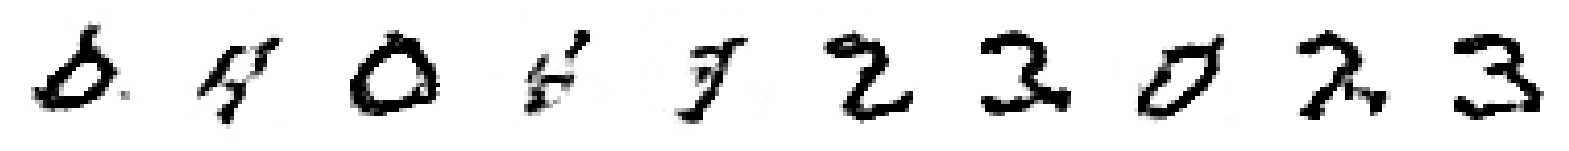


Saved to ./output/example_img_025.png


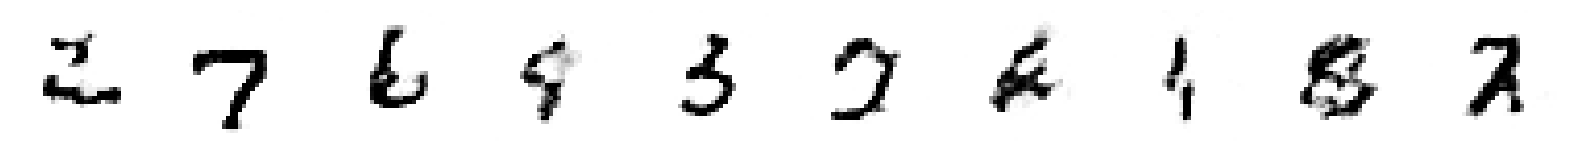

469/469 ━━━━━━━━━━━━━━━━━━━━ 773s 2s/step - cdiv: 4.0118e-05 - fake: 6.8257e-04 - loss: 1.6136e-04 - real: 6.4245e-04 - reg: 1.2124e-04 - val_cdiv: -9.7386 - val_fake: -9.7287 - val_real: 0.0099
Epoch 27/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.5871e-04 - fake: 4.9455e-05 - loss: -1.1214e-04 - real: 3.0816e-04 - reg: 1.4657e-04
Saved to ./output/generated_img_026.png


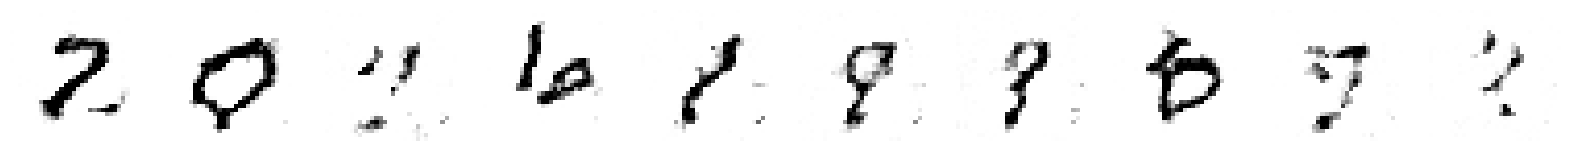


Saved to ./output/example_img_026.png


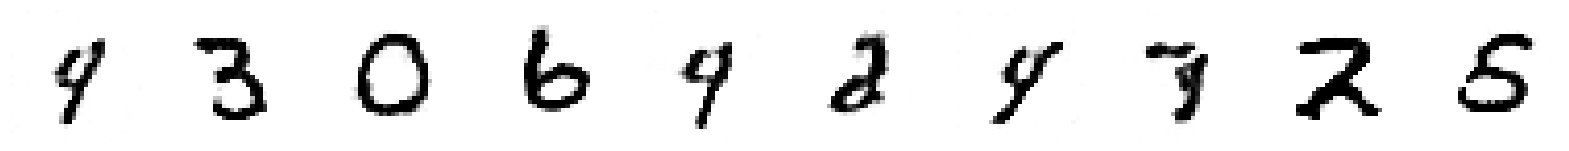

469/469 ━━━━━━━━━━━━━━━━━━━━ 776s 2s/step - cdiv: 1.1892e-04 - fake: 6.0544e-04 - loss: 2.4195e-04 - real: 4.8652e-04 - reg: 1.2303e-04 - val_cdiv: -10.0893 - val_fake: -10.0755 - val_real: 0.0138
Epoch 28/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.5594e-04 - fake: 1.3543e-04 - loss: -1.1542e-04 - real: 3.9137e-04 - reg: 1.4052e-04
Saved to ./output/generated_img_027.png


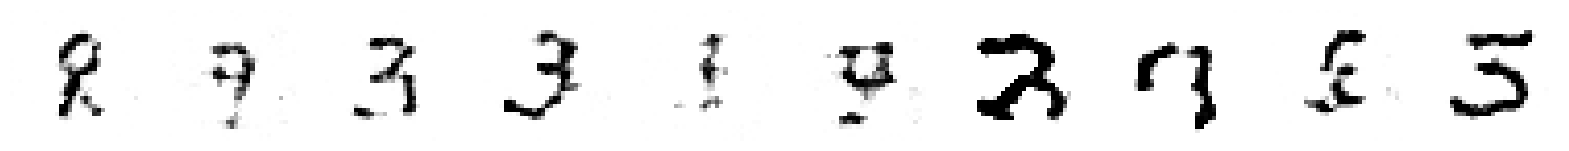


Saved to ./output/example_img_027.png


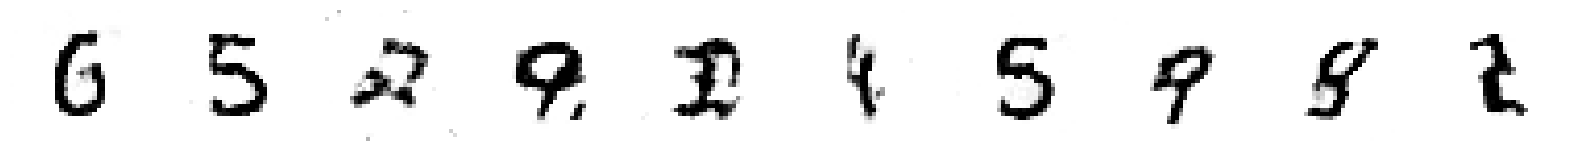

469/469 ━━━━━━━━━━━━━━━━━━━━ 773s 2s/step - cdiv: 7.3388e-05 - fake: 6.7129e-04 - loss: 1.9139e-04 - real: 5.9790e-04 - reg: 1.1801e-04 - val_cdiv: -10.2934 - val_fake: -10.2860 - val_real: 0.0074
Epoch 29/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 4.6970e-05 - fake: 2.7557e-04 - loss: 1.5004e-04 - real: 2.2860e-04 - reg: 1.0307e-04
Saved to ./output/generated_img_028.png


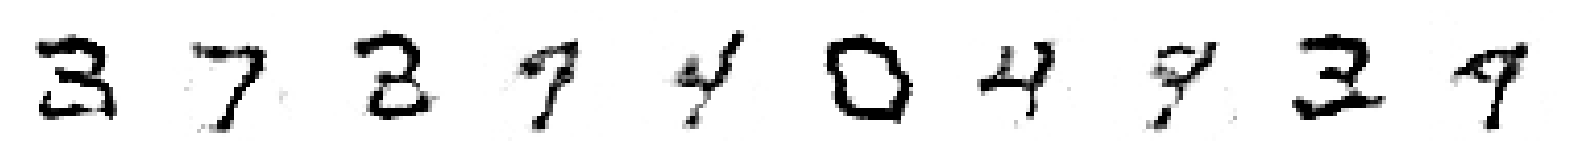


Saved to ./output/example_img_028.png


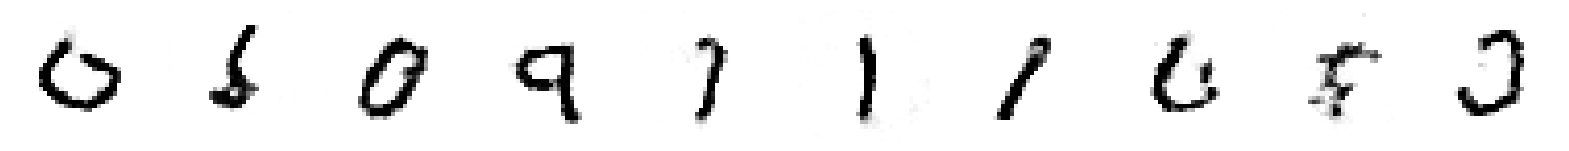

469/469 ━━━━━━━━━━━━━━━━━━━━ 762s 2s/step - cdiv: 1.1926e-04 - fake: 6.1193e-04 - loss: 2.1717e-04 - real: 4.9267e-04 - reg: 9.7908e-05 - val_cdiv: -10.7426 - val_fake: -10.7296 - val_real: 0.0130
Epoch 30/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9505e-04 - fake: 4.2487e-04 - loss: -5.1690e-05 - real: 6.1992e-04 - reg: 1.4336e-04
Saved to ./output/generated_img_029.png


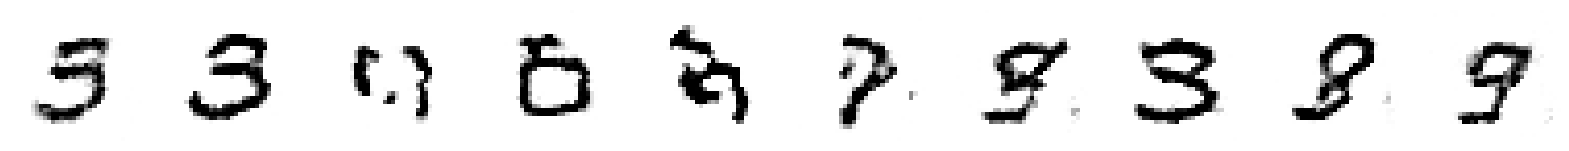


Saved to ./output/example_img_029.png


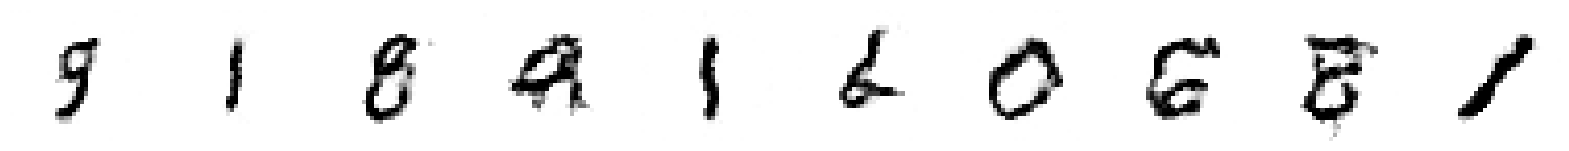

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: -4.9044e-05 - fake: 4.1722e-04 - loss: 5.7968e-05 - real: 4.6627e-04 - reg: 1.0701e-04 - val_cdiv: -10.8822 - val_fake: -10.8764 - val_real: 0.0057
Epoch 31/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7242e-04 - fake: 3.2043e-04 - loss: -5.3857e-05 - real: 4.9285e-04 - reg: 1.1856e-04
Saved to ./output/generated_img_030.png


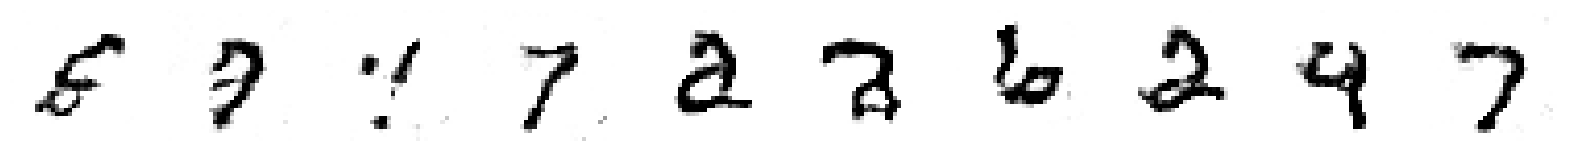


Saved to ./output/example_img_030.png


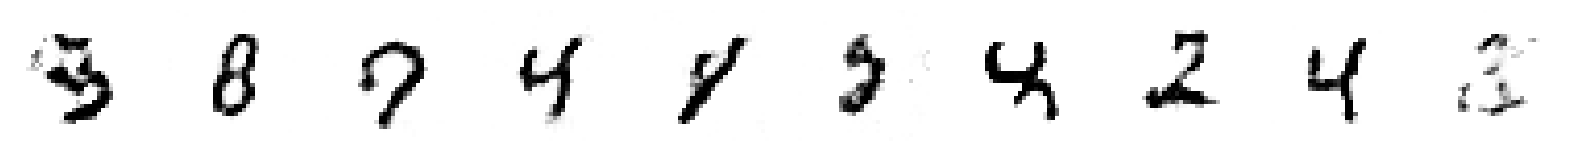

469/469 ━━━━━━━━━━━━━━━━━━━━ 764s 2s/step - cdiv: 2.9428e-05 - fake: 4.9885e-04 - loss: 1.4396e-04 - real: 4.6942e-04 - reg: 1.1453e-04 - val_cdiv: -11.1041 - val_fake: -11.0897 - val_real: 0.0144
Epoch 32/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -9.6004e-06 - fake: 9.7156e-04 - loss: 1.2009e-04 - real: 9.8116e-04 - reg: 1.2969e-04
Saved to ./output/generated_img_031.png


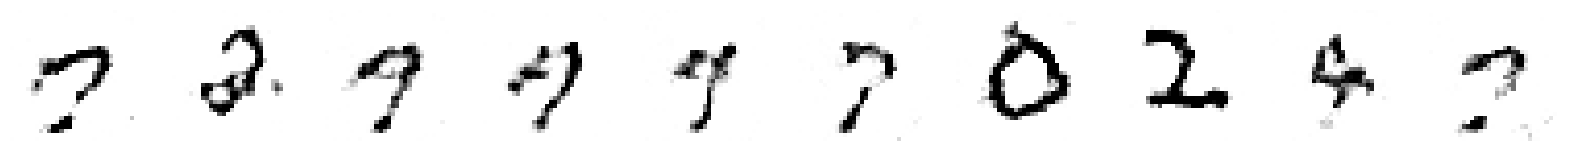


Saved to ./output/example_img_031.png


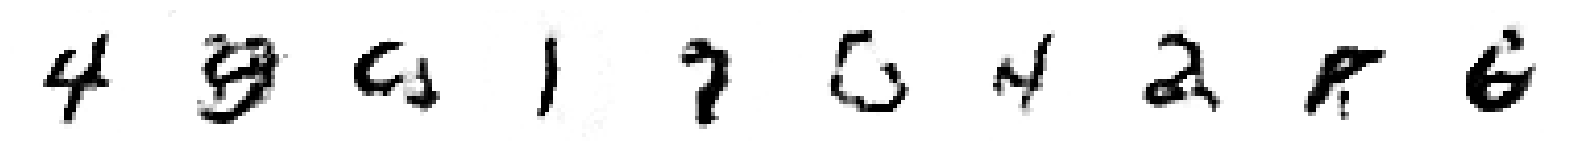

469/469 ━━━━━━━━━━━━━━━━━━━━ 761s 2s/step - cdiv: 8.2450e-05 - fake: 7.4621e-04 - loss: 1.9162e-04 - real: 6.6376e-04 - reg: 1.0917e-04 - val_cdiv: -11.4915 - val_fake: -11.4747 - val_real: 0.0168
Epoch 33/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 5.7321e-05 - fake: 5.0943e-04 - loss: 1.8193e-04 - real: 4.5210e-04 - reg: 1.2461e-04
Saved to ./output/generated_img_032.png


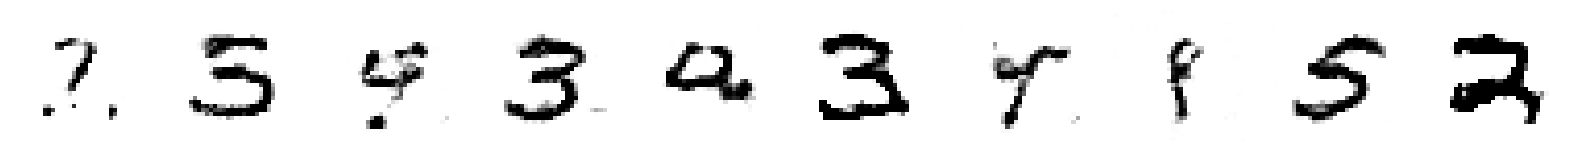


Saved to ./output/example_img_032.png


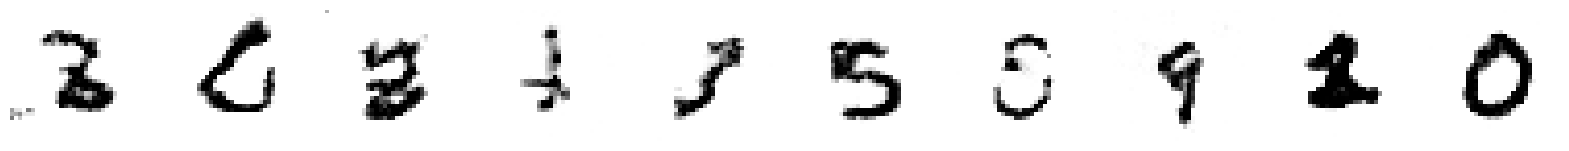

469/469 ━━━━━━━━━━━━━━━━━━━━ 759s 2s/step - cdiv: 6.7532e-05 - fake: 4.9394e-04 - loss: 1.7705e-04 - real: 4.2641e-04 - reg: 1.0952e-04 - val_cdiv: -11.7816 - val_fake: -11.7734 - val_real: 0.0082
Epoch 34/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.4165e-04 - fake: -4.4119e-05 - loss: -1.0521e-04 - real: 1.9753e-04 - reg: 1.3644e-04
Saved to ./output/generated_img_033.png


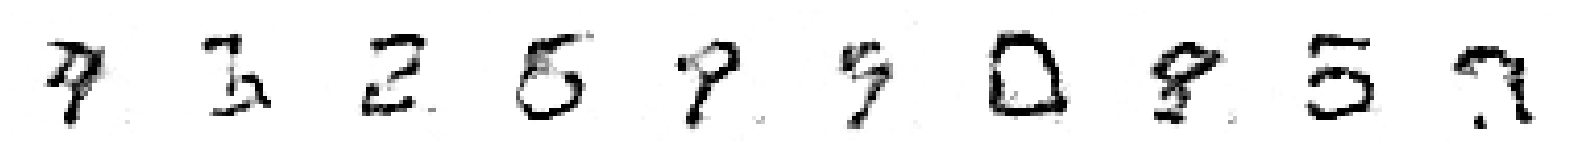


Saved to ./output/example_img_033.png


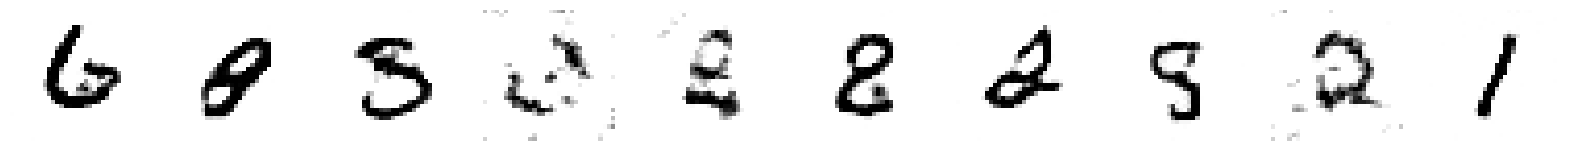

469/469 ━━━━━━━━━━━━━━━━━━━━ 753s 2s/step - cdiv: 1.8207e-04 - fake: 7.1419e-04 - loss: 2.8952e-04 - real: 5.3212e-04 - reg: 1.0745e-04 - val_cdiv: -12.0326 - val_fake: -12.0241 - val_real: 0.0085
Epoch 35/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.6420e-04 - fake: -3.1668e-04 - loss: -1.5391e-04 - real: -5.2484e-05 - reg: 1.1029e-04
Saved to ./output/generated_img_034.png


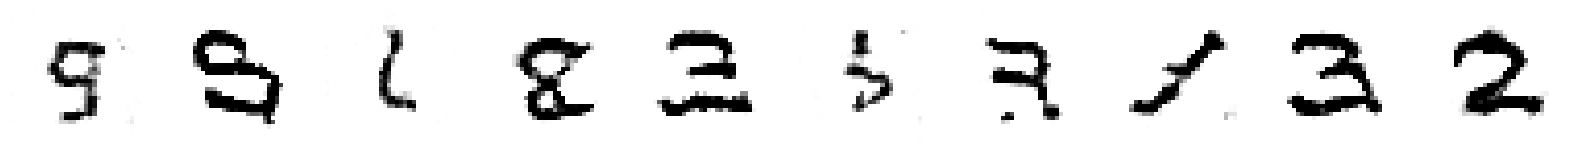


Saved to ./output/example_img_034.png


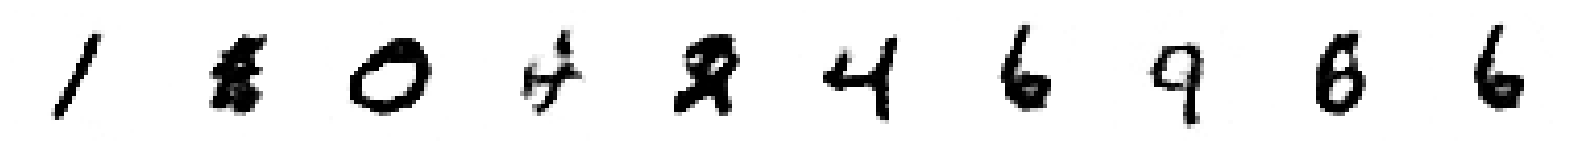

469/469 ━━━━━━━━━━━━━━━━━━━━ 754s 2s/step - cdiv: 2.3954e-05 - fake: 3.1812e-04 - loss: 1.3102e-04 - real: 2.9416e-04 - reg: 1.0707e-04 - val_cdiv: -12.2411 - val_fake: -12.2300 - val_real: 0.0112
Epoch 36/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -9.0117e-05 - fake: 3.5783e-04 - loss: 9.2169e-06 - real: 4.4795e-04 - reg: 9.9333e-05
Saved to ./output/generated_img_035.png


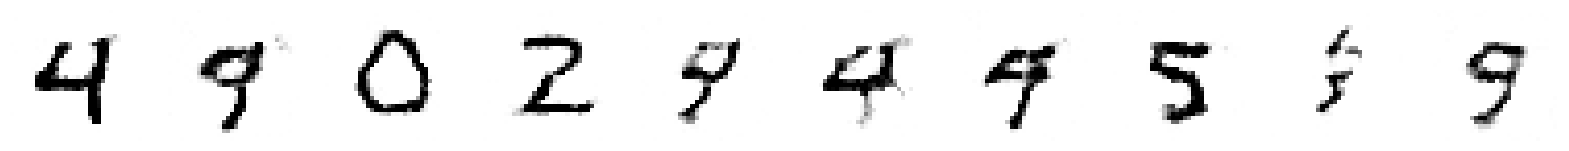


Saved to ./output/example_img_035.png


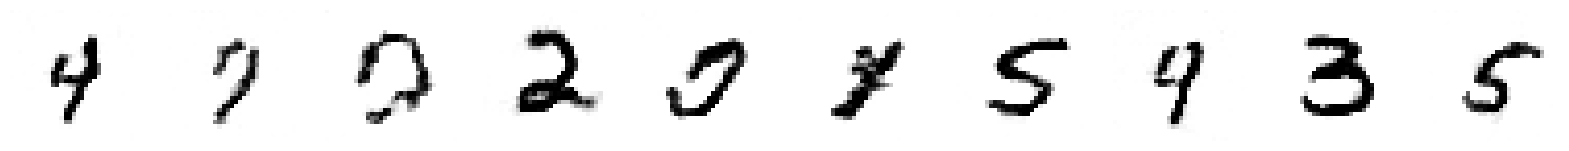

469/469 ━━━━━━━━━━━━━━━━━━━━ 755s 2s/step - cdiv: 3.0848e-05 - fake: 5.0728e-04 - loss: 1.2613e-04 - real: 4.7643e-04 - reg: 9.5284e-05 - val_cdiv: -12.7548 - val_fake: -12.7488 - val_real: 0.0060
Epoch 37/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.8974e-04 - fake: 2.9898e-04 - loss: -1.5620e-04 - real: 5.8872e-04 - reg: 1.3354e-04
Saved to ./output/generated_img_036.png


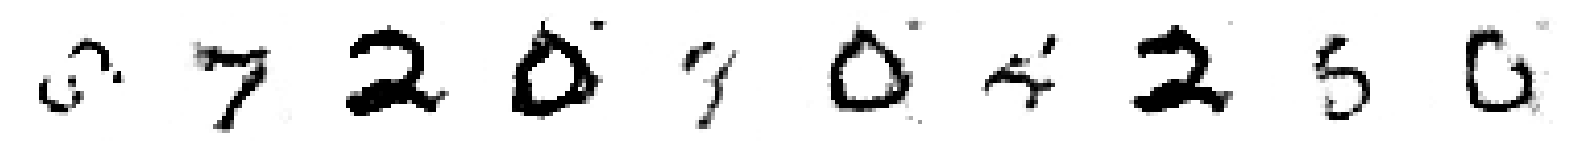


Saved to ./output/example_img_036.png


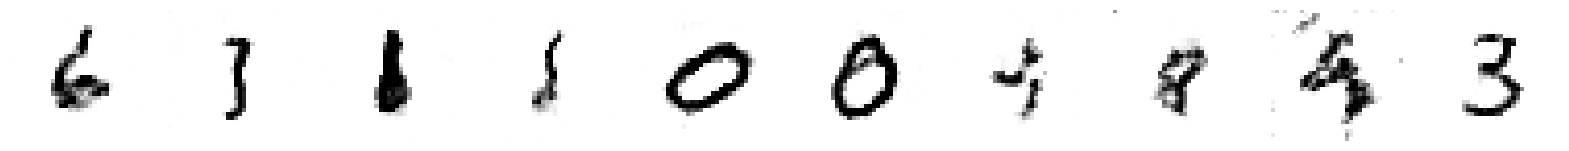

469/469 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - cdiv: 6.3278e-05 - fake: 4.3877e-04 - loss: 1.8211e-04 - real: 3.7549e-04 - reg: 1.1883e-04 - val_cdiv: -12.9285 - val_fake: -12.9218 - val_real: 0.0067
Epoch 38/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.2954e-04 - fake: 4.6813e-04 - loss: -2.9328e-05 - real: 5.9766e-04 - reg: 1.0021e-04
Saved to ./output/generated_img_037.png


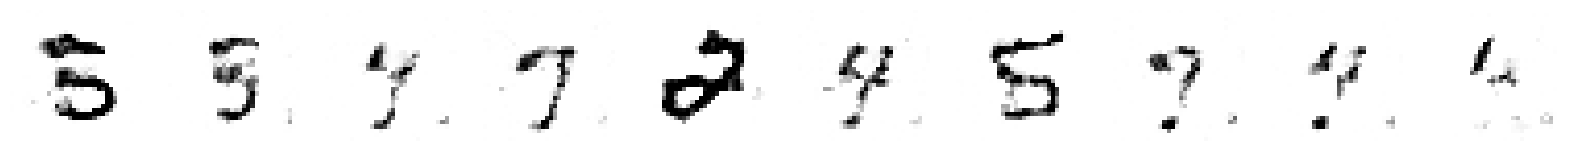


Saved to ./output/example_img_037.png


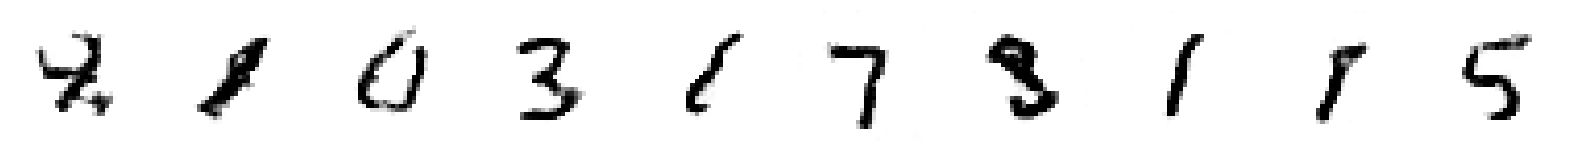

469/469 ━━━━━━━━━━━━━━━━━━━━ 748s 2s/step - cdiv: 1.0869e-04 - fake: 4.5656e-04 - loss: 2.0495e-04 - real: 3.4787e-04 - reg: 9.6261e-05 - val_cdiv: -13.3882 - val_fake: -13.3776 - val_real: 0.0106
Epoch 39/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9385e-04 - fake: 8.1617e-04 - loss: -7.2694e-05 - real: 0.0010 - reg: 1.2115e-04
Saved to ./output/generated_img_038.png


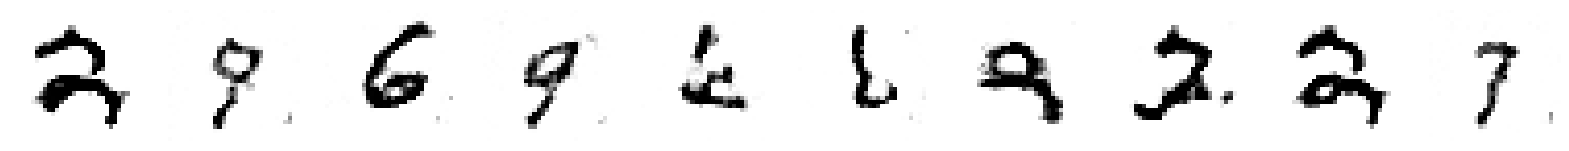


Saved to ./output/example_img_038.png


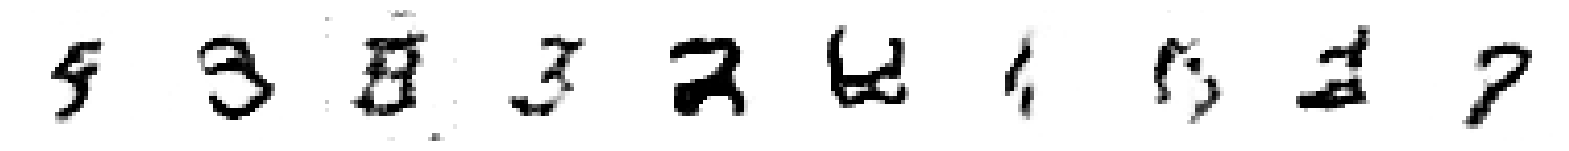

469/469 ━━━━━━━━━━━━━━━━━━━━ 747s 2s/step - cdiv: -4.9151e-05 - fake: 4.0083e-04 - loss: 5.9570e-05 - real: 4.4998e-04 - reg: 1.0872e-04 - val_cdiv: -13.7779 - val_fake: -13.7698 - val_real: 0.0082
Epoch 40/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -7.2123e-05 - fake: 4.8090e-04 - loss: 3.8991e-05 - real: 5.5302e-04 - reg: 1.1111e-04
Saved to ./output/generated_img_039.png


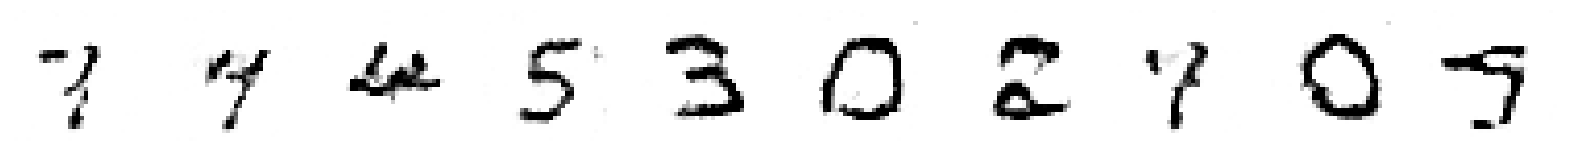


Saved to ./output/example_img_039.png


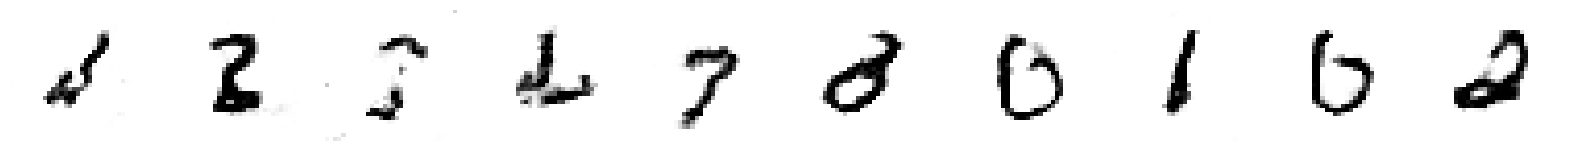

469/469 ━━━━━━━━━━━━━━━━━━━━ 749s 2s/step - cdiv: 3.3033e-05 - fake: 4.2170e-04 - loss: 1.4284e-04 - real: 3.8867e-04 - reg: 1.0981e-04 - val_cdiv: -13.9763 - val_fake: -13.9700 - val_real: 0.0062
Epoch 41/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.0789e-04 - fake: 5.8625e-04 - loss: -8.4250e-05 - real: 7.9415e-04 - reg: 1.2364e-04
Saved to ./output/generated_img_040.png


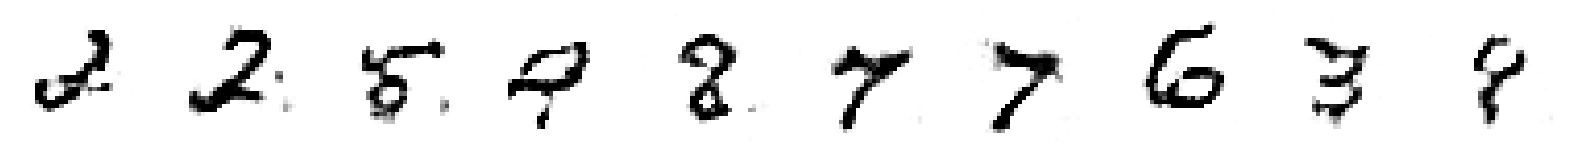


Saved to ./output/example_img_040.png


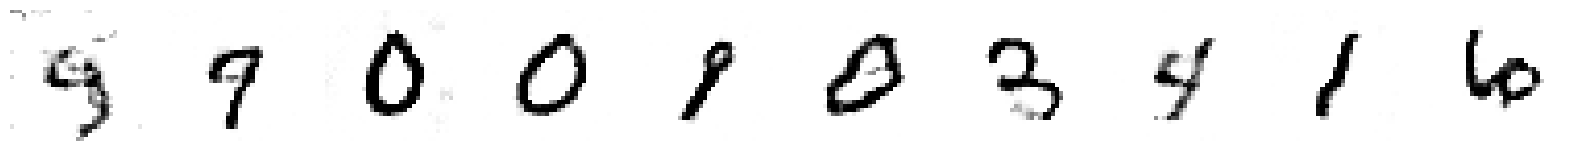

469/469 ━━━━━━━━━━━━━━━━━━━━ 748s 2s/step - cdiv: -1.7062e-05 - fake: 3.8252e-04 - loss: 9.4177e-05 - real: 3.9958e-04 - reg: 1.1124e-04 - val_cdiv: -14.7109 - val_fake: -14.7085 - val_real: 0.0024
Epoch 42/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -5.1805e-06 - fake: 7.6911e-04 - loss: 1.0478e-04 - real: 7.7429e-04 - reg: 1.0996e-04
Saved to ./output/generated_img_041.png


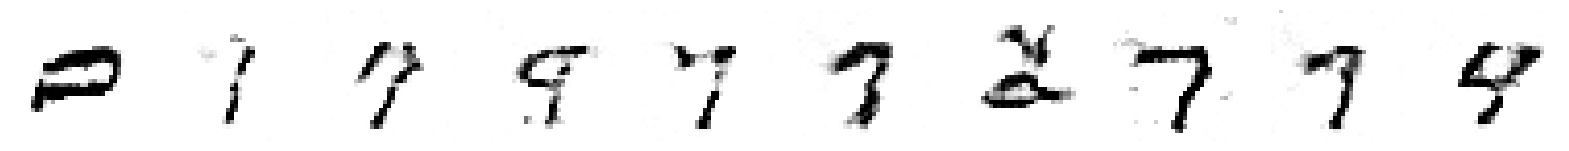


Saved to ./output/example_img_041.png


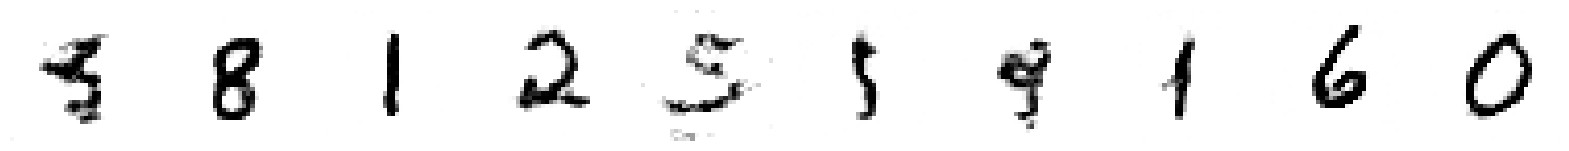

469/469 ━━━━━━━━━━━━━━━━━━━━ 752s 2s/step - cdiv: 1.7342e-04 - fake: 4.8135e-04 - loss: 2.7254e-04 - real: 3.0793e-04 - reg: 9.9115e-05 - val_cdiv: -15.0616 - val_fake: -15.0441 - val_real: 0.0175
Epoch 43/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.4173e-04 - fake: 0.0011 - loss: -3.8468e-05 - real: 0.0012 - reg: 1.0326e-04
Saved to ./output/generated_img_042.png


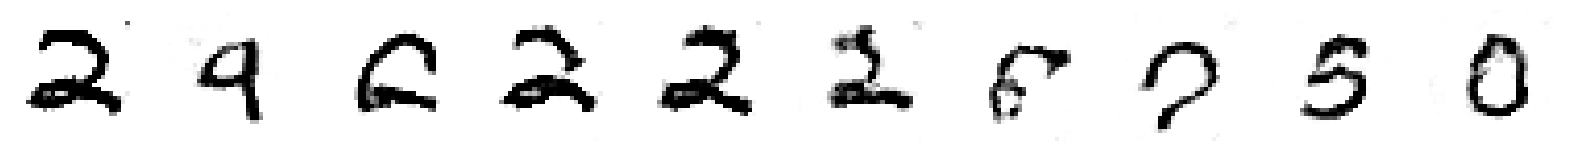


Saved to ./output/example_img_042.png


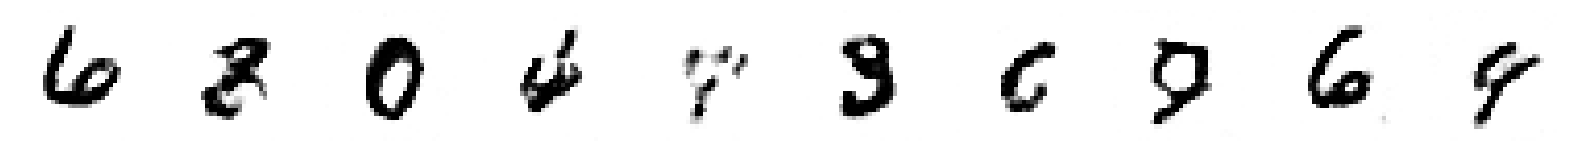

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: 4.1196e-05 - fake: 5.6094e-04 - loss: 1.1823e-04 - real: 5.1974e-04 - reg: 7.7037e-05 - val_cdiv: -15.3229 - val_fake: -15.3240 - val_real: -0.0011
Epoch 44/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 2.8382e-05 - fake: 1.9582e-04 - loss: 1.1922e-04 - real: 1.6743e-04 - reg: 9.0843e-05
Saved to ./output/generated_img_043.png


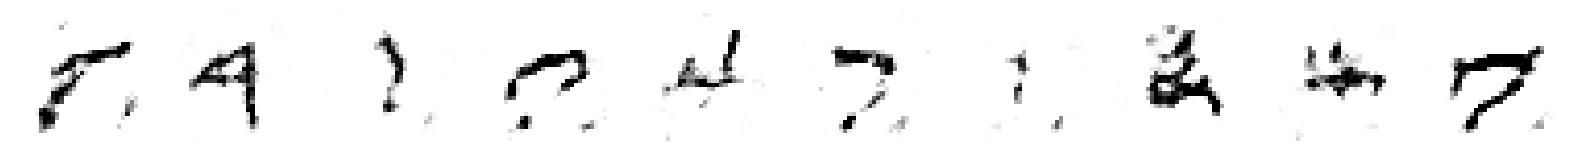


Saved to ./output/example_img_043.png


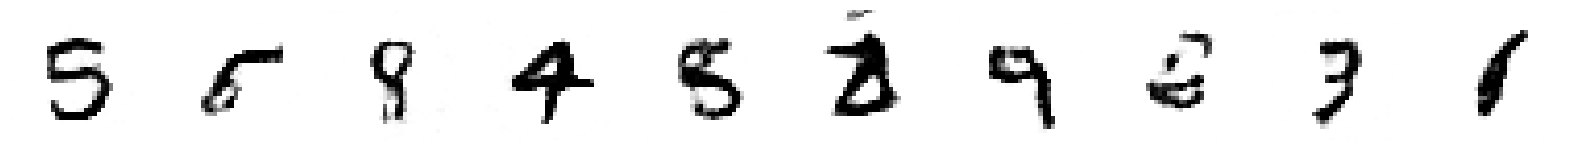

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: 1.3082e-04 - fake: 5.4289e-04 - loss: 2.1865e-04 - real: 4.1207e-04 - reg: 8.7828e-05 - val_cdiv: -15.6328 - val_fake: -15.6178 - val_real: 0.0150
Epoch 45/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -5.3098e-04 - fake: 6.0120e-05 - loss: -3.9477e-04 - real: 5.9110e-04 - reg: 1.3621e-04
Saved to ./output/generated_img_044.png


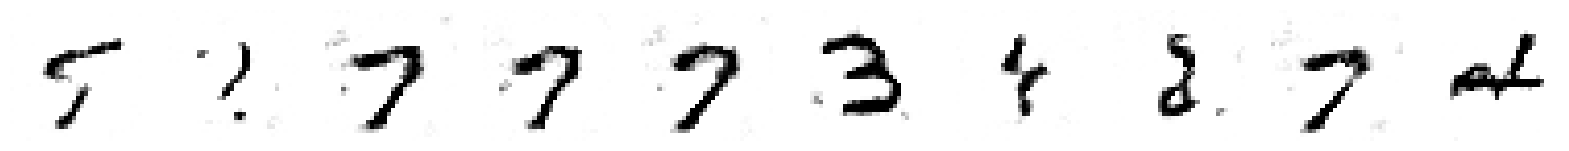


Saved to ./output/example_img_044.png


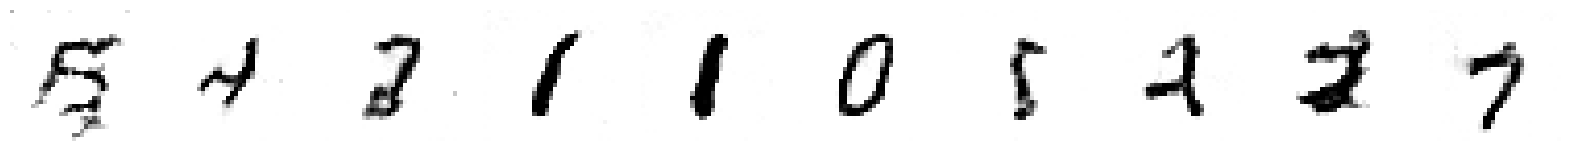

469/469 ━━━━━━━━━━━━━━━━━━━━ 754s 2s/step - cdiv: -1.6000e-04 - fake: 4.0489e-04 - loss: -5.7284e-05 - real: 5.6488e-04 - reg: 1.0271e-04 - val_cdiv: -16.3731 - val_fake: -16.3670 - val_real: 0.0061
Epoch 46/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.1725e-04 - fake: -4.4529e-05 - loss: -1.8788e-04 - real: 2.7272e-04 - reg: 1.2937e-04
Saved to ./output/generated_img_045.png


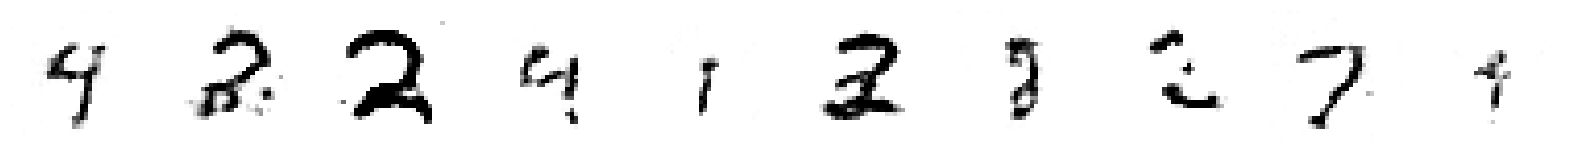


Saved to ./output/example_img_045.png


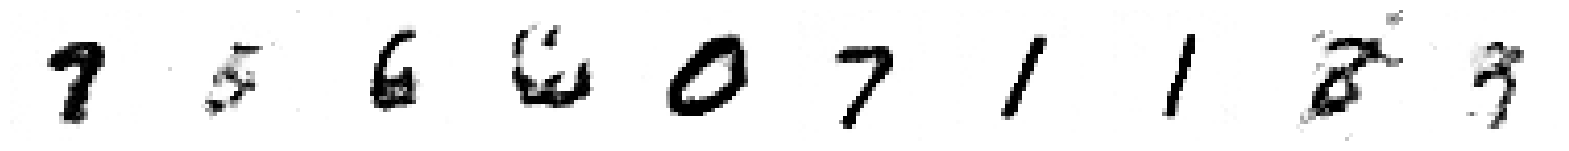

469/469 ━━━━━━━━━━━━━━━━━━━━ 755s 2s/step - cdiv: 1.7754e-04 - fake: 2.5337e-04 - loss: 2.8167e-04 - real: 7.5833e-05 - reg: 1.0413e-04 - val_cdiv: -16.7459 - val_fake: -16.7383 - val_real: 0.0077
Epoch 47/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.1421e-04 - fake: 6.4934e-04 - loss: -1.0489e-04 - real: 8.6355e-04 - reg: 1.0932e-04
Saved to ./output/generated_img_046.png


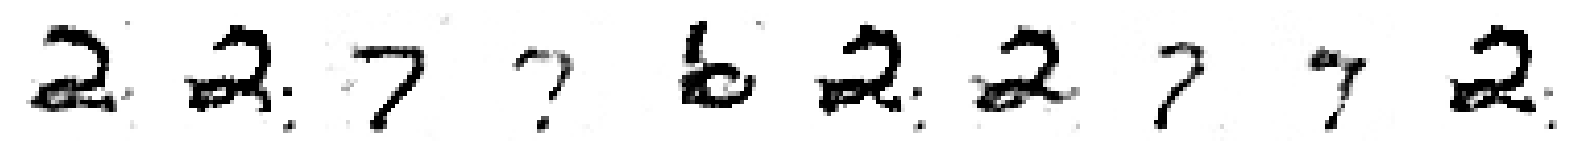


Saved to ./output/example_img_046.png


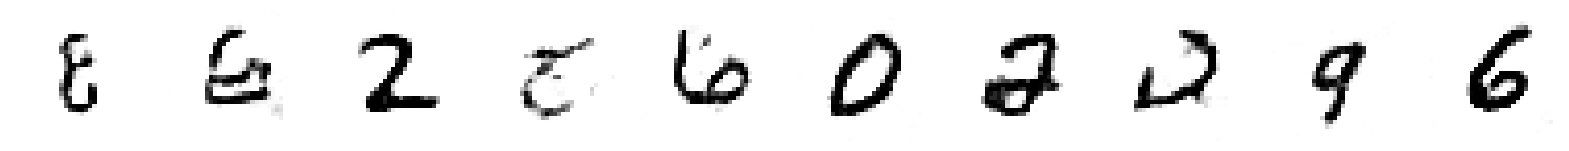

469/469 ━━━━━━━━━━━━━━━━━━━━ 749s 2s/step - cdiv: -2.7419e-05 - fake: 5.1398e-04 - loss: 7.0779e-05 - real: 5.4140e-04 - reg: 9.8198e-05 - val_cdiv: -17.0921 - val_fake: -17.0839 - val_real: 0.0083
Epoch 48/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 2.9983e-04 - fake: 6.0491e-04 - loss: 3.8505e-04 - real: 3.0507e-04 - reg: 8.5215e-05
Saved to ./output/generated_img_047.png


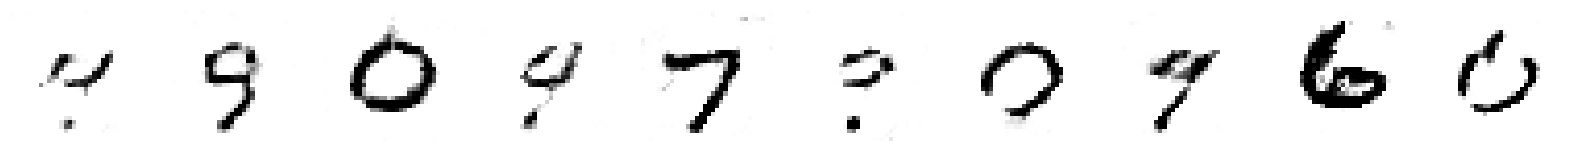


Saved to ./output/example_img_047.png


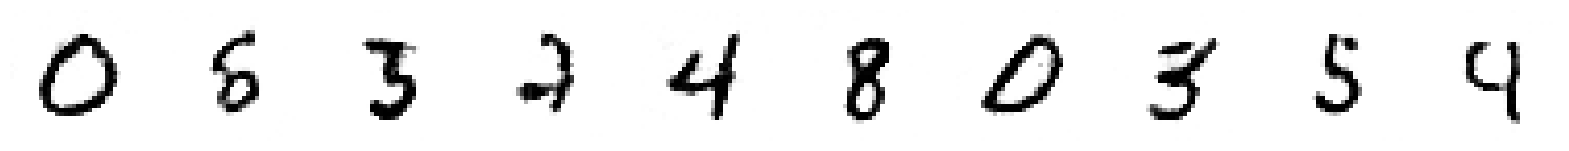

469/469 ━━━━━━━━━━━━━━━━━━━━ 771s 2s/step - cdiv: 1.3502e-04 - fake: 2.3691e-04 - loss: 2.1261e-04 - real: 1.0189e-04 - reg: 7.7590e-05 - val_cdiv: -17.1587 - val_fake: -17.1539 - val_real: 0.0048
Epoch 49/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.8874e-04 - fake: 2.4189e-04 - loss: -1.7624e-04 - real: 5.3063e-04 - reg: 1.1250e-04
Saved to ./output/generated_img_048.png


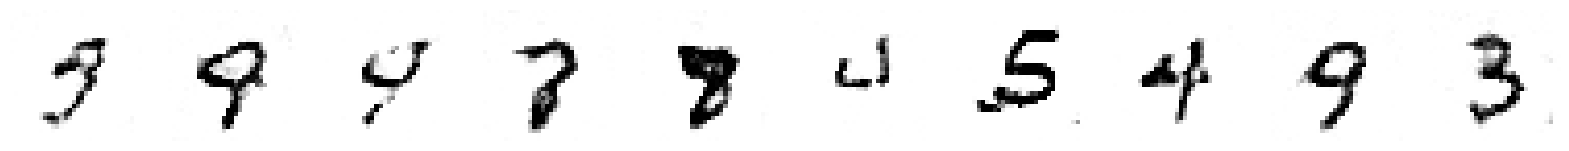


Saved to ./output/example_img_048.png


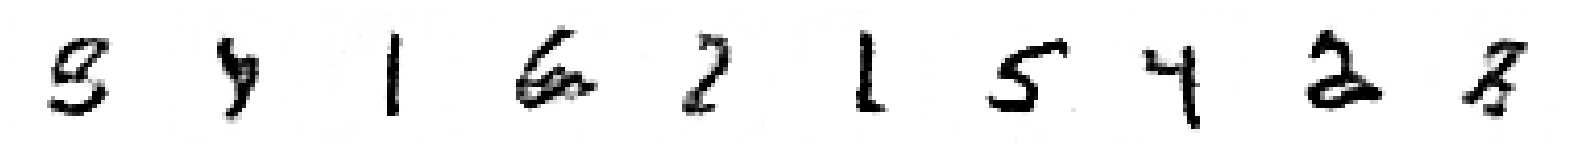

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: 8.4996e-06 - fake: 2.4087e-04 - loss: 1.0467e-04 - real: 2.3237e-04 - reg: 9.6169e-05 - val_cdiv: -17.3725 - val_fake: -17.3668 - val_real: 0.0057
Epoch 50/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.2640e-04 - fake: 2.1409e-04 - loss: -2.9077e-04 - real: 6.4049e-04 - reg: 1.3563e-04
Saved to ./output/generated_img_049.png


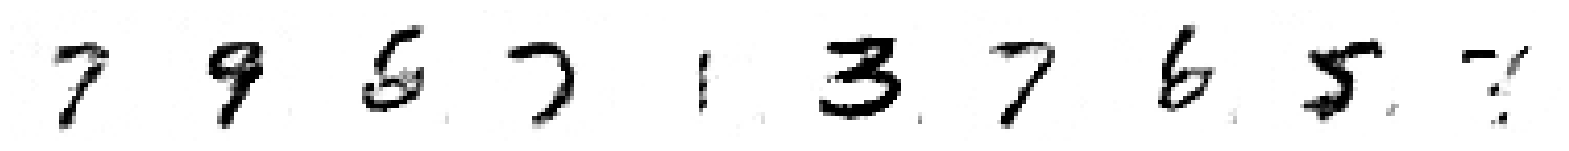


Saved to ./output/example_img_049.png


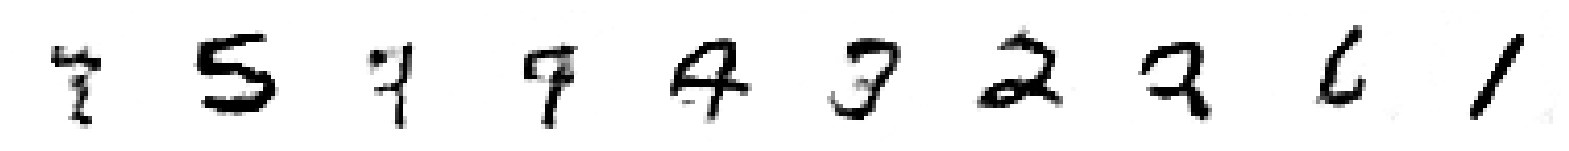

469/469 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - cdiv: -3.8696e-05 - fake: 3.6564e-04 - loss: 7.2774e-05 - real: 4.0434e-04 - reg: 1.1147e-04 - val_cdiv: -18.1827 - val_fake: -18.1784 - val_real: 0.0043
Epoch 51/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9095e-04 - fake: 9.8570e-05 - loss: -9.1626e-05 - real: 2.8952e-04 - reg: 9.9327e-05
Saved to ./output/generated_img_050.png


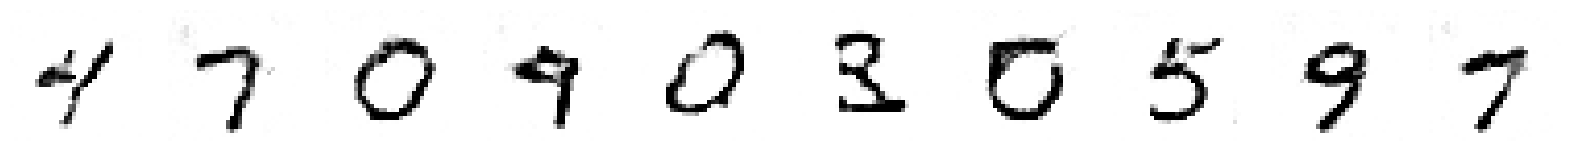


Saved to ./output/example_img_050.png


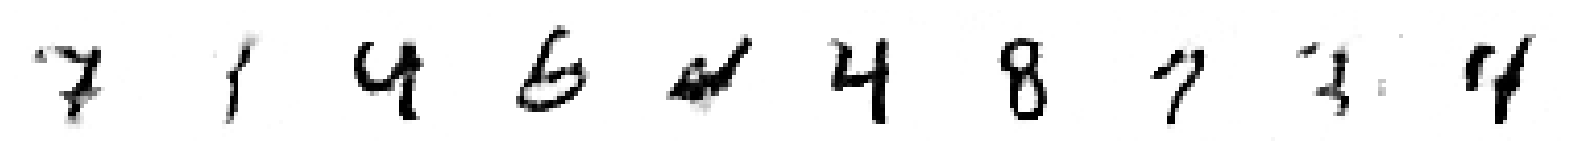

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: 6.4758e-06 - fake: 1.8139e-04 - loss: 9.5191e-05 - real: 1.7492e-04 - reg: 8.8715e-05 - val_cdiv: -18.4300 - val_fake: -18.4219 - val_real: 0.0080
Epoch 52/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.1598e-04 - fake: 5.7063e-04 - loss: -6.1611e-06 - real: 6.8660e-04 - reg: 1.0982e-04
Saved to ./output/generated_img_051.png


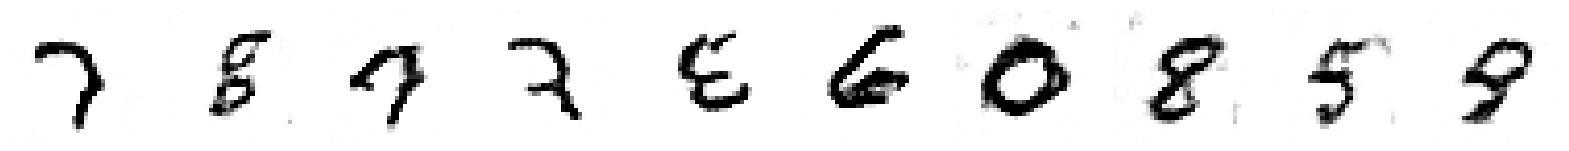


Saved to ./output/example_img_051.png


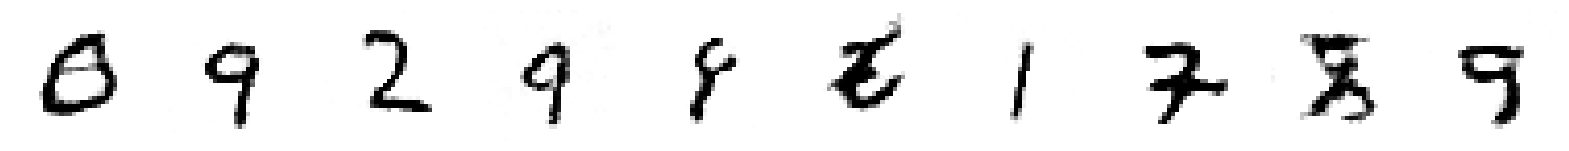

469/469 ━━━━━━━━━━━━━━━━━━━━ 762s 2s/step - cdiv: 1.7236e-04 - fake: 4.0089e-04 - loss: 2.5446e-04 - real: 2.2853e-04 - reg: 8.2097e-05 - val_cdiv: -18.9911 - val_fake: -18.9842 - val_real: 0.0069
Epoch 53/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.9274e-04 - fake: -3.5039e-07 - loss: -3.0223e-04 - real: 3.9239e-04 - reg: 9.0507e-05
Saved to ./output/generated_img_052.png


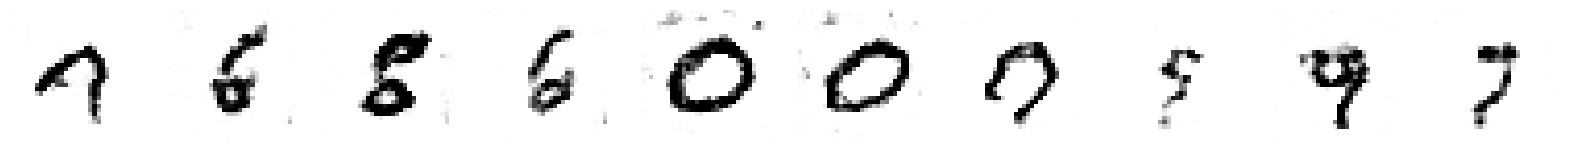


Saved to ./output/example_img_052.png


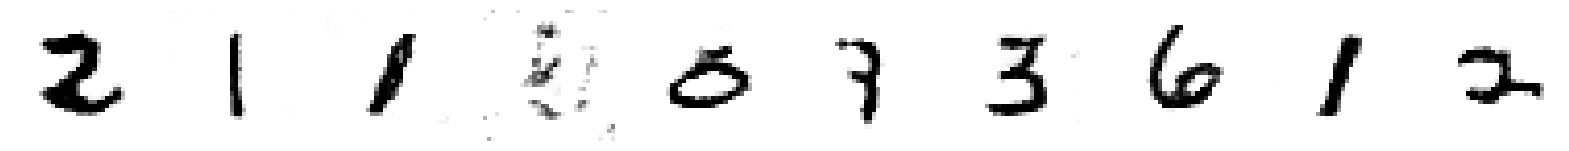

469/469 ━━━━━━━━━━━━━━━━━━━━ 762s 2s/step - cdiv: -1.1759e-05 - fake: 1.1051e-04 - loss: 7.8127e-05 - real: 1.2227e-04 - reg: 8.9886e-05 - val_cdiv: -18.9993 - val_fake: -18.9919 - val_real: 0.0074
Epoch 54/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.1113e-04 - fake: 1.6439e-04 - loss: -2.9593e-04 - real: 5.7552e-04 - reg: 1.1520e-04
Saved to ./output/generated_img_053.png


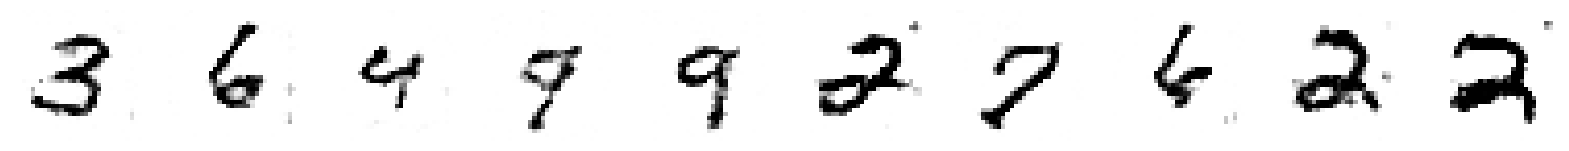


Saved to ./output/example_img_053.png


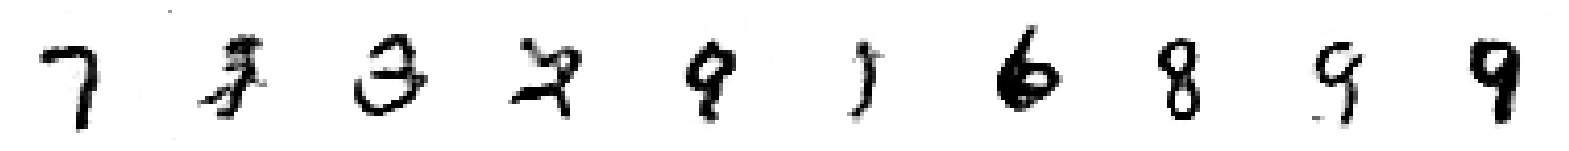

469/469 ━━━━━━━━━━━━━━━━━━━━ 758s 2s/step - cdiv: -9.9695e-05 - fake: 1.4129e-04 - loss: -5.8277e-06 - real: 2.4099e-04 - reg: 9.3867e-05 - val_cdiv: -19.6286 - val_fake: -19.6245 - val_real: 0.0042
Epoch 55/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9753e-04 - fake: 3.6214e-04 - loss: -6.8064e-05 - real: 5.5967e-04 - reg: 1.2946e-04
Saved to ./output/generated_img_054.png


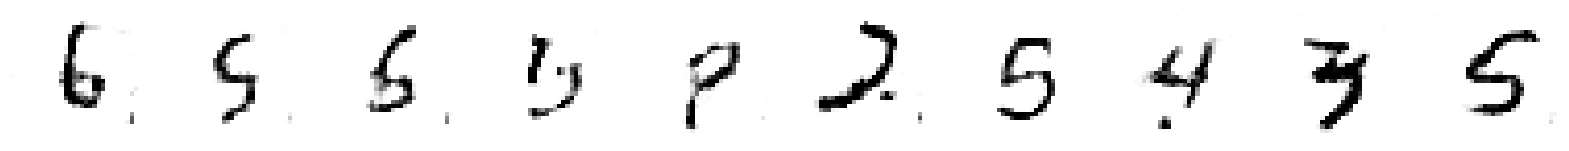


Saved to ./output/example_img_054.png


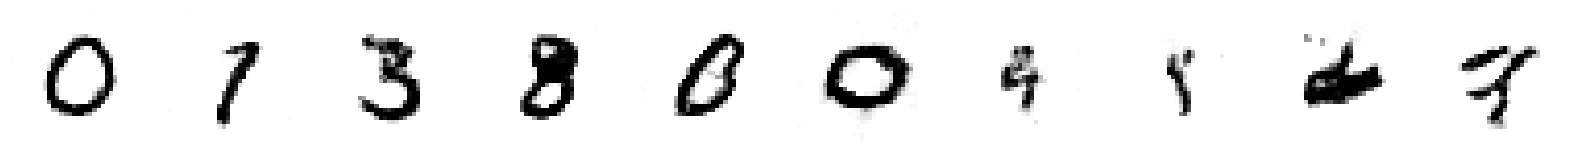

469/469 ━━━━━━━━━━━━━━━━━━━━ 770s 2s/step - cdiv: 7.4039e-05 - fake: 3.3835e-04 - loss: 1.7299e-04 - real: 2.6431e-04 - reg: 9.8955e-05 - val_cdiv: -19.8513 - val_fake: -19.8477 - val_real: 0.0036
Epoch 56/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.3799e-04 - fake: 2.7982e-04 - loss: -2.1588e-04 - real: 6.1781e-04 - reg: 1.2211e-04
Saved to ./output/generated_img_055.png


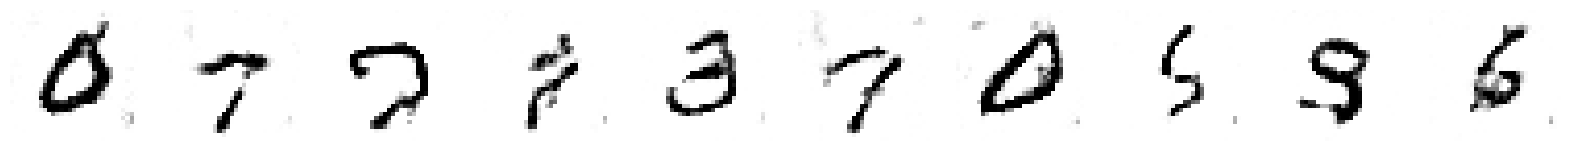


Saved to ./output/example_img_055.png


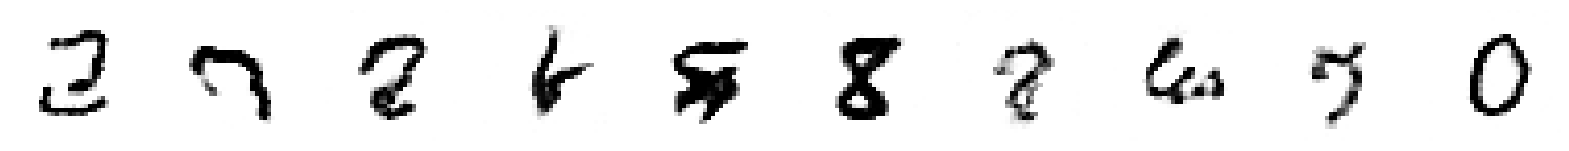

469/469 ━━━━━━━━━━━━━━━━━━━━ 772s 2s/step - cdiv: 1.1586e-04 - fake: 1.8829e-04 - loss: 2.1265e-04 - real: 7.2425e-05 - reg: 9.6788e-05 - val_cdiv: -20.0336 - val_fake: -20.0278 - val_real: 0.0059
Epoch 57/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.7389e-05 - fake: -1.5465e-05 - loss: 4.1098e-05 - real: 3.1924e-05 - reg: 8.8487e-05
Saved to ./output/generated_img_056.png


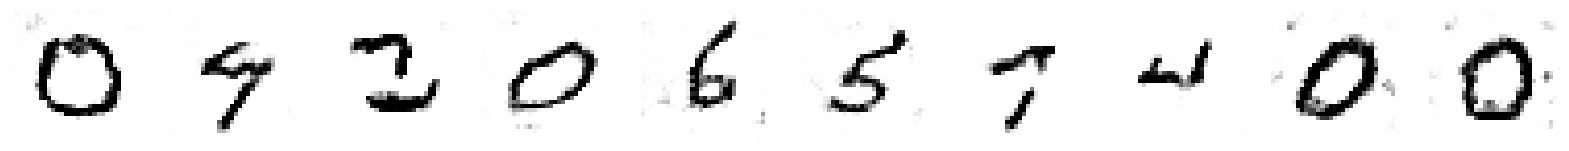


Saved to ./output/example_img_056.png


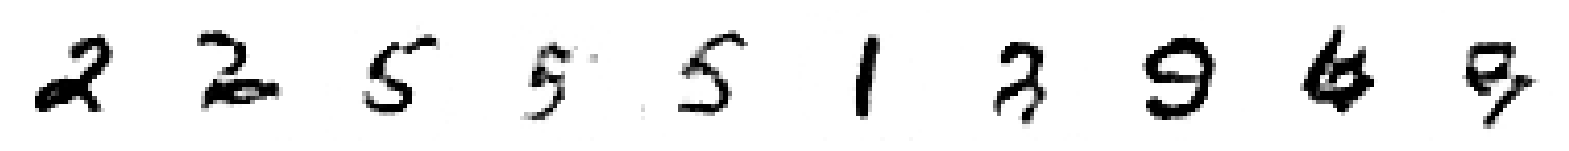

469/469 ━━━━━━━━━━━━━━━━━━━━ 761s 2s/step - cdiv: 9.3131e-05 - fake: 2.2971e-04 - loss: 1.7005e-04 - real: 1.3658e-04 - reg: 7.6921e-05 - val_cdiv: -20.4472 - val_fake: -20.4411 - val_real: 0.0061
Epoch 58/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.9690e-04 - fake: 3.3527e-04 - loss: -1.9599e-04 - real: 6.3218e-04 - reg: 1.0092e-04
Saved to ./output/generated_img_057.png


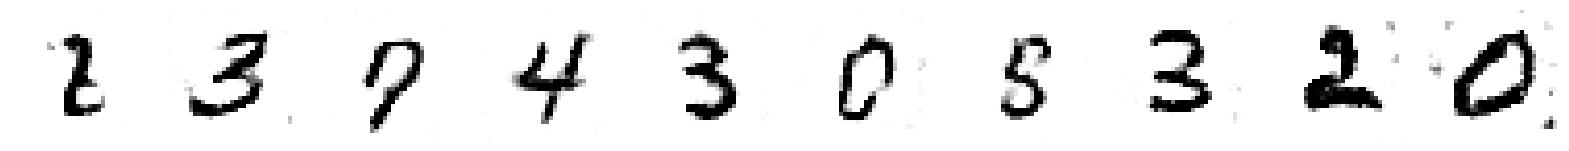


Saved to ./output/example_img_057.png


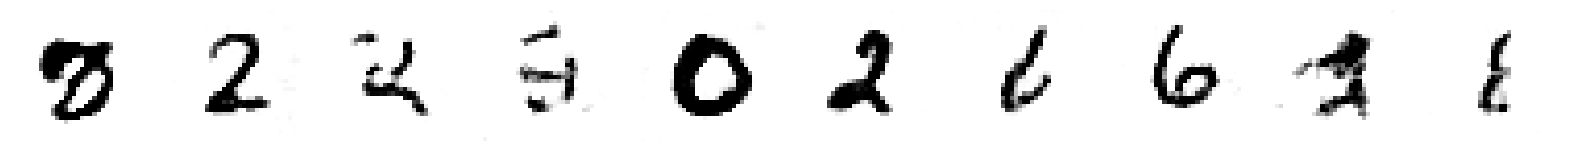

469/469 ━━━━━━━━━━━━━━━━━━━━ 759s 2s/step - cdiv: 3.1518e-05 - fake: 4.0027e-04 - loss: 1.2107e-04 - real: 3.6875e-04 - reg: 8.9556e-05 - val_cdiv: -20.4299 - val_fake: -20.4308 - val_real: -9.2365e-04
Epoch 59/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7831e-04 - fake: 1.3931e-04 - loss: -8.1524e-05 - real: 3.1762e-04 - reg: 9.6789e-05
Saved to ./output/generated_img_058.png


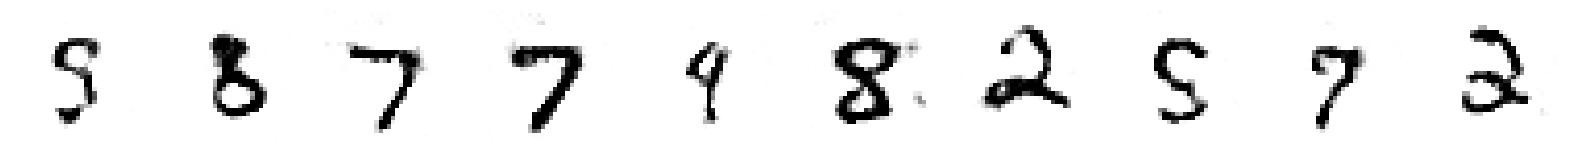


Saved to ./output/example_img_058.png


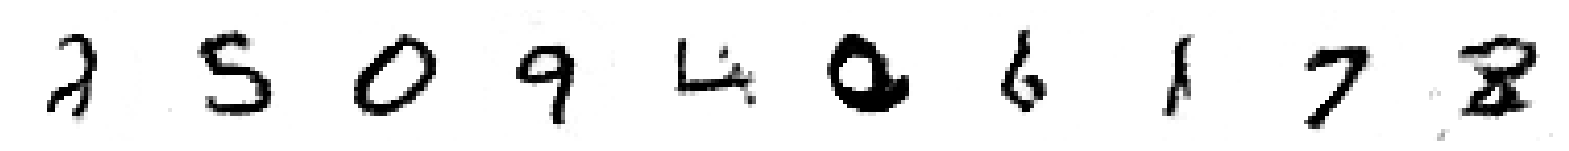

469/469 ━━━━━━━━━━━━━━━━━━━━ 756s 2s/step - cdiv: -5.6020e-05 - fake: 3.0052e-04 - loss: 4.5158e-05 - real: 3.5654e-04 - reg: 1.0118e-04 - val_cdiv: -20.2690 - val_fake: -20.2716 - val_real: -0.0025
Epoch 60/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.0187e-05 - fake: -4.9165e-04 - loss: 8.4657e-05 - real: -4.7146e-04 - reg: 1.0484e-04
Saved to ./output/generated_img_059.png


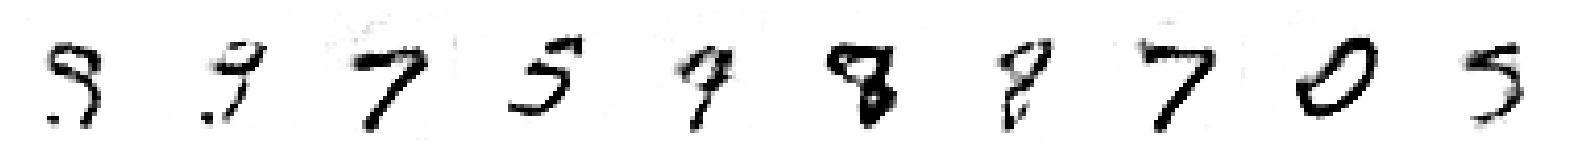


Saved to ./output/example_img_059.png


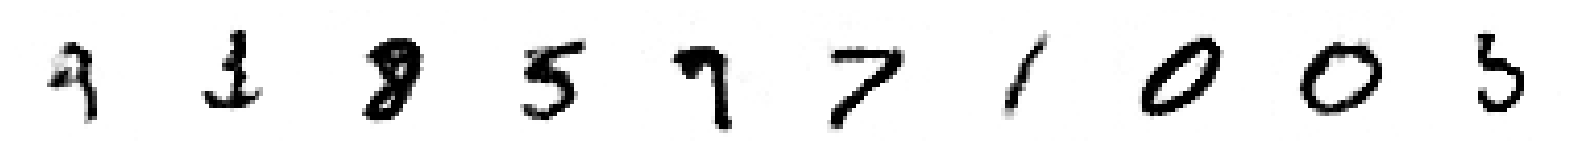

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: 1.8588e-04 - fake: 1.9097e-04 - loss: 2.6768e-04 - real: 5.0887e-06 - reg: 8.1792e-05 - val_cdiv: -20.6213 - val_fake: -20.6186 - val_real: 0.0027


In [34]:
ebm.fit(
    x_train,
    shuffle=True,
    epochs=60,
    validation_data=x_test,
    callbacks=[
        save_model_callback,
        tensorboard_callback,
        image_generator_callback,
    ],
)

Epoch 1/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0679 - fake: 0.2250 - loss: -0.0460 - real: 0.2929 - reg: 0.0219
Saved to ./output/generated_img_000.png


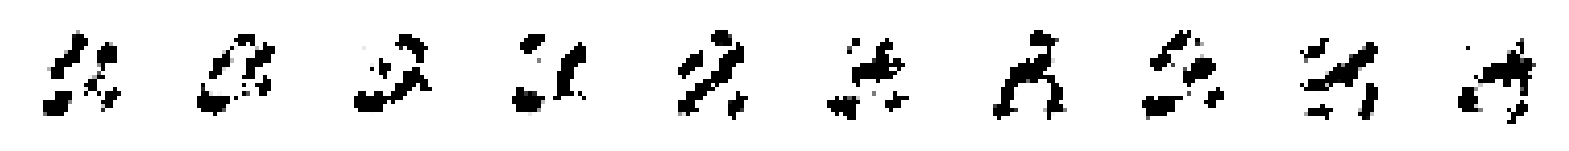


Saved to ./output/example_img_000.png


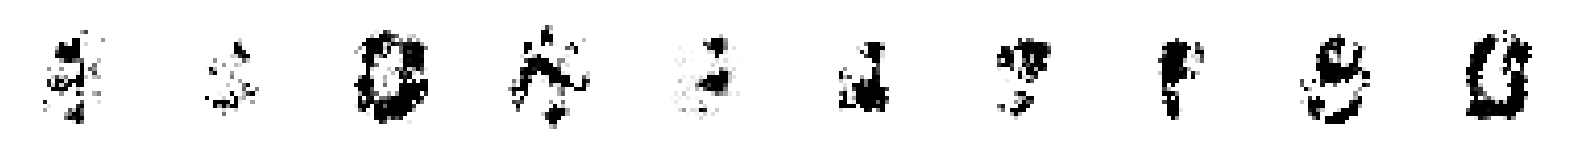

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: -0.0556 - fake: 0.1648 - loss: -0.0406 - real: 0.2204 - reg: 0.0150 - val_cdiv: -1.6309 - val_fake: -1.6855 - val_real: -0.0546
Epoch 2/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0023 - fake: 0.0131 - loss: 3.6031e-04 - real: 0.0154 - reg: 0.0027
Saved to ./output/generated_img_001.png


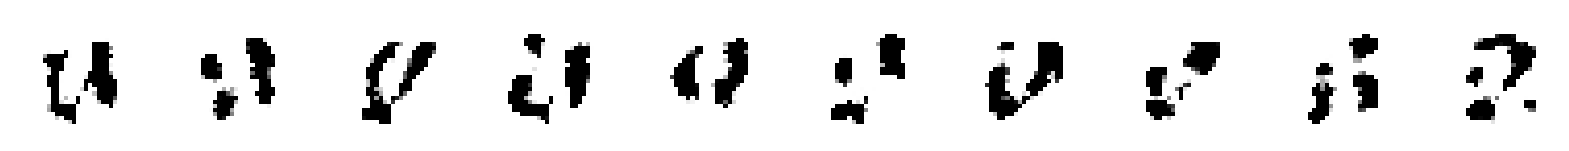


Saved to ./output/example_img_001.png


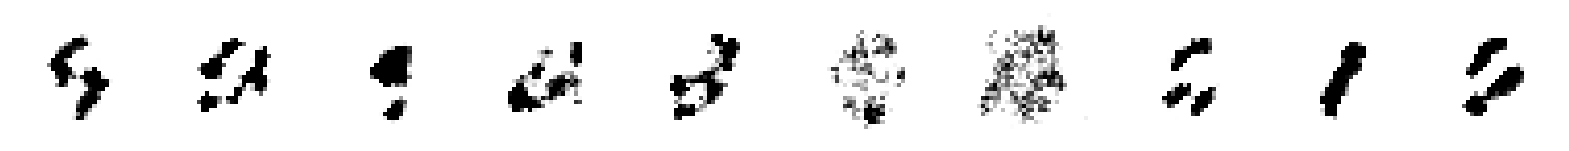

469/469 ━━━━━━━━━━━━━━━━━━━━ 766s 2s/step - cdiv: -0.0033 - fake: 0.0063 - loss: -0.0013 - real: 0.0096 - reg: 0.0021 - val_cdiv: -1.6906 - val_fake: -1.7581 - val_real: -0.0674
Epoch 3/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0036 - fake: 0.0039 - loss: -0.0022 - real: 0.0076 - reg: 0.0014
Saved to ./output/generated_img_002.png


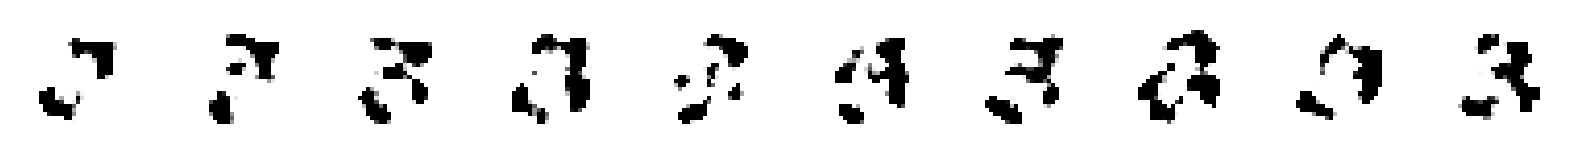


Saved to ./output/example_img_002.png


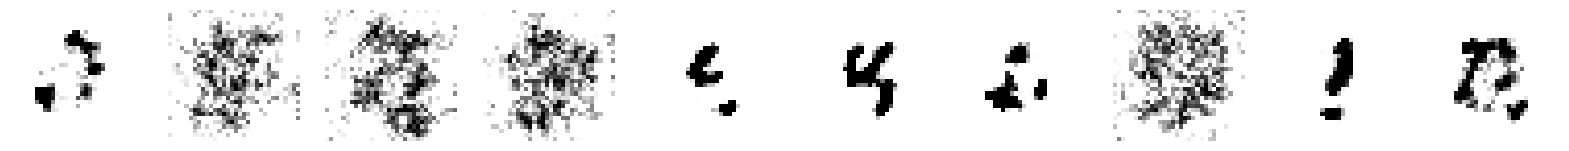

469/469 ━━━━━━━━━━━━━━━━━━━━ 768s 2s/step - cdiv: -0.0026 - fake: 0.0022 - loss: -0.0013 - real: 0.0048 - reg: 0.0013 - val_cdiv: -1.9291 - val_fake: -2.0075 - val_real: -0.0784
Epoch 4/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -0.0020 - fake: 0.0041 - loss: -9.3321e-04 - real: 0.0061 - reg: 0.0011
Saved to ./output/generated_img_003.png


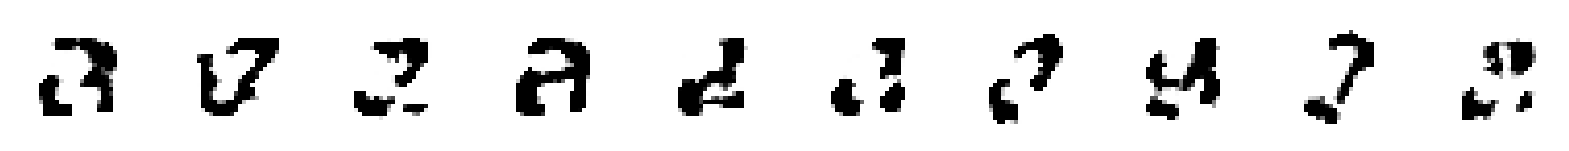


Saved to ./output/example_img_003.png


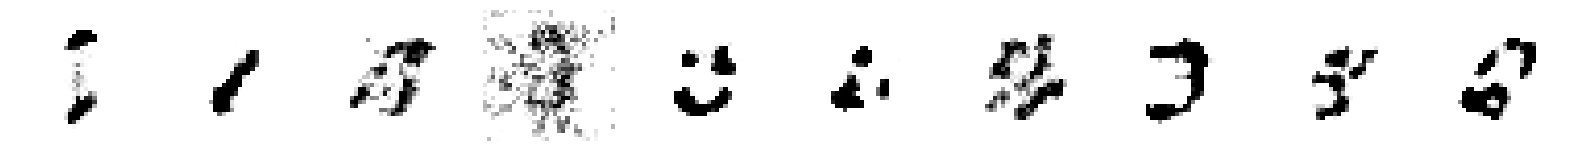

469/469 ━━━━━━━━━━━━━━━━━━━━ 756s 2s/step - cdiv: -0.0010 - fake: 0.0022 - loss: -2.3522e-04 - real: 0.0032 - reg: 7.8854e-04 - val_cdiv: -2.1807 - val_fake: -2.2226 - val_real: -0.0419
Epoch 5/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -8.0286e-04 - fake: 0.0028 - loss: -3.1142e-04 - real: 0.0036 - reg: 4.9143e-04
Saved to ./output/generated_img_004.png


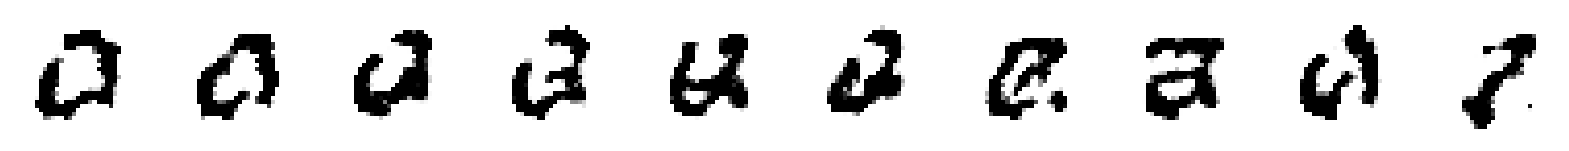


Saved to ./output/example_img_004.png


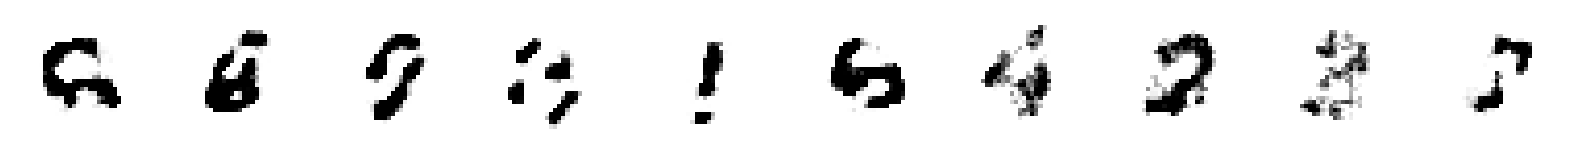

469/469 ━━━━━━━━━━━━━━━━━━━━ 759s 2s/step - cdiv: -7.3881e-04 - fake: 0.0021 - loss: -3.5969e-04 - real: 0.0028 - reg: 3.7912e-04 - val_cdiv: -2.5219 - val_fake: -2.5454 - val_real: -0.0235
Epoch 6/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 7.8790e-04 - fake: 9.5928e-04 - loss: 0.0011 - real: 1.7138e-04 - reg: 3.1375e-04
Saved to ./output/generated_img_005.png


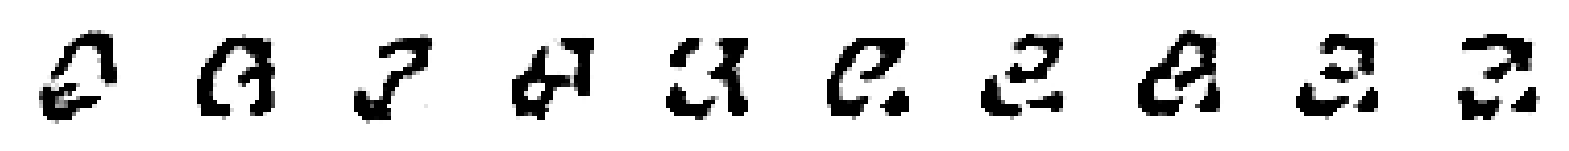


Saved to ./output/example_img_005.png


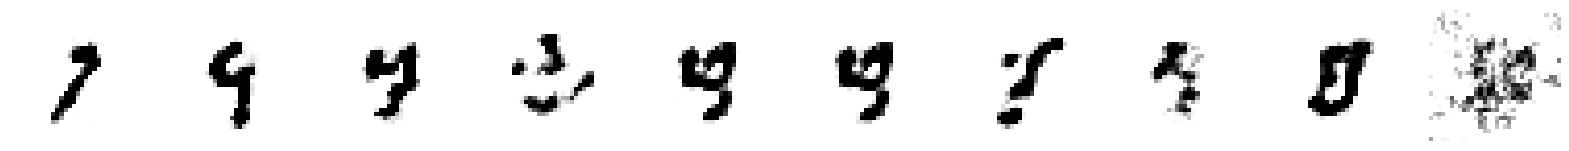

469/469 ━━━━━━━━━━━━━━━━━━━━ 746s 2s/step - cdiv: 2.7560e-04 - fake: 0.0015 - loss: 5.4153e-04 - real: 0.0012 - reg: 2.6593e-04 - val_cdiv: -2.6991 - val_fake: -2.7319 - val_real: -0.0327
Epoch 7/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.3513e-04 - fake: 6.4881e-04 - loss: 1.7210e-04 - real: 7.8394e-04 - reg: 3.0723e-04
Saved to ./output/generated_img_006.png


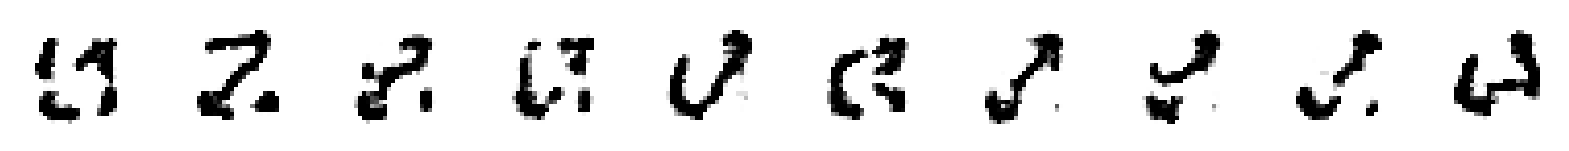


Saved to ./output/example_img_006.png


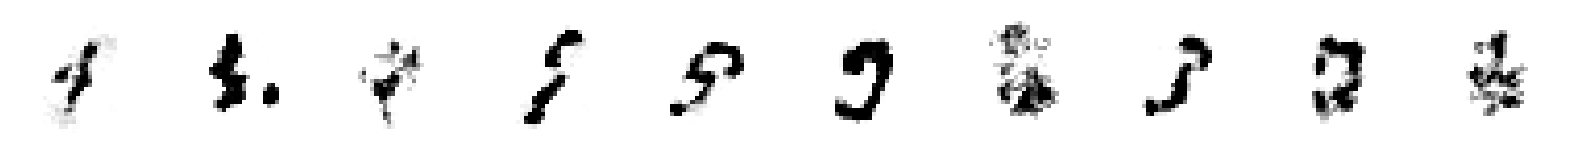

469/469 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - cdiv: -1.3578e-05 - fake: 0.0019 - loss: 2.6018e-04 - real: 0.0019 - reg: 2.7376e-04 - val_cdiv: -3.0540 - val_fake: -3.0586 - val_real: -0.0046
Epoch 8/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.7679e-04 - fake: -0.0011 - loss: -3.3874e-05 - real: -6.8535e-04 - reg: 3.4292e-04
Saved to ./output/generated_img_007.png


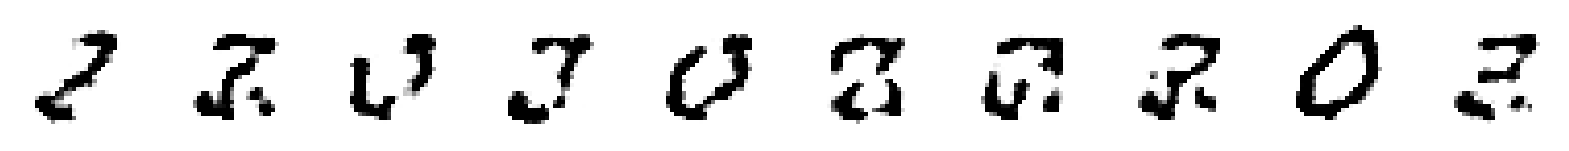


Saved to ./output/example_img_007.png


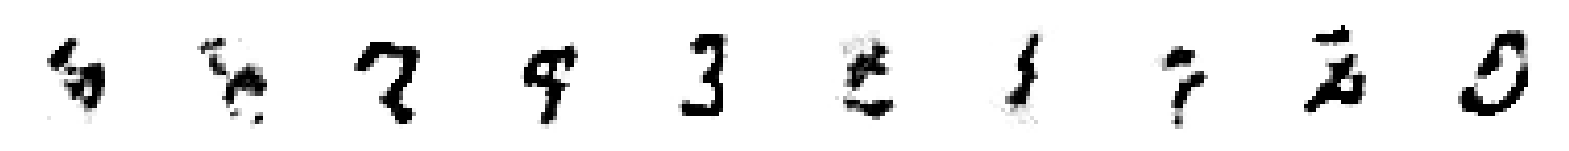

469/469 ━━━━━━━━━━━━━━━━━━━━ 747s 2s/step - cdiv: -6.0909e-04 - fake: 0.0014 - loss: -2.9530e-04 - real: 0.0020 - reg: 3.1379e-04 - val_cdiv: -3.5908 - val_fake: -3.5756 - val_real: 0.0152
Epoch 9/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -7.2497e-04 - fake: -0.0021 - loss: -2.7205e-04 - real: -0.0014 - reg: 4.5292e-04
Saved to ./output/generated_img_008.png


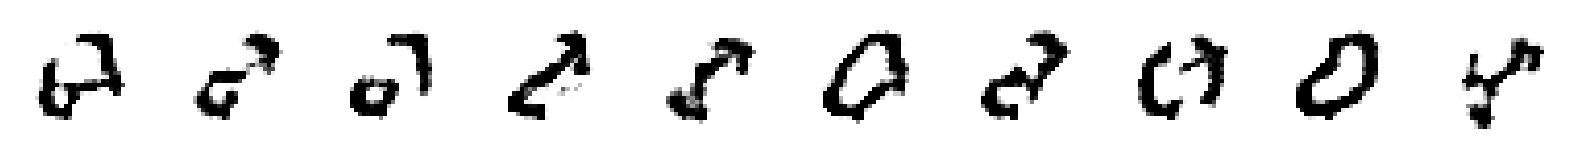


Saved to ./output/example_img_008.png


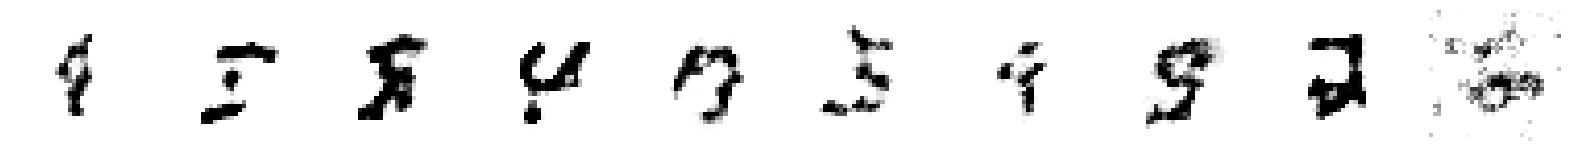

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: -4.8891e-04 - fake: 0.0011 - loss: -1.3804e-04 - real: 0.0016 - reg: 3.5087e-04 - val_cdiv: -3.9547 - val_fake: -3.9601 - val_real: -0.0055
Epoch 10/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.1027e-04 - fake: -0.0026 - loss: 2.2747e-06 - real: -0.0022 - reg: 4.1254e-04
Saved to ./output/generated_img_009.png


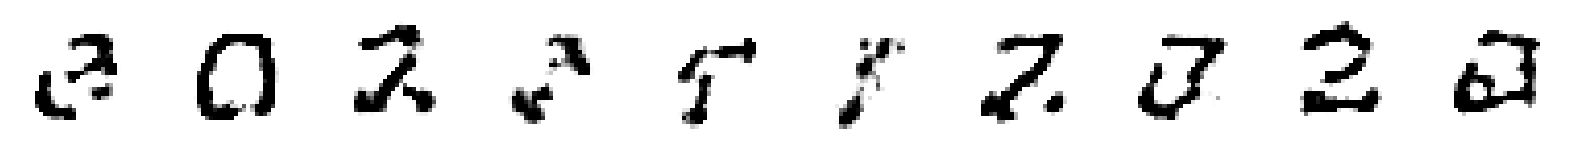


Saved to ./output/example_img_009.png


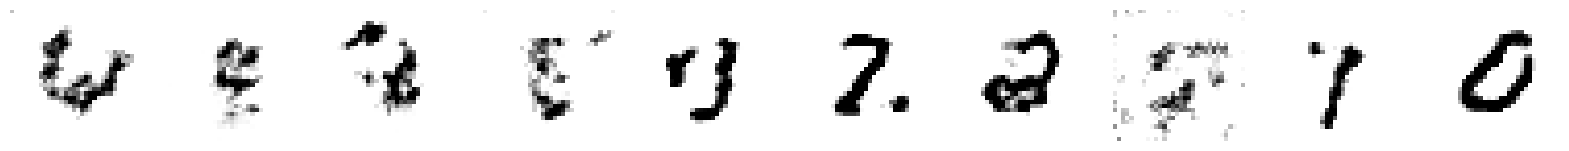

469/469 ━━━━━━━━━━━━━━━━━━━━ 770s 2s/step - cdiv: -2.7342e-04 - fake: 0.0011 - loss: 4.4145e-05 - real: 0.0014 - reg: 3.1756e-04 - val_cdiv: -4.3550 - val_fake: -4.3515 - val_real: 0.0034
Epoch 11/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.2189e-04 - fake: -0.0020 - loss: 1.3127e-05 - real: -0.0017 - reg: 3.3502e-04
Saved to ./output/generated_img_010.png


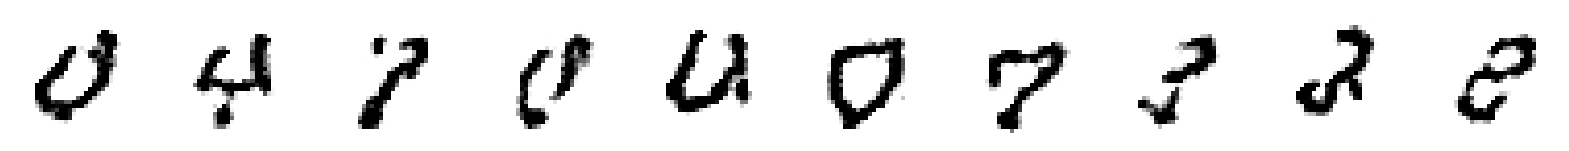


Saved to ./output/example_img_010.png


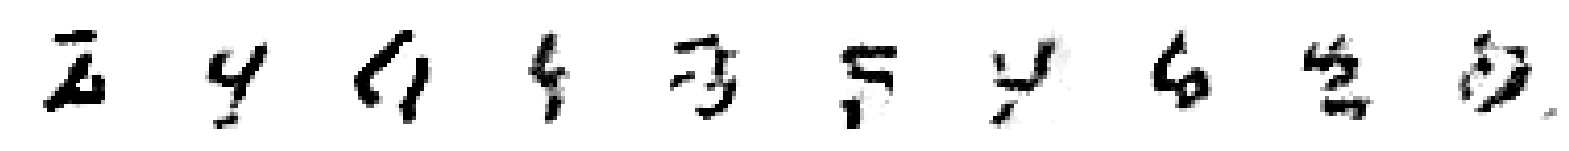

469/469 ━━━━━━━━━━━━━━━━━━━━ 795s 2s/step - cdiv: -2.6408e-04 - fake: 0.0010 - loss: 2.0720e-06 - real: 0.0013 - reg: 2.6615e-04 - val_cdiv: -4.7998 - val_fake: -4.7826 - val_real: 0.0171
Epoch 12/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.2713e-04 - fake: -0.0016 - loss: -1.1727e-04 - real: -0.0012 - reg: 3.0986e-04
Saved to ./output/generated_img_011.png


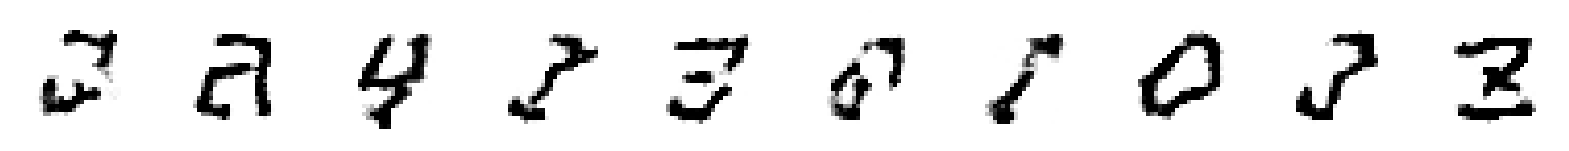


Saved to ./output/example_img_011.png


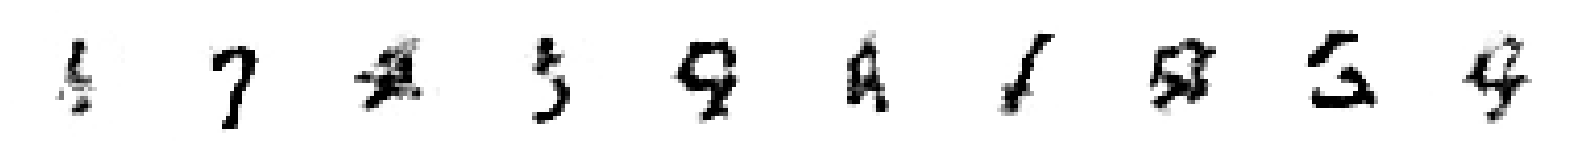

469/469 ━━━━━━━━━━━━━━━━━━━━ 795s 2s/step - cdiv: -8.7687e-05 - fake: 0.0010 - loss: 1.4414e-04 - real: 0.0011 - reg: 2.3183e-04 - val_cdiv: -5.1417 - val_fake: -5.1270 - val_real: 0.0147
Epoch 13/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -6.4119e-04 - fake: -0.0019 - loss: -3.8268e-04 - real: -0.0012 - reg: 2.5852e-04
Saved to ./output/generated_img_012.png


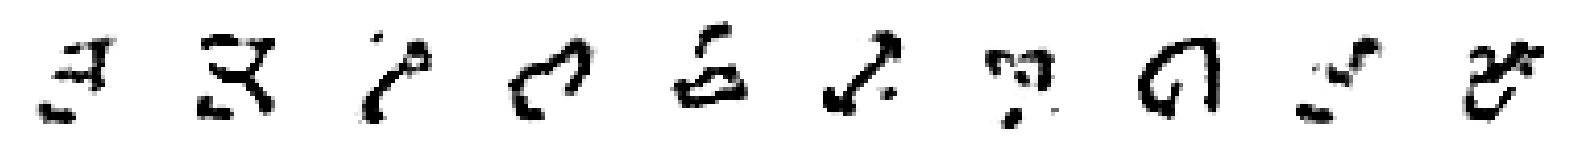


Saved to ./output/example_img_012.png


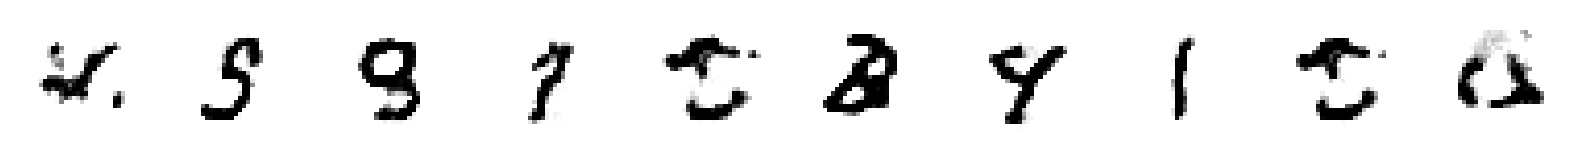

469/469 ━━━━━━━━━━━━━━━━━━━━ 802s 2s/step - cdiv: -3.5880e-04 - fake: 8.1727e-04 - loss: -1.4232e-04 - real: 0.0012 - reg: 2.1649e-04 - val_cdiv: -5.6083 - val_fake: -5.5987 - val_real: 0.0095
Epoch 14/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9324e-04 - fake: -0.0018 - loss: 2.0423e-05 - real: -0.0016 - reg: 2.1367e-04
Saved to ./output/generated_img_013.png


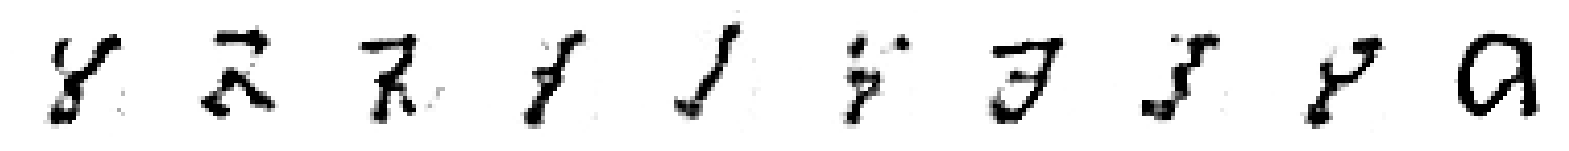


Saved to ./output/example_img_013.png


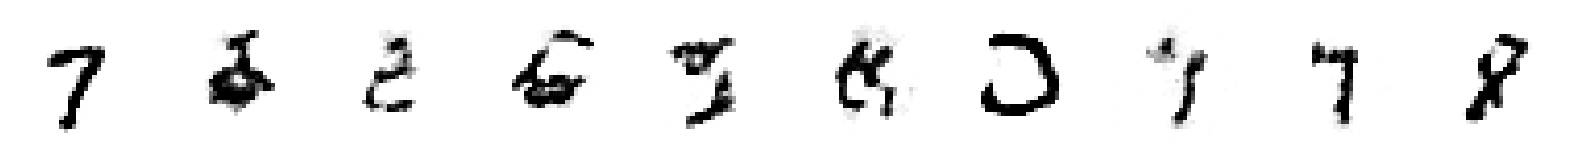

469/469 ━━━━━━━━━━━━━━━━━━━━ 804s 2s/step - cdiv: 1.0538e-04 - fake: 5.7120e-04 - loss: 2.9235e-04 - real: 4.6582e-04 - reg: 1.8698e-04 - val_cdiv: -5.8163 - val_fake: -5.8015 - val_real: 0.0148
Epoch 15/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.8906e-04 - fake: -8.0054e-04 - loss: -1.5942e-04 - real: -4.1148e-04 - reg: 2.2964e-04
Saved to ./output/generated_img_014.png


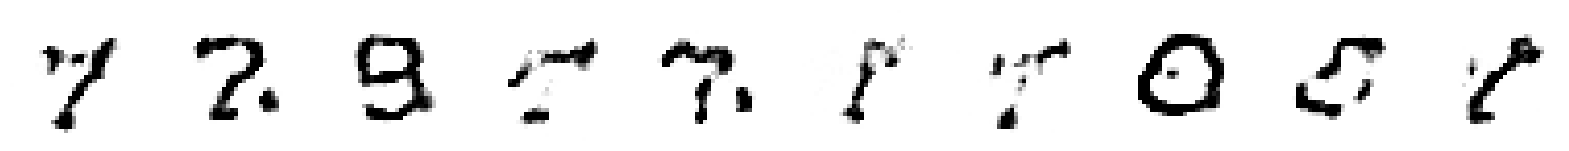


Saved to ./output/example_img_014.png


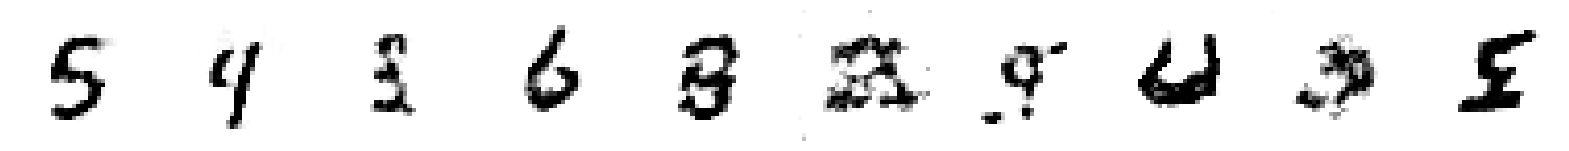

469/469 ━━━━━━━━━━━━━━━━━━━━ 804s 2s/step - cdiv: -1.5553e-04 - fake: 0.0011 - loss: 3.1556e-05 - real: 0.0012 - reg: 1.8709e-04 - val_cdiv: -6.1344 - val_fake: -6.1247 - val_real: 0.0097
Epoch 16/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.7266e-04 - fake: -0.0013 - loss: -2.6127e-04 - real: -7.9729e-04 - reg: 2.1140e-04
Saved to ./output/generated_img_015.png


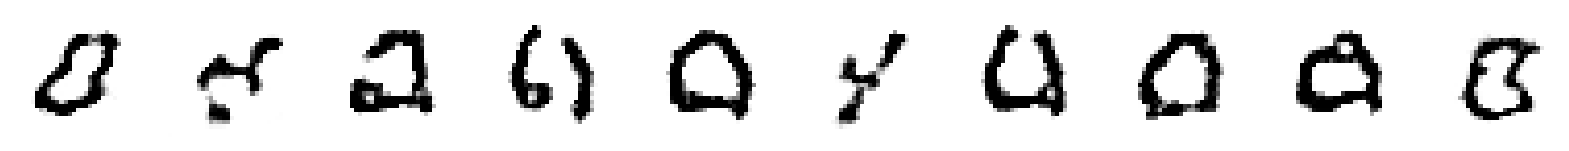


Saved to ./output/example_img_015.png


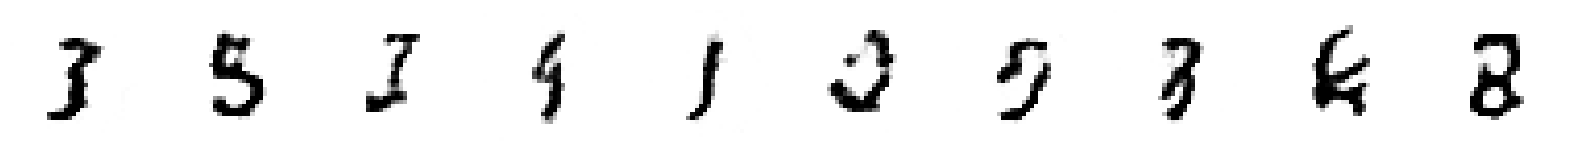

469/469 ━━━━━━━━━━━━━━━━━━━━ 787s 2s/step - cdiv: -3.7275e-04 - fake: 6.1794e-04 - loss: -2.0331e-04 - real: 9.9069e-04 - reg: 1.6944e-04 - val_cdiv: -6.5467 - val_fake: -6.5406 - val_real: 0.0061
Epoch 17/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.6559e-04 - fake: -0.0014 - loss: -2.2540e-04 - real: -9.6237e-04 - reg: 2.4019e-04
Saved to ./output/generated_img_016.png


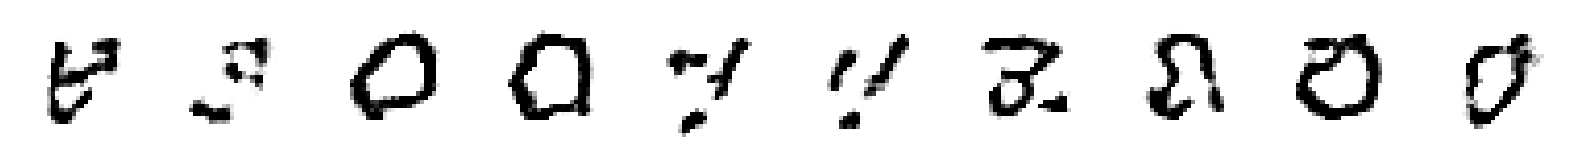


Saved to ./output/example_img_016.png


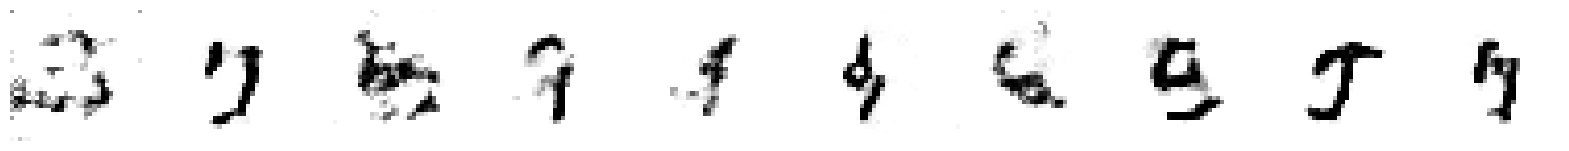

469/469 ━━━━━━━━━━━━━━━━━━━━ 792s 2s/step - cdiv: -9.3446e-06 - fake: 9.3631e-04 - loss: 1.7446e-04 - real: 9.4565e-04 - reg: 1.8381e-04 - val_cdiv: -6.8753 - val_fake: -6.8652 - val_real: 0.0101
Epoch 18/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7342e-04 - fake: -0.0010 - loss: 2.0337e-05 - real: -8.3951e-04 - reg: 1.9376e-04
Saved to ./output/generated_img_017.png


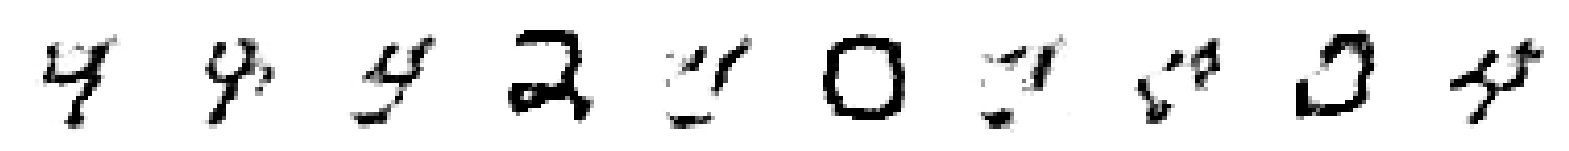


Saved to ./output/example_img_017.png


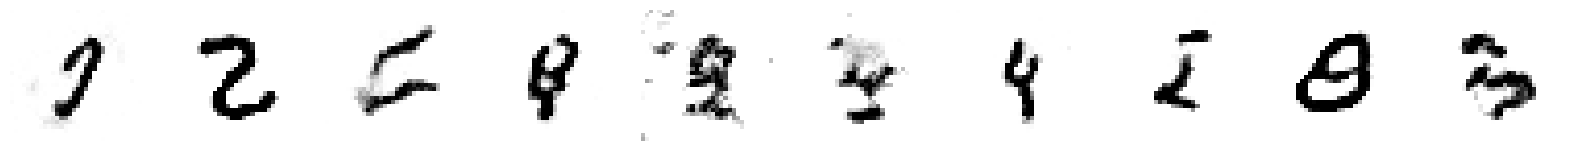

469/469 ━━━━━━━━━━━━━━━━━━━━ 790s 2s/step - cdiv: 5.5697e-05 - fake: 9.2217e-04 - loss: 2.0330e-04 - real: 8.6648e-04 - reg: 1.4760e-04 - val_cdiv: -7.2013 - val_fake: -7.1868 - val_real: 0.0145
Epoch 19/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.5065e-04 - fake: -5.7643e-04 - loss: -2.0238e-04 - real: -2.2578e-04 - reg: 1.4827e-04
Saved to ./output/generated_img_018.png


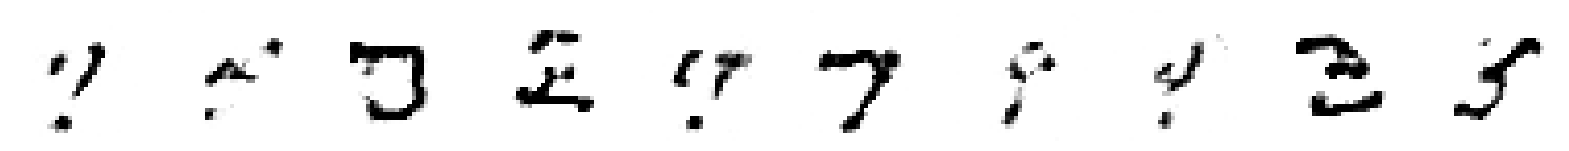


Saved to ./output/example_img_018.png


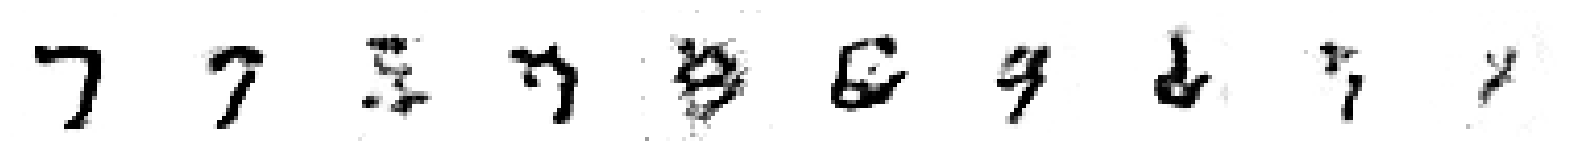

469/469 ━━━━━━━━━━━━━━━━━━━━ 789s 2s/step - cdiv: -8.2292e-05 - fake: 4.5519e-04 - loss: 4.7591e-05 - real: 5.3748e-04 - reg: 1.2988e-04 - val_cdiv: -7.4756 - val_fake: -7.4744 - val_real: 0.0012
Epoch 20/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.3779e-04 - fake: -6.3364e-04 - loss: -1.8370e-04 - real: -2.9585e-04 - reg: 1.5408e-04
Saved to ./output/generated_img_019.png


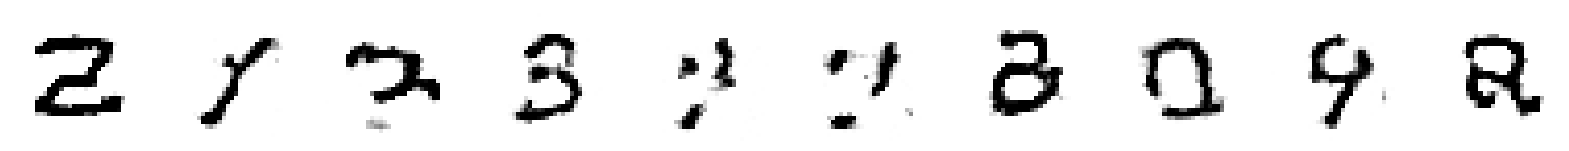


Saved to ./output/example_img_019.png


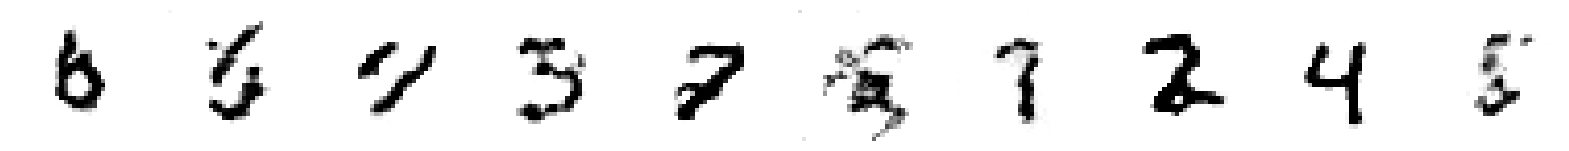

469/469 ━━━━━━━━━━━━━━━━━━━━ 771s 2s/step - cdiv: 6.4128e-05 - fake: 6.3700e-04 - loss: 2.0514e-04 - real: 5.7287e-04 - reg: 1.4101e-04 - val_cdiv: -7.7224 - val_fake: -7.7099 - val_real: 0.0124
Epoch 21/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -7.1085e-04 - fake: -4.7129e-04 - loss: -5.6122e-04 - real: 2.3956e-04 - reg: 1.4963e-04
Saved to ./output/generated_img_020.png


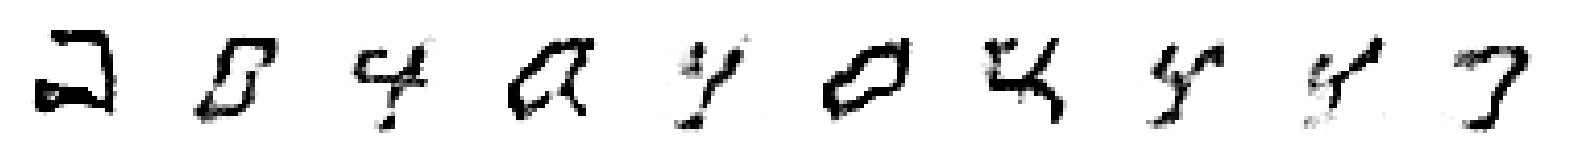


Saved to ./output/example_img_020.png


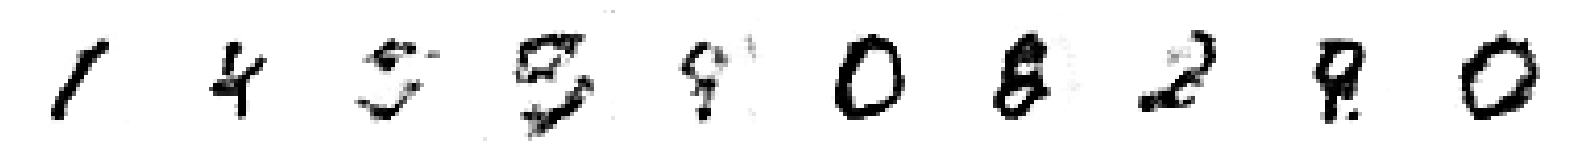

469/469 ━━━━━━━━━━━━━━━━━━━━ 769s 2s/step - cdiv: -1.6838e-04 - fake: 5.5896e-04 - loss: -3.2761e-05 - real: 7.2734e-04 - reg: 1.3562e-04 - val_cdiv: -8.1393 - val_fake: -8.1289 - val_real: 0.0105
Epoch 22/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.7762e-04 - fake: -8.8007e-04 - loss: -1.1755e-04 - real: -6.0245e-04 - reg: 1.6007e-04
Saved to ./output/generated_img_021.png


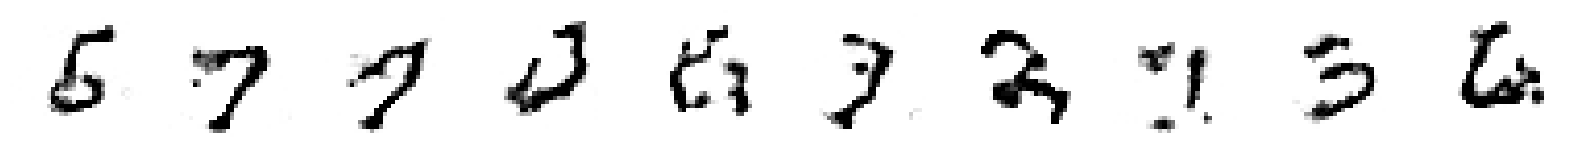


Saved to ./output/example_img_021.png


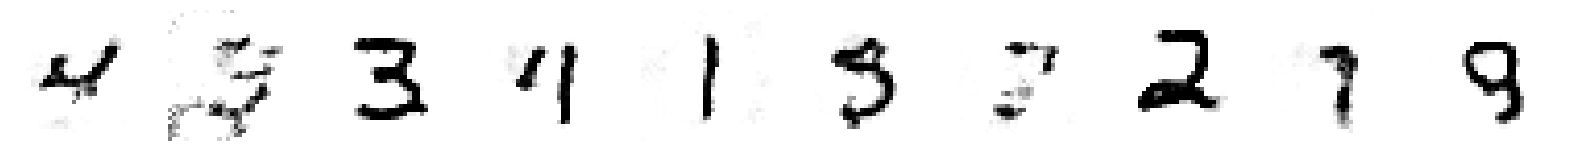

469/469 ━━━━━━━━━━━━━━━━━━━━ 769s 2s/step - cdiv: 1.5269e-05 - fake: 6.8206e-04 - loss: 1.5185e-04 - real: 6.6679e-04 - reg: 1.3658e-04 - val_cdiv: -8.3558 - val_fake: -8.3437 - val_real: 0.0121
Epoch 23/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.9627e-04 - fake: -6.8117e-04 - loss: -1.2465e-04 - real: -3.8490e-04 - reg: 1.7162e-04
Saved to ./output/generated_img_022.png


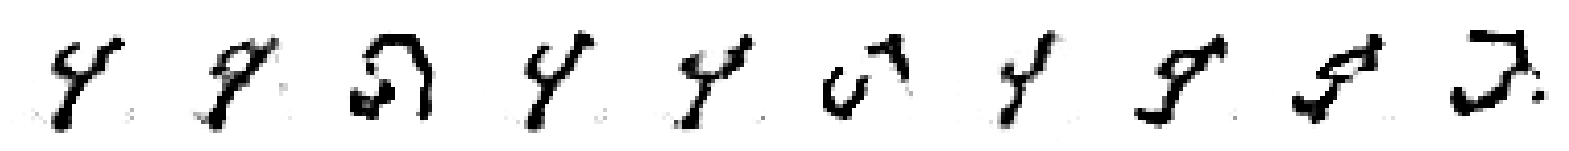


Saved to ./output/example_img_022.png


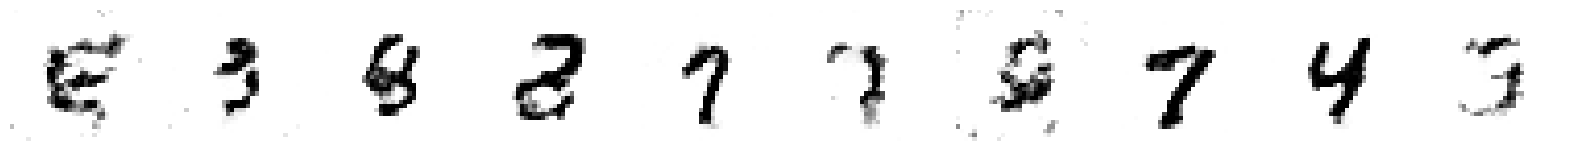

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: -5.8755e-05 - fake: 3.9359e-04 - loss: 7.6317e-05 - real: 4.5235e-04 - reg: 1.3507e-04 - val_cdiv: -8.6830 - val_fake: -8.6668 - val_real: 0.0163
Epoch 24/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.0530e-05 - fake: 9.3832e-05 - loss: 8.8466e-05 - real: 1.3436e-04 - reg: 1.2900e-04
Saved to ./output/generated_img_023.png


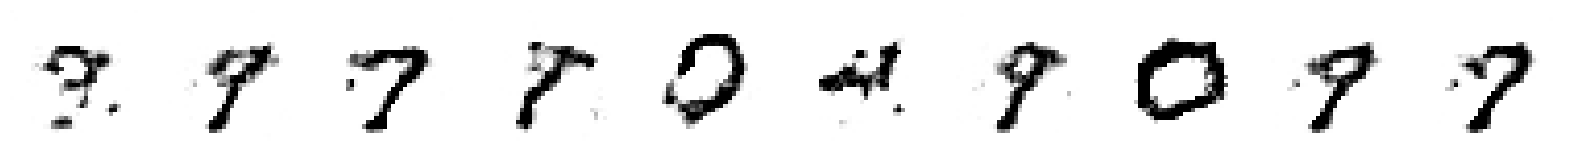


Saved to ./output/example_img_023.png


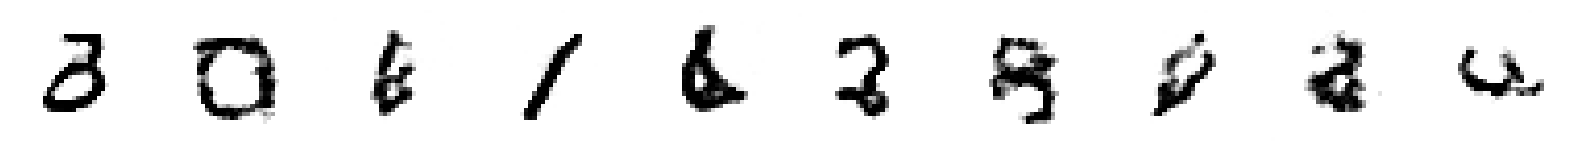

469/469 ━━━━━━━━━━━━━━━━━━━━ 765s 2s/step - cdiv: 2.0316e-04 - fake: 7.1981e-04 - loss: 3.0759e-04 - real: 5.1666e-04 - reg: 1.0443e-04 - val_cdiv: -8.9684 - val_fake: -8.9531 - val_real: 0.0153
Epoch 25/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.5800e-04 - fake: 2.0258e-05 - loss: -1.3913e-04 - real: 2.7825e-04 - reg: 1.1887e-04
Saved to ./output/generated_img_024.png


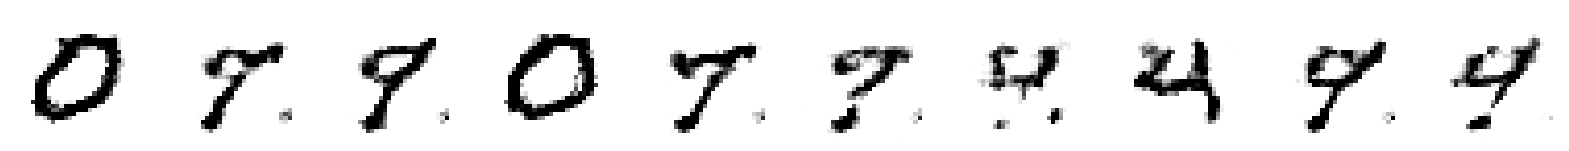


Saved to ./output/example_img_024.png


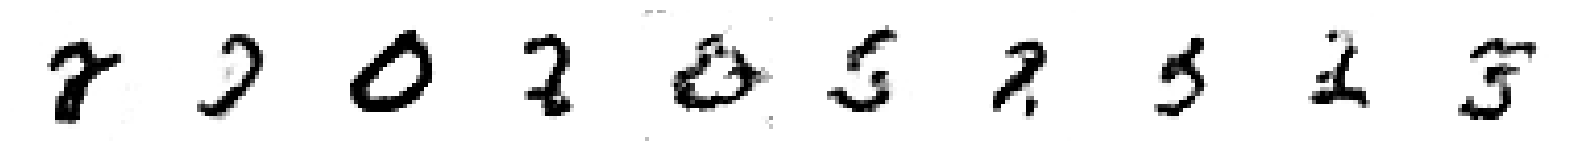

469/469 ━━━━━━━━━━━━━━━━━━━━ 776s 2s/step - cdiv: -2.0321e-04 - fake: 2.9247e-04 - loss: -9.6228e-05 - real: 4.9568e-04 - reg: 1.0698e-04 - val_cdiv: -9.4789 - val_fake: -9.4598 - val_real: 0.0192
Epoch 26/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7790e-04 - fake: 3.6198e-04 - loss: -2.1948e-05 - real: 5.3988e-04 - reg: 1.5595e-04
Saved to ./output/generated_img_025.png


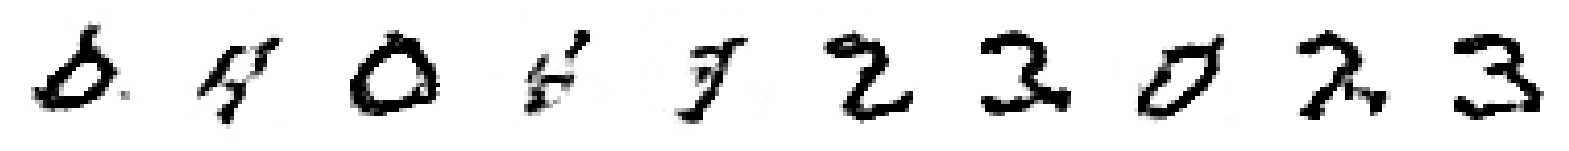


Saved to ./output/example_img_025.png


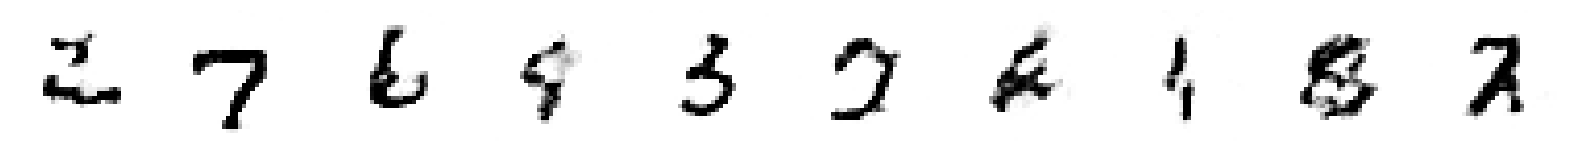

469/469 ━━━━━━━━━━━━━━━━━━━━ 773s 2s/step - cdiv: 4.0118e-05 - fake: 6.8257e-04 - loss: 1.6136e-04 - real: 6.4245e-04 - reg: 1.2124e-04 - val_cdiv: -9.7386 - val_fake: -9.7287 - val_real: 0.0099
Epoch 27/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.5871e-04 - fake: 4.9455e-05 - loss: -1.1214e-04 - real: 3.0816e-04 - reg: 1.4657e-04
Saved to ./output/generated_img_026.png


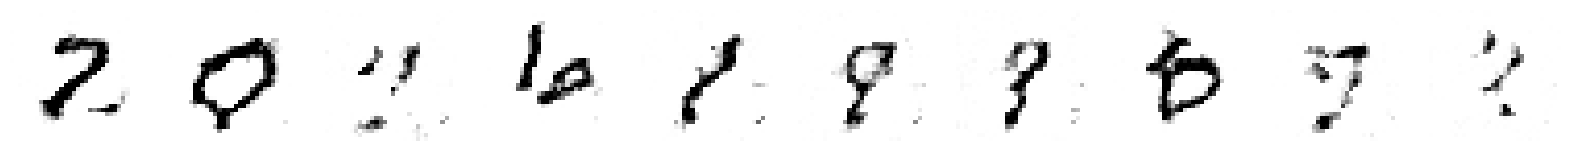


Saved to ./output/example_img_026.png


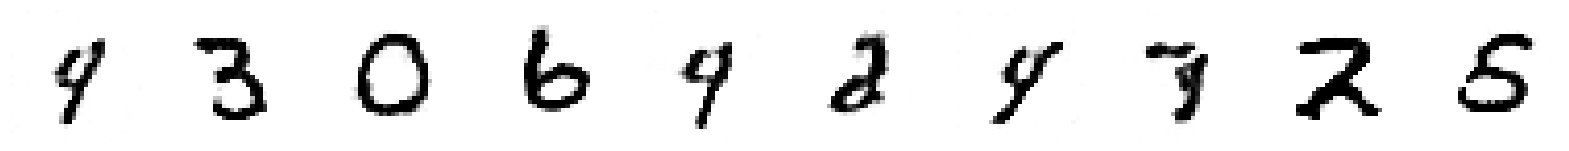

469/469 ━━━━━━━━━━━━━━━━━━━━ 776s 2s/step - cdiv: 1.1892e-04 - fake: 6.0544e-04 - loss: 2.4195e-04 - real: 4.8652e-04 - reg: 1.2303e-04 - val_cdiv: -10.0893 - val_fake: -10.0755 - val_real: 0.0138
Epoch 28/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.5594e-04 - fake: 1.3543e-04 - loss: -1.1542e-04 - real: 3.9137e-04 - reg: 1.4052e-04
Saved to ./output/generated_img_027.png


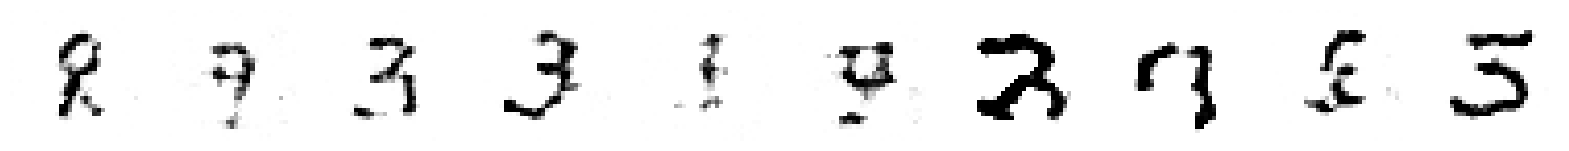


Saved to ./output/example_img_027.png


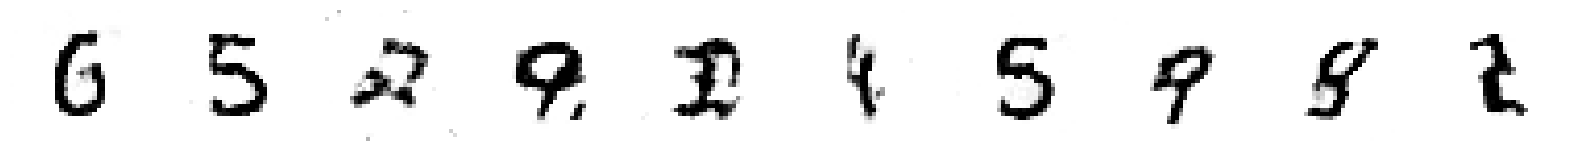

469/469 ━━━━━━━━━━━━━━━━━━━━ 773s 2s/step - cdiv: 7.3388e-05 - fake: 6.7129e-04 - loss: 1.9139e-04 - real: 5.9790e-04 - reg: 1.1801e-04 - val_cdiv: -10.2934 - val_fake: -10.2860 - val_real: 0.0074
Epoch 29/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 4.6970e-05 - fake: 2.7557e-04 - loss: 1.5004e-04 - real: 2.2860e-04 - reg: 1.0307e-04
Saved to ./output/generated_img_028.png


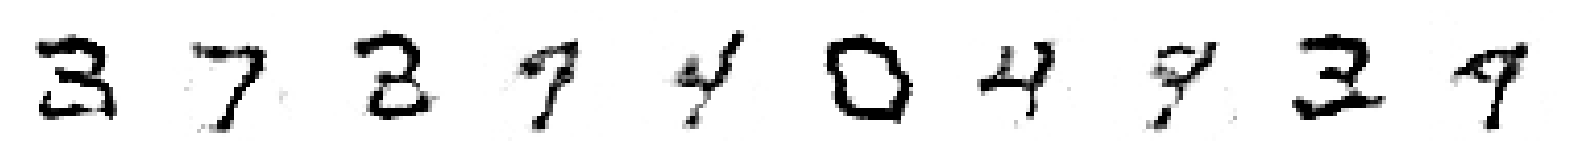


Saved to ./output/example_img_028.png


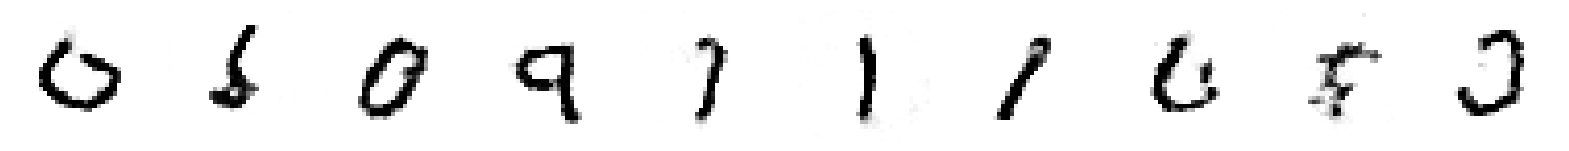

469/469 ━━━━━━━━━━━━━━━━━━━━ 762s 2s/step - cdiv: 1.1926e-04 - fake: 6.1193e-04 - loss: 2.1717e-04 - real: 4.9267e-04 - reg: 9.7908e-05 - val_cdiv: -10.7426 - val_fake: -10.7296 - val_real: 0.0130
Epoch 30/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9505e-04 - fake: 4.2487e-04 - loss: -5.1690e-05 - real: 6.1992e-04 - reg: 1.4336e-04
Saved to ./output/generated_img_029.png


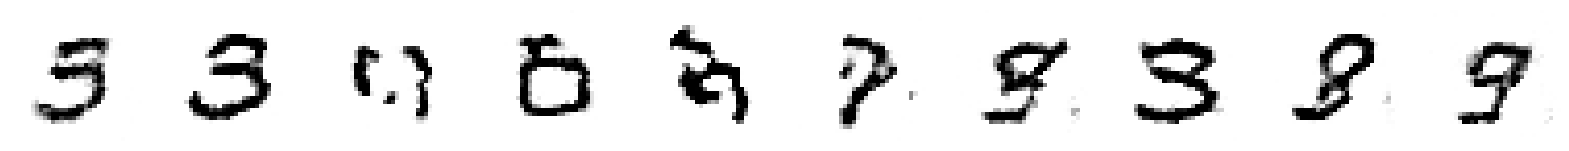


Saved to ./output/example_img_029.png


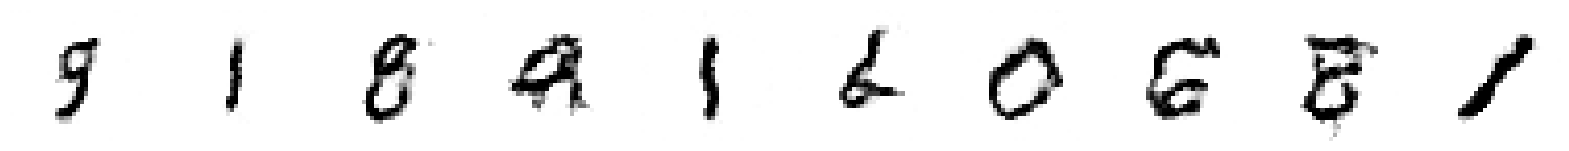

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: -4.9044e-05 - fake: 4.1722e-04 - loss: 5.7968e-05 - real: 4.6627e-04 - reg: 1.0701e-04 - val_cdiv: -10.8822 - val_fake: -10.8764 - val_real: 0.0057
Epoch 31/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7242e-04 - fake: 3.2043e-04 - loss: -5.3857e-05 - real: 4.9285e-04 - reg: 1.1856e-04
Saved to ./output/generated_img_030.png


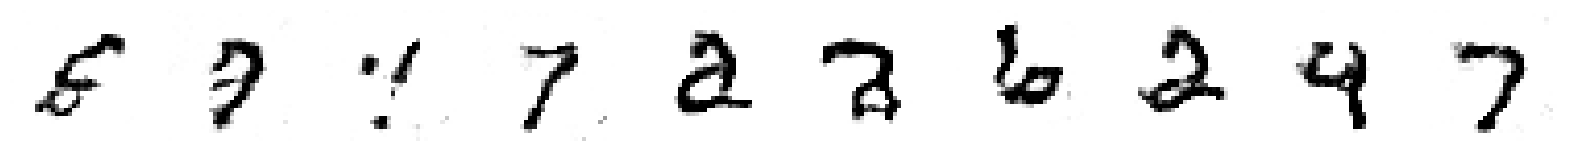


Saved to ./output/example_img_030.png


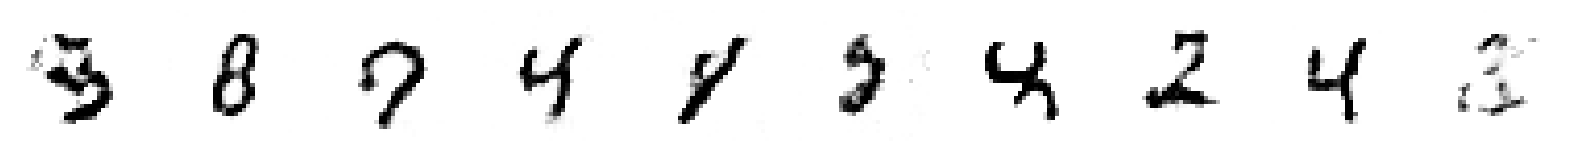

469/469 ━━━━━━━━━━━━━━━━━━━━ 764s 2s/step - cdiv: 2.9428e-05 - fake: 4.9885e-04 - loss: 1.4396e-04 - real: 4.6942e-04 - reg: 1.1453e-04 - val_cdiv: -11.1041 - val_fake: -11.0897 - val_real: 0.0144
Epoch 32/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -9.6004e-06 - fake: 9.7156e-04 - loss: 1.2009e-04 - real: 9.8116e-04 - reg: 1.2969e-04
Saved to ./output/generated_img_031.png


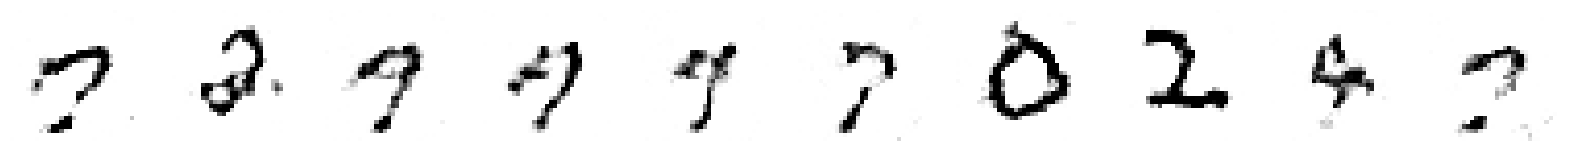


Saved to ./output/example_img_031.png


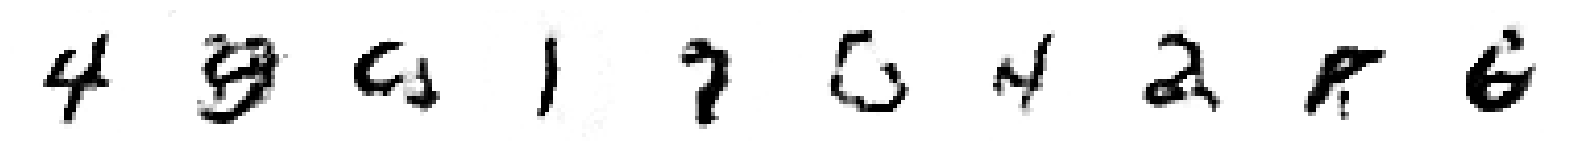

469/469 ━━━━━━━━━━━━━━━━━━━━ 761s 2s/step - cdiv: 8.2450e-05 - fake: 7.4621e-04 - loss: 1.9162e-04 - real: 6.6376e-04 - reg: 1.0917e-04 - val_cdiv: -11.4915 - val_fake: -11.4747 - val_real: 0.0168
Epoch 33/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 5.7321e-05 - fake: 5.0943e-04 - loss: 1.8193e-04 - real: 4.5210e-04 - reg: 1.2461e-04
Saved to ./output/generated_img_032.png


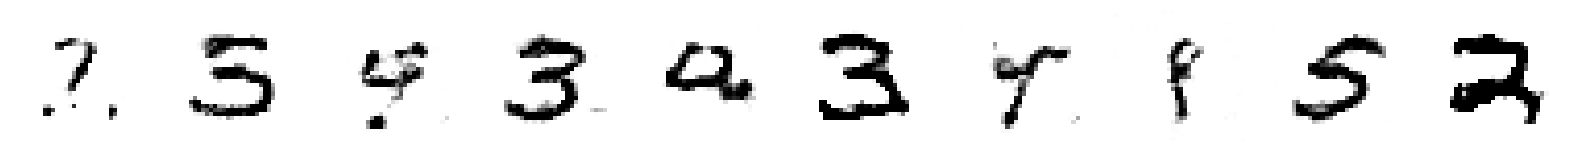


Saved to ./output/example_img_032.png


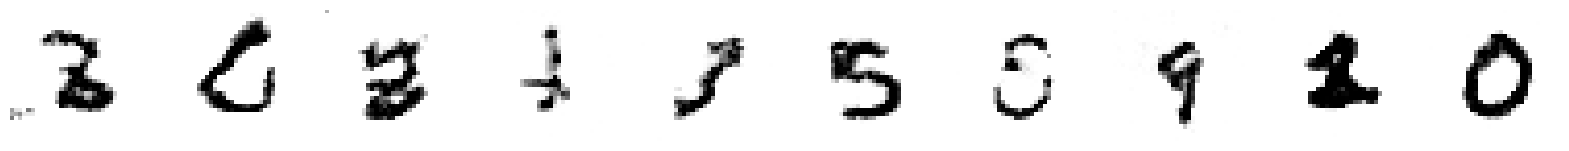

469/469 ━━━━━━━━━━━━━━━━━━━━ 759s 2s/step - cdiv: 6.7532e-05 - fake: 4.9394e-04 - loss: 1.7705e-04 - real: 4.2641e-04 - reg: 1.0952e-04 - val_cdiv: -11.7816 - val_fake: -11.7734 - val_real: 0.0082
Epoch 34/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.4165e-04 - fake: -4.4119e-05 - loss: -1.0521e-04 - real: 1.9753e-04 - reg: 1.3644e-04
Saved to ./output/generated_img_033.png


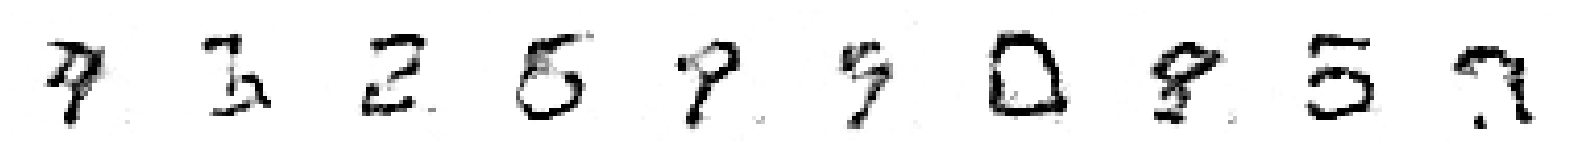


Saved to ./output/example_img_033.png


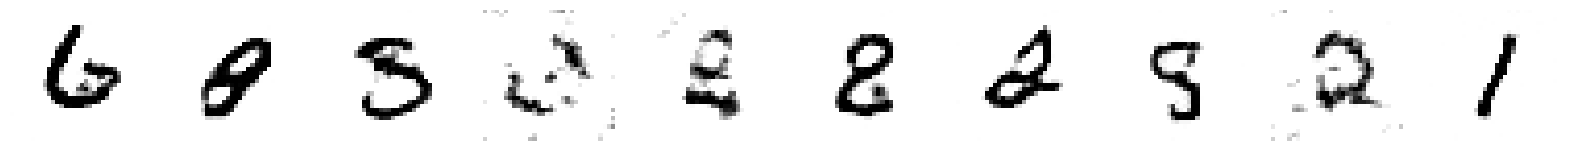

469/469 ━━━━━━━━━━━━━━━━━━━━ 753s 2s/step - cdiv: 1.8207e-04 - fake: 7.1419e-04 - loss: 2.8952e-04 - real: 5.3212e-04 - reg: 1.0745e-04 - val_cdiv: -12.0326 - val_fake: -12.0241 - val_real: 0.0085
Epoch 35/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.6420e-04 - fake: -3.1668e-04 - loss: -1.5391e-04 - real: -5.2484e-05 - reg: 1.1029e-04
Saved to ./output/generated_img_034.png


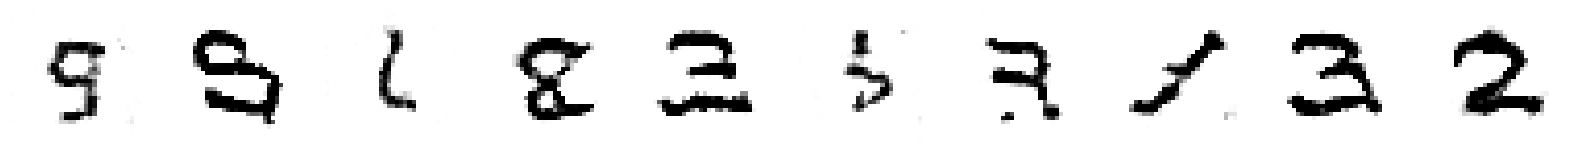


Saved to ./output/example_img_034.png


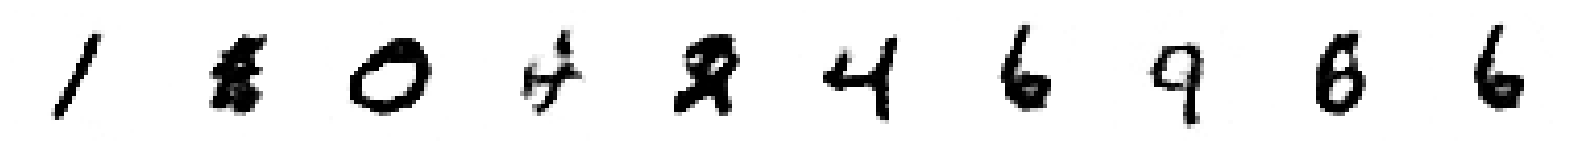

469/469 ━━━━━━━━━━━━━━━━━━━━ 754s 2s/step - cdiv: 2.3954e-05 - fake: 3.1812e-04 - loss: 1.3102e-04 - real: 2.9416e-04 - reg: 1.0707e-04 - val_cdiv: -12.2411 - val_fake: -12.2300 - val_real: 0.0112
Epoch 36/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -9.0117e-05 - fake: 3.5783e-04 - loss: 9.2169e-06 - real: 4.4795e-04 - reg: 9.9333e-05
Saved to ./output/generated_img_035.png


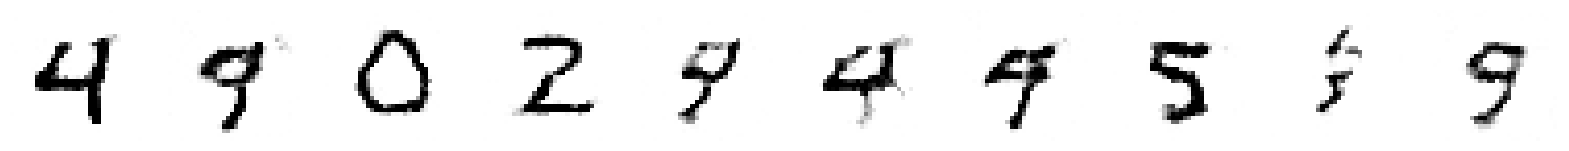


Saved to ./output/example_img_035.png


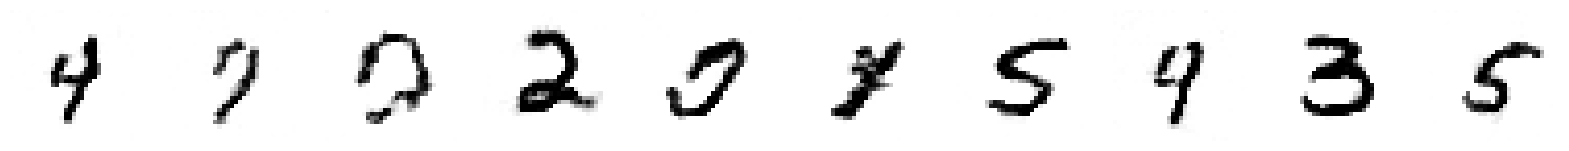

469/469 ━━━━━━━━━━━━━━━━━━━━ 755s 2s/step - cdiv: 3.0848e-05 - fake: 5.0728e-04 - loss: 1.2613e-04 - real: 4.7643e-04 - reg: 9.5284e-05 - val_cdiv: -12.7548 - val_fake: -12.7488 - val_real: 0.0060
Epoch 37/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.8974e-04 - fake: 2.9898e-04 - loss: -1.5620e-04 - real: 5.8872e-04 - reg: 1.3354e-04
Saved to ./output/generated_img_036.png


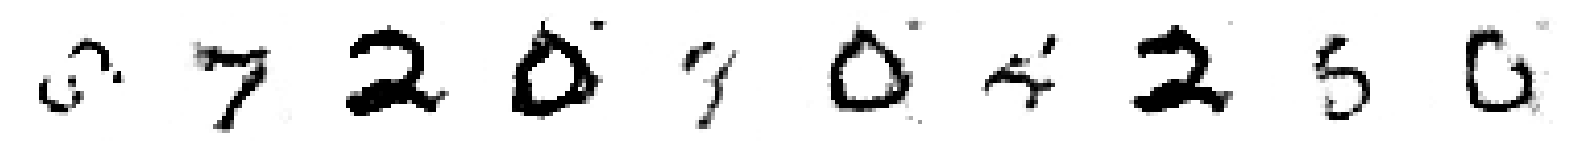


Saved to ./output/example_img_036.png


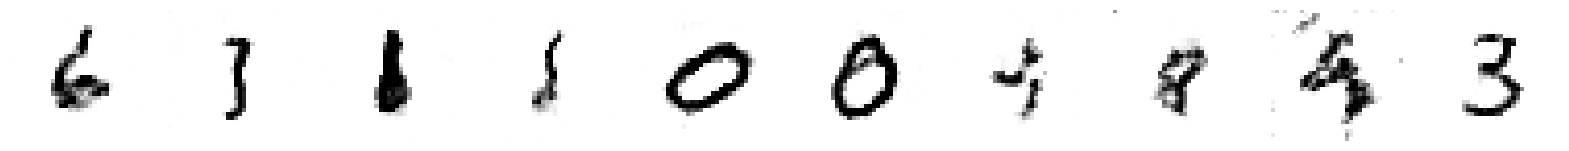

469/469 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - cdiv: 6.3278e-05 - fake: 4.3877e-04 - loss: 1.8211e-04 - real: 3.7549e-04 - reg: 1.1883e-04 - val_cdiv: -12.9285 - val_fake: -12.9218 - val_real: 0.0067
Epoch 38/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.2954e-04 - fake: 4.6813e-04 - loss: -2.9328e-05 - real: 5.9766e-04 - reg: 1.0021e-04
Saved to ./output/generated_img_037.png


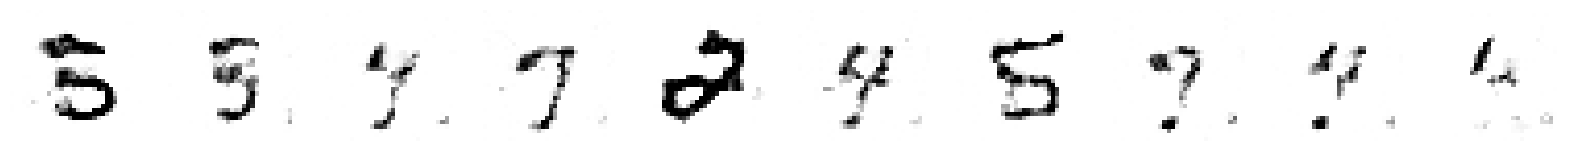


Saved to ./output/example_img_037.png


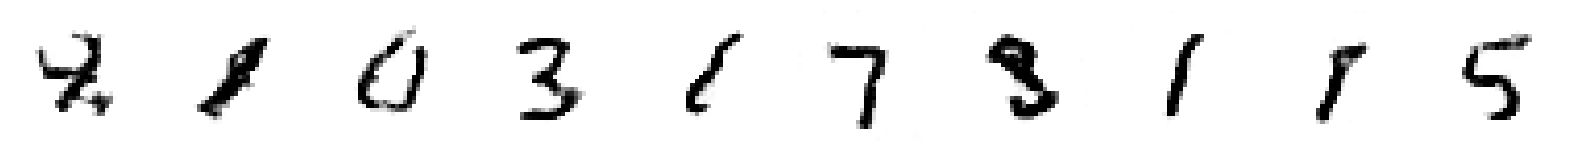

469/469 ━━━━━━━━━━━━━━━━━━━━ 748s 2s/step - cdiv: 1.0869e-04 - fake: 4.5656e-04 - loss: 2.0495e-04 - real: 3.4787e-04 - reg: 9.6261e-05 - val_cdiv: -13.3882 - val_fake: -13.3776 - val_real: 0.0106
Epoch 39/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9385e-04 - fake: 8.1617e-04 - loss: -7.2694e-05 - real: 0.0010 - reg: 1.2115e-04
Saved to ./output/generated_img_038.png


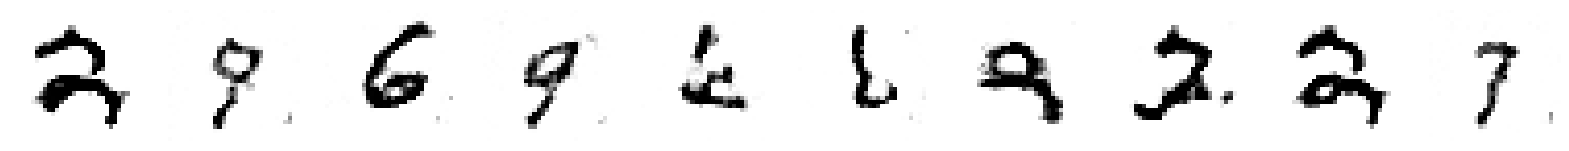


Saved to ./output/example_img_038.png


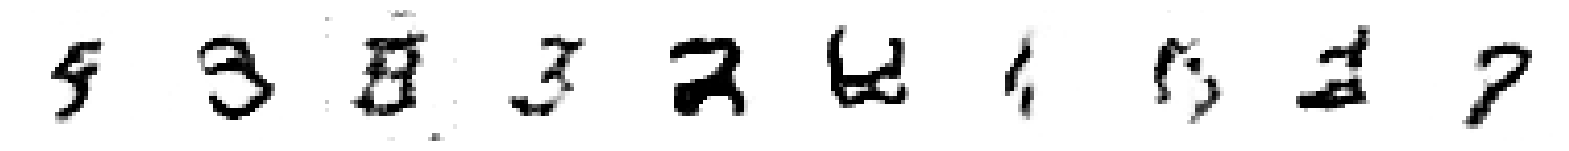

469/469 ━━━━━━━━━━━━━━━━━━━━ 747s 2s/step - cdiv: -4.9151e-05 - fake: 4.0083e-04 - loss: 5.9570e-05 - real: 4.4998e-04 - reg: 1.0872e-04 - val_cdiv: -13.7779 - val_fake: -13.7698 - val_real: 0.0082
Epoch 40/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -7.2123e-05 - fake: 4.8090e-04 - loss: 3.8991e-05 - real: 5.5302e-04 - reg: 1.1111e-04
Saved to ./output/generated_img_039.png


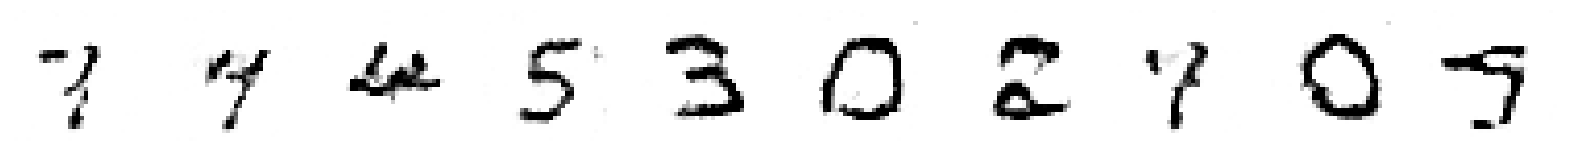


Saved to ./output/example_img_039.png


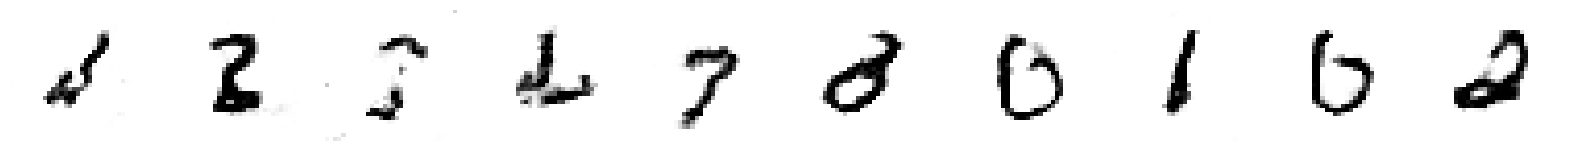

469/469 ━━━━━━━━━━━━━━━━━━━━ 749s 2s/step - cdiv: 3.3033e-05 - fake: 4.2170e-04 - loss: 1.4284e-04 - real: 3.8867e-04 - reg: 1.0981e-04 - val_cdiv: -13.9763 - val_fake: -13.9700 - val_real: 0.0062
Epoch 41/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.0789e-04 - fake: 5.8625e-04 - loss: -8.4250e-05 - real: 7.9415e-04 - reg: 1.2364e-04
Saved to ./output/generated_img_040.png


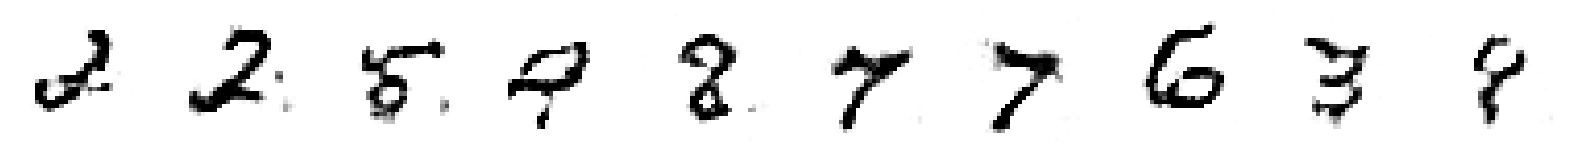


Saved to ./output/example_img_040.png


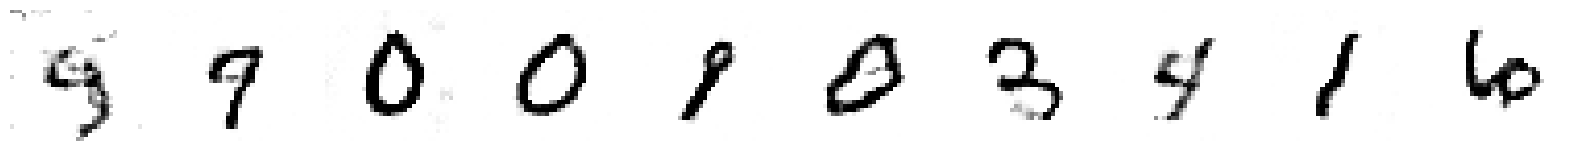

469/469 ━━━━━━━━━━━━━━━━━━━━ 748s 2s/step - cdiv: -1.7062e-05 - fake: 3.8252e-04 - loss: 9.4177e-05 - real: 3.9958e-04 - reg: 1.1124e-04 - val_cdiv: -14.7109 - val_fake: -14.7085 - val_real: 0.0024
Epoch 42/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -5.1805e-06 - fake: 7.6911e-04 - loss: 1.0478e-04 - real: 7.7429e-04 - reg: 1.0996e-04
Saved to ./output/generated_img_041.png


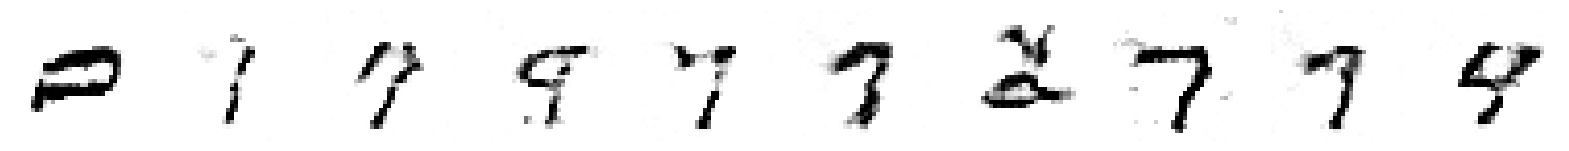


Saved to ./output/example_img_041.png


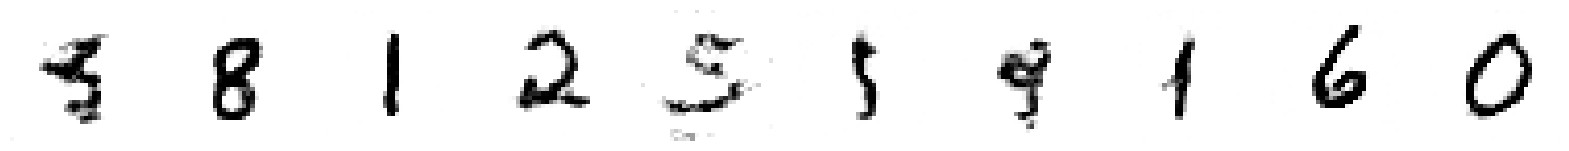

469/469 ━━━━━━━━━━━━━━━━━━━━ 752s 2s/step - cdiv: 1.7342e-04 - fake: 4.8135e-04 - loss: 2.7254e-04 - real: 3.0793e-04 - reg: 9.9115e-05 - val_cdiv: -15.0616 - val_fake: -15.0441 - val_real: 0.0175
Epoch 43/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.4173e-04 - fake: 0.0011 - loss: -3.8468e-05 - real: 0.0012 - reg: 1.0326e-04
Saved to ./output/generated_img_042.png


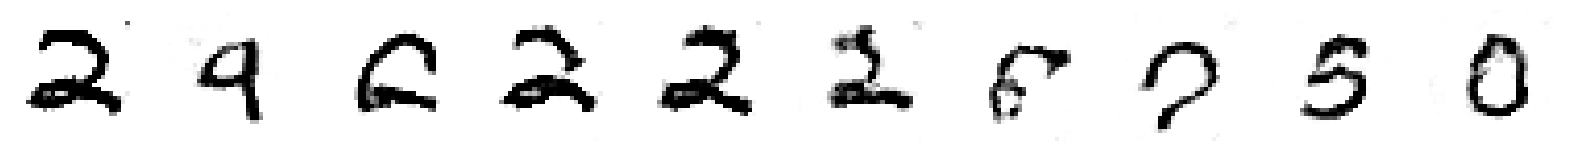


Saved to ./output/example_img_042.png


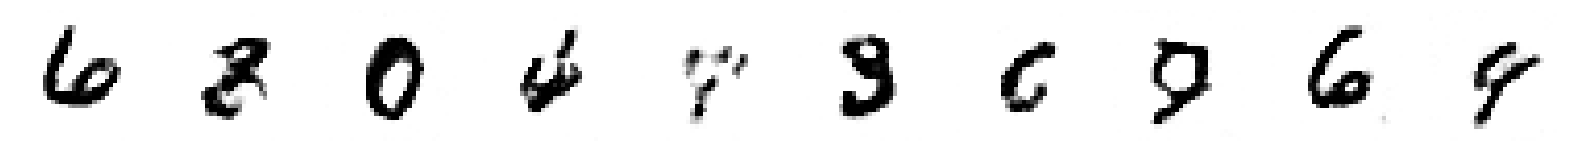

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: 4.1196e-05 - fake: 5.6094e-04 - loss: 1.1823e-04 - real: 5.1974e-04 - reg: 7.7037e-05 - val_cdiv: -15.3229 - val_fake: -15.3240 - val_real: -0.0011
Epoch 44/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 2.8382e-05 - fake: 1.9582e-04 - loss: 1.1922e-04 - real: 1.6743e-04 - reg: 9.0843e-05
Saved to ./output/generated_img_043.png


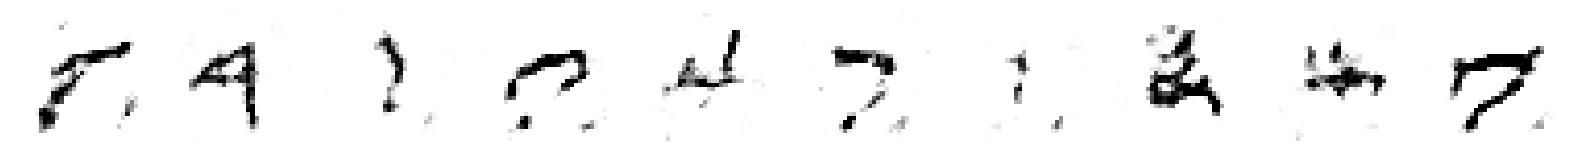


Saved to ./output/example_img_043.png


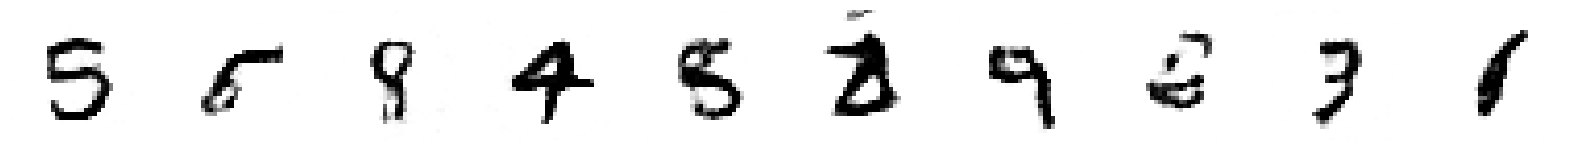

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: 1.3082e-04 - fake: 5.4289e-04 - loss: 2.1865e-04 - real: 4.1207e-04 - reg: 8.7828e-05 - val_cdiv: -15.6328 - val_fake: -15.6178 - val_real: 0.0150
Epoch 45/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -5.3098e-04 - fake: 6.0120e-05 - loss: -3.9477e-04 - real: 5.9110e-04 - reg: 1.3621e-04
Saved to ./output/generated_img_044.png


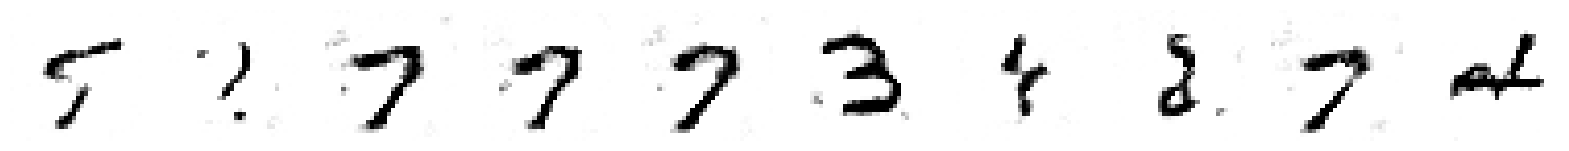


Saved to ./output/example_img_044.png


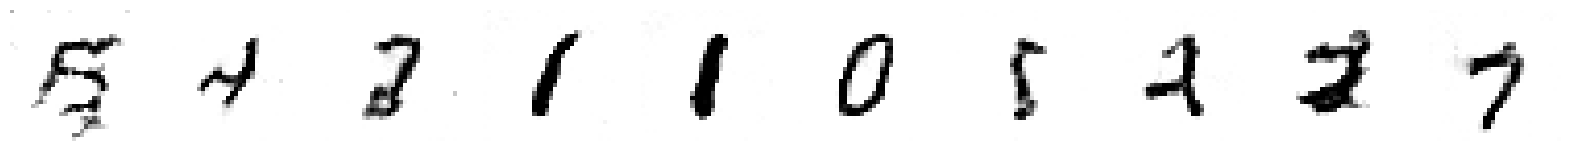

469/469 ━━━━━━━━━━━━━━━━━━━━ 754s 2s/step - cdiv: -1.6000e-04 - fake: 4.0489e-04 - loss: -5.7284e-05 - real: 5.6488e-04 - reg: 1.0271e-04 - val_cdiv: -16.3731 - val_fake: -16.3670 - val_real: 0.0061
Epoch 46/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.1725e-04 - fake: -4.4529e-05 - loss: -1.8788e-04 - real: 2.7272e-04 - reg: 1.2937e-04
Saved to ./output/generated_img_045.png


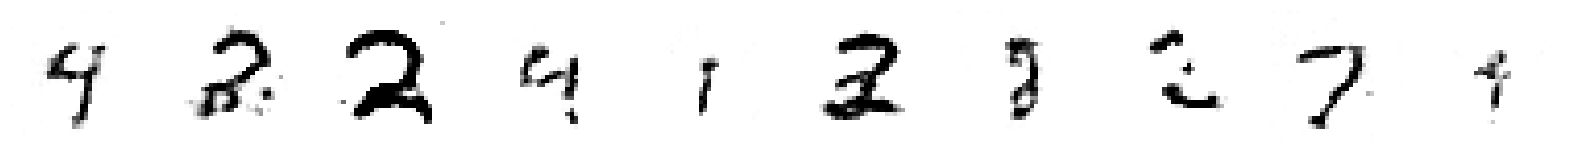


Saved to ./output/example_img_045.png


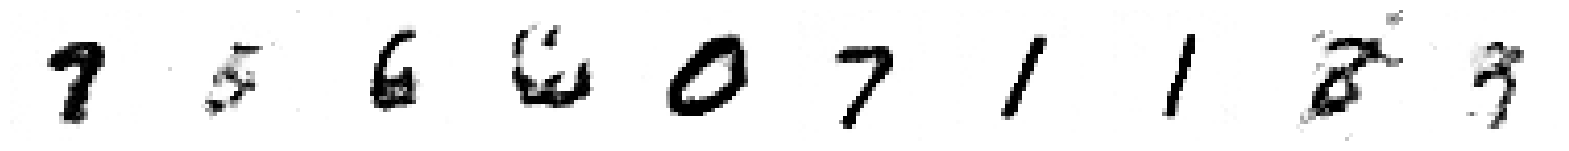

469/469 ━━━━━━━━━━━━━━━━━━━━ 755s 2s/step - cdiv: 1.7754e-04 - fake: 2.5337e-04 - loss: 2.8167e-04 - real: 7.5833e-05 - reg: 1.0413e-04 - val_cdiv: -16.7459 - val_fake: -16.7383 - val_real: 0.0077
Epoch 47/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.1421e-04 - fake: 6.4934e-04 - loss: -1.0489e-04 - real: 8.6355e-04 - reg: 1.0932e-04
Saved to ./output/generated_img_046.png


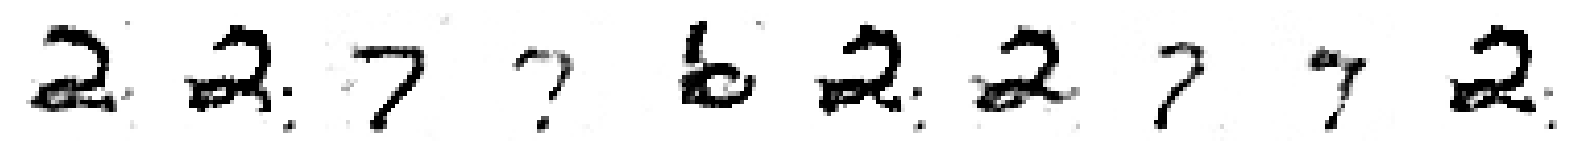


Saved to ./output/example_img_046.png


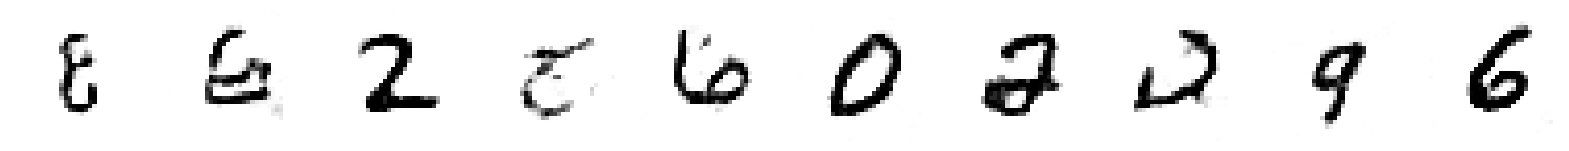

469/469 ━━━━━━━━━━━━━━━━━━━━ 749s 2s/step - cdiv: -2.7419e-05 - fake: 5.1398e-04 - loss: 7.0779e-05 - real: 5.4140e-04 - reg: 9.8198e-05 - val_cdiv: -17.0921 - val_fake: -17.0839 - val_real: 0.0083
Epoch 48/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: 2.9983e-04 - fake: 6.0491e-04 - loss: 3.8505e-04 - real: 3.0507e-04 - reg: 8.5215e-05
Saved to ./output/generated_img_047.png


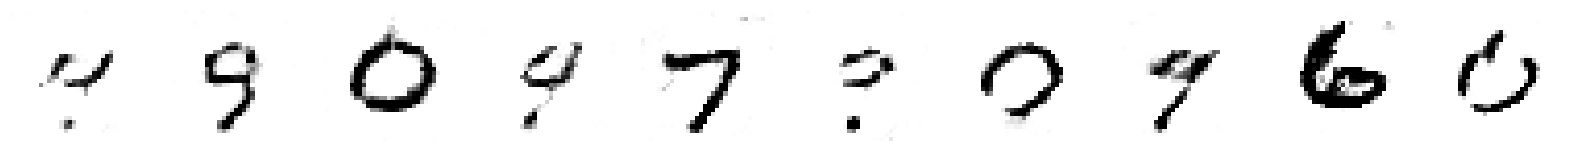


Saved to ./output/example_img_047.png


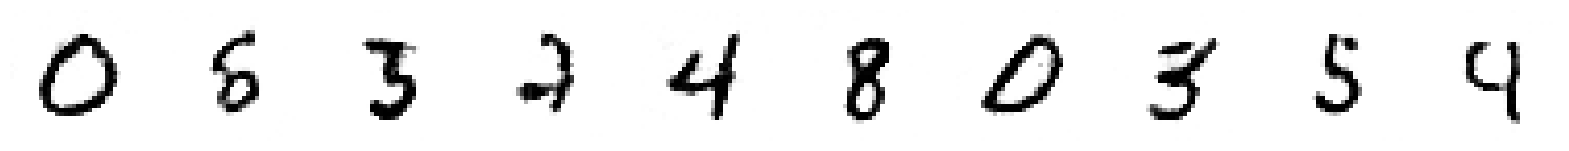

469/469 ━━━━━━━━━━━━━━━━━━━━ 771s 2s/step - cdiv: 1.3502e-04 - fake: 2.3691e-04 - loss: 2.1261e-04 - real: 1.0189e-04 - reg: 7.7590e-05 - val_cdiv: -17.1587 - val_fake: -17.1539 - val_real: 0.0048
Epoch 49/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.8874e-04 - fake: 2.4189e-04 - loss: -1.7624e-04 - real: 5.3063e-04 - reg: 1.1250e-04
Saved to ./output/generated_img_048.png


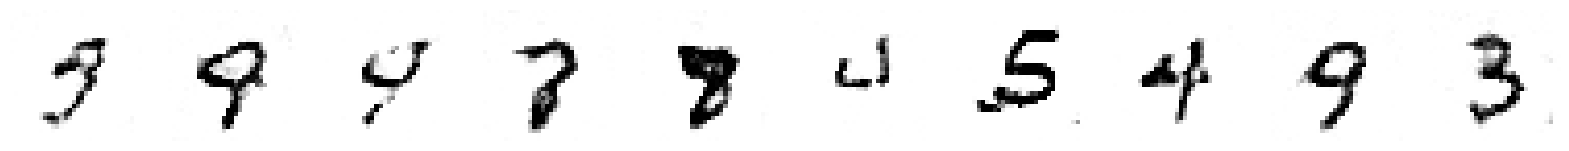


Saved to ./output/example_img_048.png


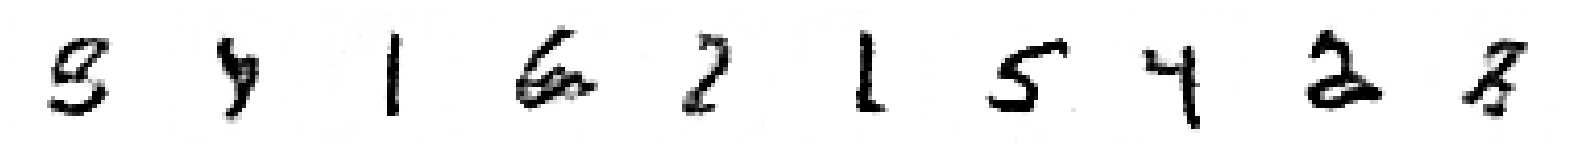

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: 8.4996e-06 - fake: 2.4087e-04 - loss: 1.0467e-04 - real: 2.3237e-04 - reg: 9.6169e-05 - val_cdiv: -17.3725 - val_fake: -17.3668 - val_real: 0.0057
Epoch 50/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.2640e-04 - fake: 2.1409e-04 - loss: -2.9077e-04 - real: 6.4049e-04 - reg: 1.3563e-04
Saved to ./output/generated_img_049.png


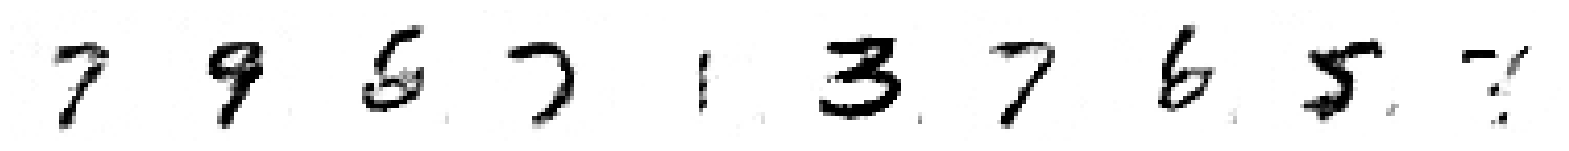


Saved to ./output/example_img_049.png


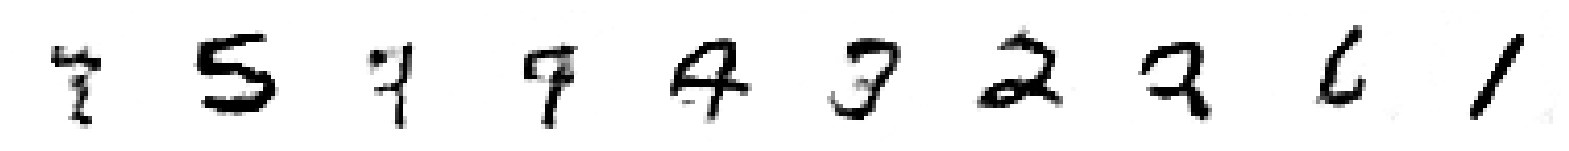

469/469 ━━━━━━━━━━━━━━━━━━━━ 750s 2s/step - cdiv: -3.8696e-05 - fake: 3.6564e-04 - loss: 7.2774e-05 - real: 4.0434e-04 - reg: 1.1147e-04 - val_cdiv: -18.1827 - val_fake: -18.1784 - val_real: 0.0043
Epoch 51/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9095e-04 - fake: 9.8570e-05 - loss: -9.1626e-05 - real: 2.8952e-04 - reg: 9.9327e-05
Saved to ./output/generated_img_050.png


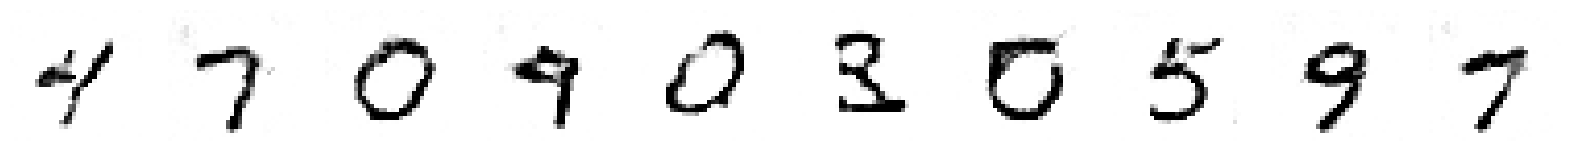


Saved to ./output/example_img_050.png


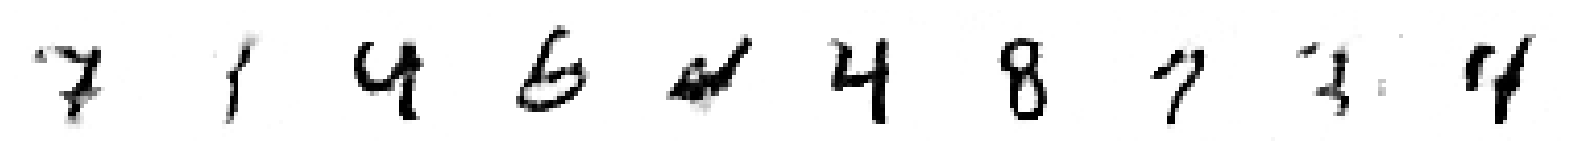

469/469 ━━━━━━━━━━━━━━━━━━━━ 763s 2s/step - cdiv: 6.4758e-06 - fake: 1.8139e-04 - loss: 9.5191e-05 - real: 1.7492e-04 - reg: 8.8715e-05 - val_cdiv: -18.4300 - val_fake: -18.4219 - val_real: 0.0080
Epoch 52/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.1598e-04 - fake: 5.7063e-04 - loss: -6.1611e-06 - real: 6.8660e-04 - reg: 1.0982e-04
Saved to ./output/generated_img_051.png


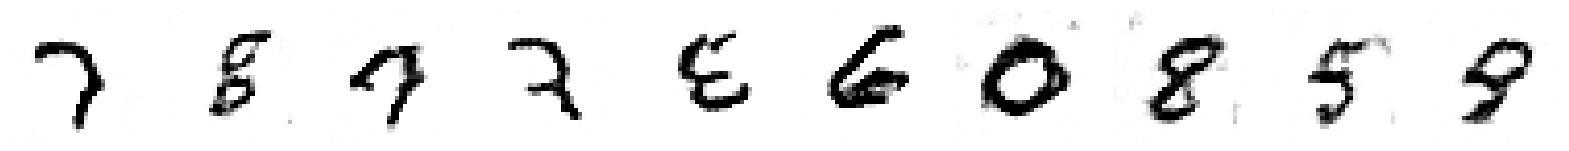


Saved to ./output/example_img_051.png


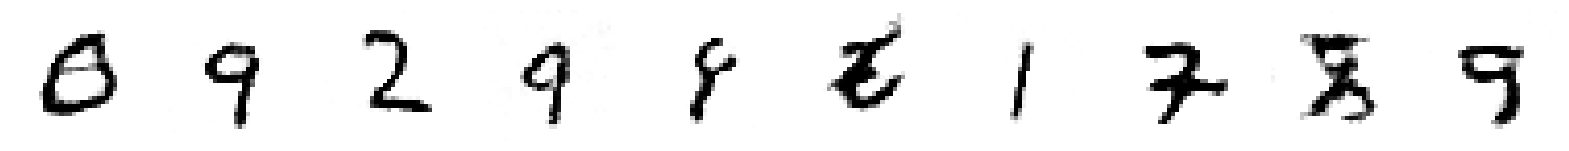

469/469 ━━━━━━━━━━━━━━━━━━━━ 762s 2s/step - cdiv: 1.7236e-04 - fake: 4.0089e-04 - loss: 2.5446e-04 - real: 2.2853e-04 - reg: 8.2097e-05 - val_cdiv: -18.9911 - val_fake: -18.9842 - val_real: 0.0069
Epoch 53/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.9274e-04 - fake: -3.5039e-07 - loss: -3.0223e-04 - real: 3.9239e-04 - reg: 9.0507e-05
Saved to ./output/generated_img_052.png


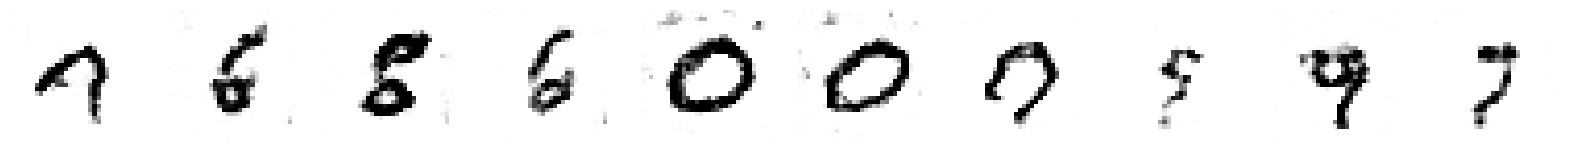


Saved to ./output/example_img_052.png


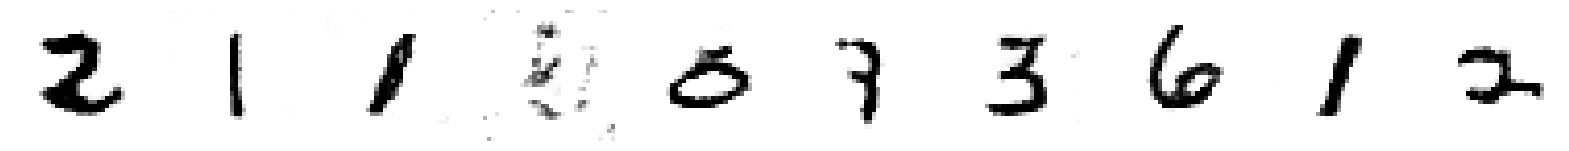

469/469 ━━━━━━━━━━━━━━━━━━━━ 762s 2s/step - cdiv: -1.1759e-05 - fake: 1.1051e-04 - loss: 7.8127e-05 - real: 1.2227e-04 - reg: 8.9886e-05 - val_cdiv: -18.9993 - val_fake: -18.9919 - val_real: 0.0074
Epoch 54/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.1113e-04 - fake: 1.6439e-04 - loss: -2.9593e-04 - real: 5.7552e-04 - reg: 1.1520e-04
Saved to ./output/generated_img_053.png


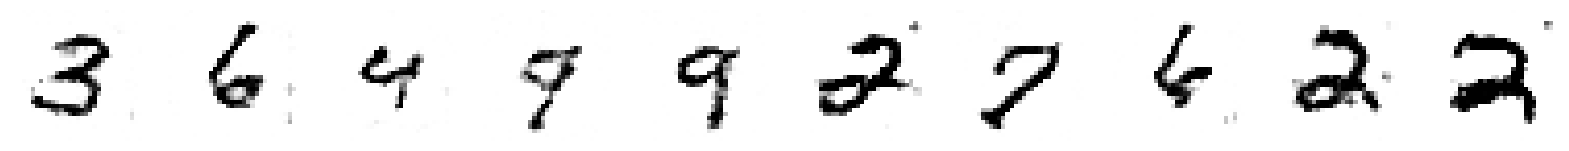


Saved to ./output/example_img_053.png


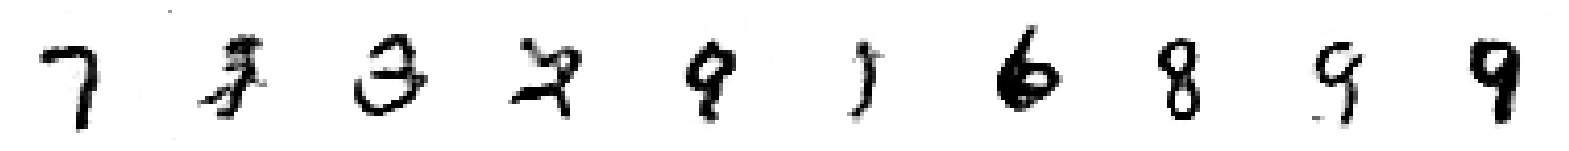

469/469 ━━━━━━━━━━━━━━━━━━━━ 758s 2s/step - cdiv: -9.9695e-05 - fake: 1.4129e-04 - loss: -5.8277e-06 - real: 2.4099e-04 - reg: 9.3867e-05 - val_cdiv: -19.6286 - val_fake: -19.6245 - val_real: 0.0042
Epoch 55/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.9753e-04 - fake: 3.6214e-04 - loss: -6.8064e-05 - real: 5.5967e-04 - reg: 1.2946e-04
Saved to ./output/generated_img_054.png


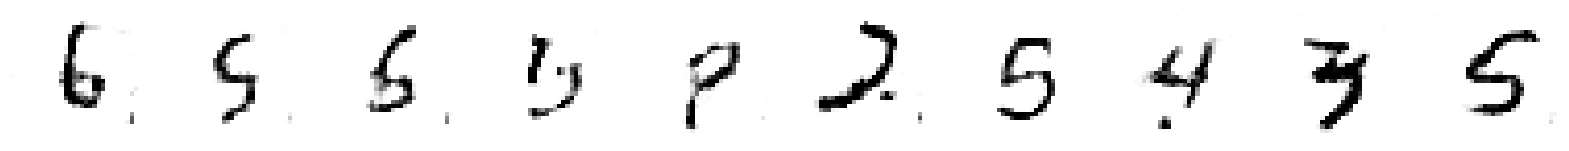


Saved to ./output/example_img_054.png


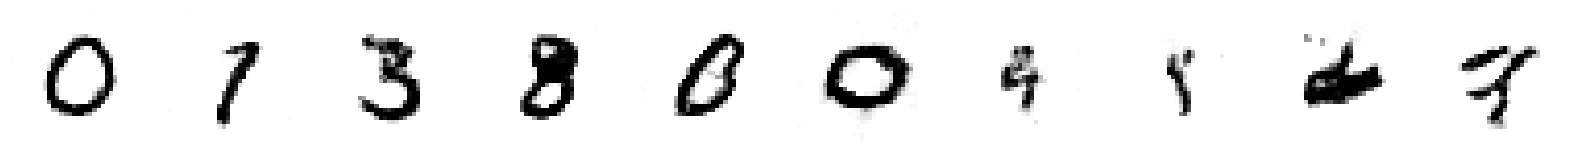

469/469 ━━━━━━━━━━━━━━━━━━━━ 770s 2s/step - cdiv: 7.4039e-05 - fake: 3.3835e-04 - loss: 1.7299e-04 - real: 2.6431e-04 - reg: 9.8955e-05 - val_cdiv: -19.8513 - val_fake: -19.8477 - val_real: 0.0036
Epoch 56/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -3.3799e-04 - fake: 2.7982e-04 - loss: -2.1588e-04 - real: 6.1781e-04 - reg: 1.2211e-04
Saved to ./output/generated_img_055.png


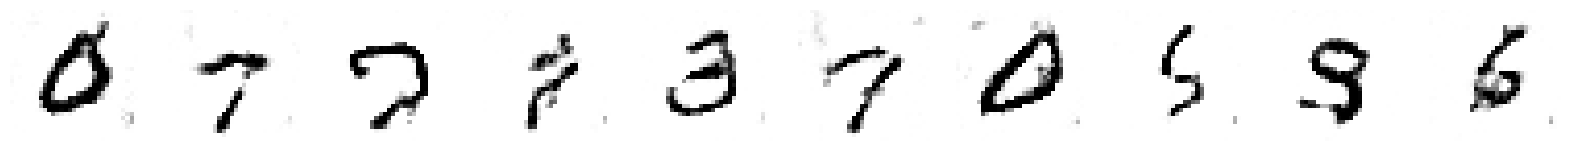


Saved to ./output/example_img_055.png


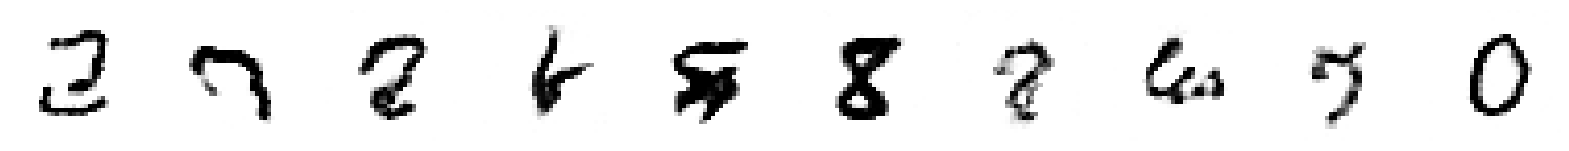

469/469 ━━━━━━━━━━━━━━━━━━━━ 772s 2s/step - cdiv: 1.1586e-04 - fake: 1.8829e-04 - loss: 2.1265e-04 - real: 7.2425e-05 - reg: 9.6788e-05 - val_cdiv: -20.0336 - val_fake: -20.0278 - val_real: 0.0059
Epoch 57/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -4.7389e-05 - fake: -1.5465e-05 - loss: 4.1098e-05 - real: 3.1924e-05 - reg: 8.8487e-05
Saved to ./output/generated_img_056.png


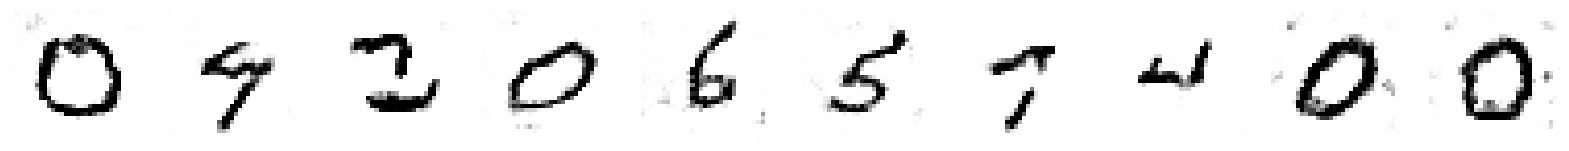


Saved to ./output/example_img_056.png


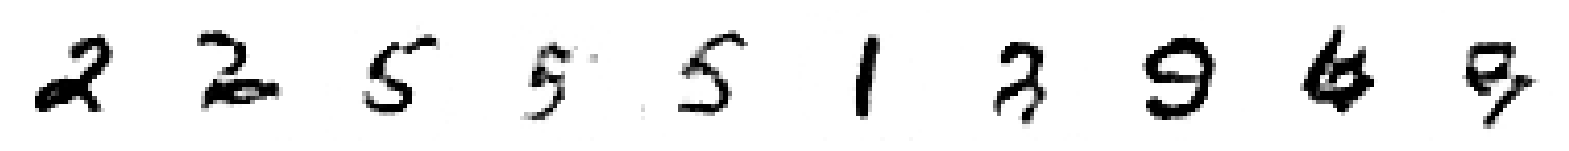

469/469 ━━━━━━━━━━━━━━━━━━━━ 761s 2s/step - cdiv: 9.3131e-05 - fake: 2.2971e-04 - loss: 1.7005e-04 - real: 1.3658e-04 - reg: 7.6921e-05 - val_cdiv: -20.4472 - val_fake: -20.4411 - val_real: 0.0061
Epoch 58/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.9690e-04 - fake: 3.3527e-04 - loss: -1.9599e-04 - real: 6.3218e-04 - reg: 1.0092e-04
Saved to ./output/generated_img_057.png


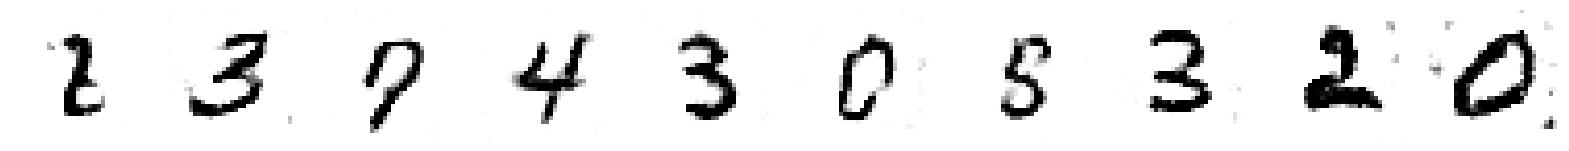


Saved to ./output/example_img_057.png


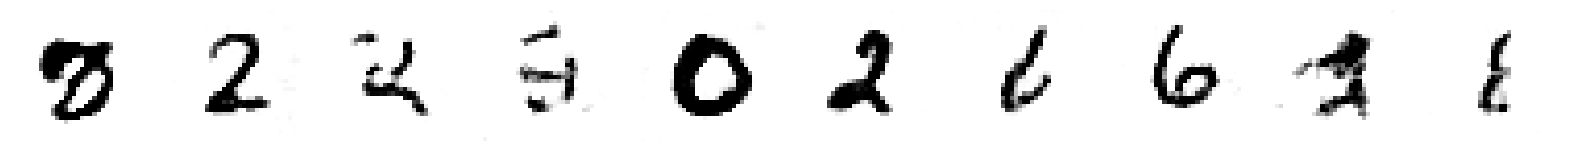

469/469 ━━━━━━━━━━━━━━━━━━━━ 759s 2s/step - cdiv: 3.1518e-05 - fake: 4.0027e-04 - loss: 1.2107e-04 - real: 3.6875e-04 - reg: 8.9556e-05 - val_cdiv: -20.4299 - val_fake: -20.4308 - val_real: -9.2365e-04
Epoch 59/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -1.7831e-04 - fake: 1.3931e-04 - loss: -8.1524e-05 - real: 3.1762e-04 - reg: 9.6789e-05
Saved to ./output/generated_img_058.png


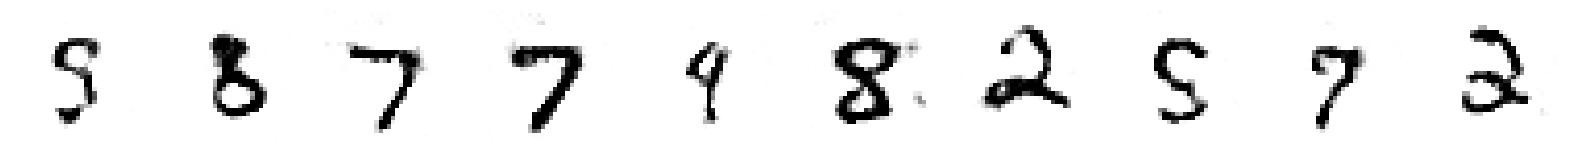


Saved to ./output/example_img_058.png


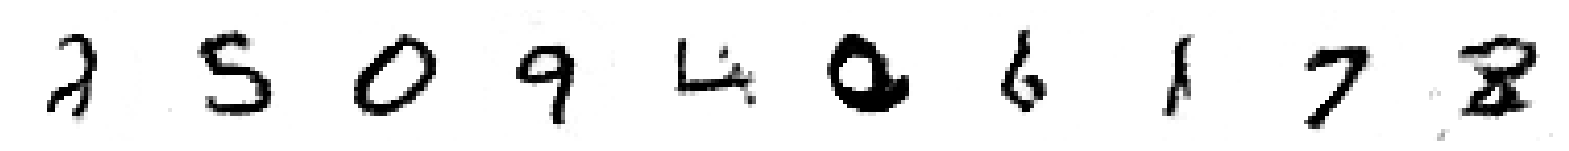

469/469 ━━━━━━━━━━━━━━━━━━━━ 756s 2s/step - cdiv: -5.6020e-05 - fake: 3.0052e-04 - loss: 4.5158e-05 - real: 3.5654e-04 - reg: 1.0118e-04 - val_cdiv: -20.2690 - val_fake: -20.2716 - val_real: -0.0025
Epoch 60/60
469/469 ━━━━━━━━━━━━━━━━━━━━ 0s 2s/step - cdiv: -2.0187e-05 - fake: -4.9165e-04 - loss: 8.4657e-05 - real: -4.7146e-04 - reg: 1.0484e-04
Saved to ./output/generated_img_059.png


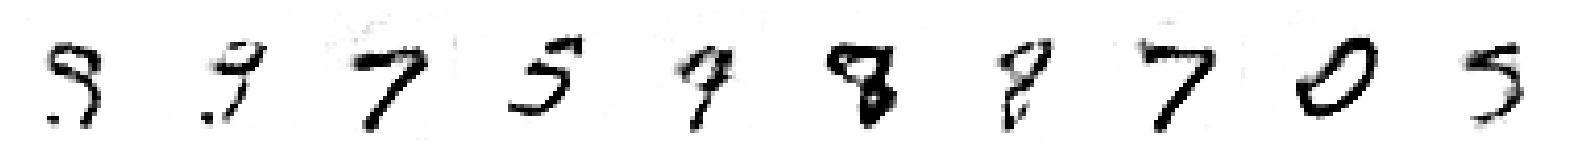


Saved to ./output/example_img_059.png


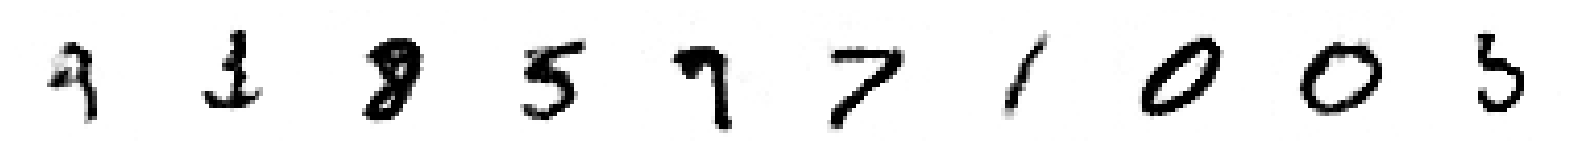

469/469 ━━━━━━━━━━━━━━━━━━━━ 757s 2s/step - cdiv: 1.8588e-04 - fake: 1.9097e-04 - loss: 2.6768e-04 - real: 5.0887e-06 - reg: 8.1792e-05 - val_cdiv: -20.6213 - val_fake: -20.6186 - val_real: 0.0027


In [ ]:
ebm.fit(
    x_train,
    shuffle=True,
    epochs=60,
    validation_data=x_test,
    callbacks=[
        save_model_callback,
        tensorboard_callback,
        image_generator_callback,
    ],
)

## 4. Generate images <a name="generate"></a>

In [35]:
start_imgs = (
    np.random.uniform(size=(10, IMAGE_SIZE, IMAGE_SIZE, CHANNELS)) * 2 - 1
)

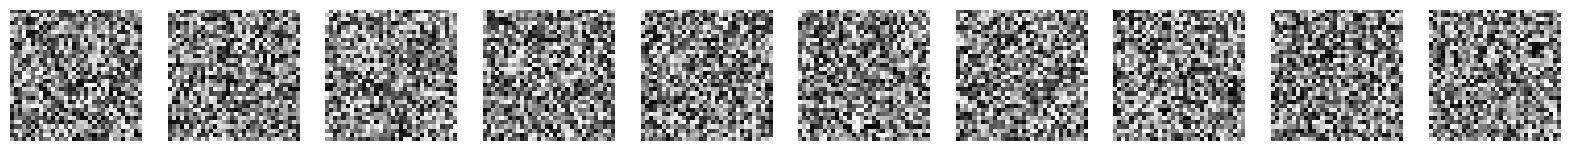

In [36]:
display(start_imgs)

In [37]:
gen_img = generate_samples(
    ebm.model,
    start_imgs,
    steps=1000,
    step_size=STEP_SIZE,
    noise=NOISE,
    return_img_per_step=True,
)

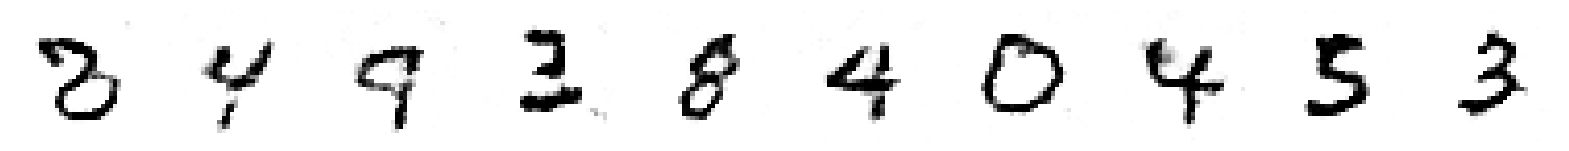

In [38]:
display(gen_img[-1].numpy())

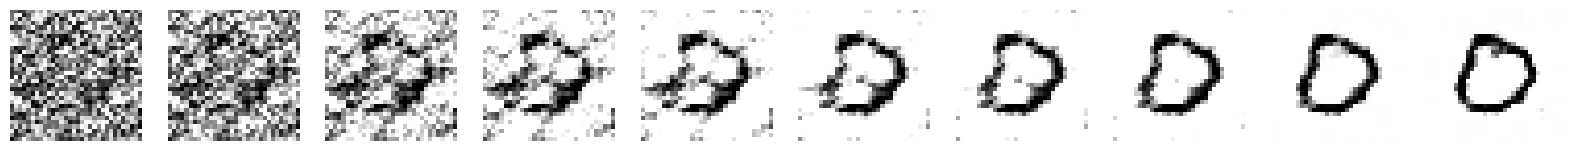

In [39]:
imgs = []
for i in [0, 1, 3, 5, 10, 30, 50, 100, 300, 999]:
    imgs.append(gen_img[i].numpy()[6])

display(np.array(imgs))